# PROJET DE ML II

## 1-Importation de la base de données 

In [157]:
import sys
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
import matplotlib.patches as mpatches
from scipy.stats import skew, kurtosis
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
import scipy.stats as stats
import plotly.express as px
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.stats import shapiro
import pingouin as pg
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_curve, 
    auc,
)
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [158]:
# Configuration pour l'ethtique les graphiques
sns.set_theme(style = "whitegrid")

# Pour forcer Pandas et Python à afficher toutes les lignese t tous les caractères
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)

# Pour s'assurer que Python ne limite pas la taille des chaines converties
sys.set_int_max_str_digits(500000)

In [159]:
# Chargement et apercu de de la base 
df = pd.read_csv("movie_metadata_1.csv", encoding = 'utf-8' )
display(df.head())

,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,actor_1_name,movie_title,num_voted_users,cast_total_facebook_likes,actor_3_name,facenumber_in_poster,plot_keywords,movie_imdb_link,num_user_for_reviews,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
0,Color,James Cameron,723.0,178.0,0.0,855.0,Joel David Moore,1000.0,760505847.0,Action|Adventure|Fantasy|Sci-Fi,CCH Pounder,Avatar,886204,4834,Wes Studi,0.0,avatar|future|marine|native|paraplegic,http://www.imdb.com/title/tt0499549/?ref_=fn_tt_tt_1,3054.0,English,USA,PG-13,237000000.0,2009.0,936.0,7.9,1.78,33000
1,Color,Gore Verbinski,302.0,169.0,563.0,1000.0,Orlando Bloom,40000.0,309404152.0,Action|Adventure|Fantasy,Johnny Depp,Pirates of the Caribbean: At World's End,471220,48350,Jack Davenport,0.0,goddess|marriage ceremony|marriage proposal|pirate|singapore,http://www.imdb.com/title/tt0449088/?ref_=fn_tt_tt_1,1238.0,English,USA,PG-13,300000000.0,2007.0,5000.0,7.1,2.35,0
2,Color,Sam Mendes,602.0,148.0,0.0,161.0,Rory Kinnear,11000.0,200074175.0,Action|Adventure|Thriller,Christoph Waltz,Spectre,275868,11700,Stephanie Sigman,1.0,bomb|espionage|sequel|spy|terrorist,http://www.imdb.com/title/tt2379713/?ref_=fn_tt_tt_1,994.0,English,UK,PG-13,245000000.0,2015.0,393.0,6.8,2.35,85000
3,Color,Christopher Nolan,813.0,164.0,22000.0,23000.0,Christian Bale,27000.0,448130642.0,Action|Thriller,Tom Hardy,The Dark Knight Rises,1144337,106759,Joseph Gordon-Levitt,0.0,deception|imprisonment|lawlessness|police officer|terrorist plot,http://www.imdb.com/title/tt1345836/?ref_=fn_tt_tt_1,2701.0,English,USA,PG-13,250000000.0,2012.0,23000.0,8.5,2.35,164000
4,NaN,Doug Walker,NaN,NaN,131.0,NaN,Rob Walker,131.0,NaN,Documentary,Doug Walker,Star Wars: Episode VII - The Force Awakens,8,143,NaN,0.0,NaN,http://www.imdb.com/title/tt5289954/?ref_=fn_tt_tt_1,NaN,NaN,NaN,NaN,NaN,NaN,12.0,7.1,NaN,0


In [160]:
df.shape

(5043, 28)

In [161]:
# Statistiques descriptives des variables quantitatives
display(df.describe())

,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_1_facebook_likes,gross,num_voted_users,cast_total_facebook_likes,facenumber_in_poster,num_user_for_reviews,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
count,4993.000000,5028.000000,4939.000000,5020.000000,5036.000000,4.159000e+03,5.043000e+03,5043.000000,5030.000000,5022.000000,4.551000e+03,4935.000000,5030.000000,5043.000000,4714.000000,5043.000000
mean,140.194272,107.201074,686.509212,645.009761,6560.047061,4.846841e+07,8.366816e+04,9699.063851,1.371173,272.770808,3.975262e+07,2002.470517,1651.754473,6.442138,2.220403,7525.964505
std,121.601675,25.197441,2813.328607,1665.041728,15020.759120,6.845299e+07,1.384853e+05,18163.799124,2.013576,377.982886,2.061149e+08,12.474599,4042.438863,1.125116,1.385113,19320.445110
min,1.000000,7.000000,0.000000,0.000000,0.000000,1.620000e+02,5.000000e+00,0.000000,0.000000,1.000000,2.180000e+02,1916.000000,0.000000,1.600000,1.180000,0.000000
25%,50.000000,93.000000,7.000000,133.000000,614.000000,5.340988e+06,8.593500e+03,1411.000000,0.000000,65.000000,6.000000e+06,1999.000000,281.000000,5.800000,1.850000,0.000000
50%,110.000000,103.000000,49.000000,371.500000,988.000000,2.551750e+07,3.435900e+04,3090.000000,1.000000,156.000000,2.000000e+07,2005.000000,595.000000,6.600000,2.350000,166.000000
75%,195.000000,118.000000,194.500000,636.000000,11000.000000,6.230944e+07,9.630900e+04,13756.500000,2.000000,326.000000,4.500000e+07,2011.000000,918.000000,7.200000,2.350000,3000.000000
max,813.000000,511.000000,23000.000000,23000.000000,640000.000000,7.605058e+08,1.689764e+06,656730.000000,43.000000,5060.000000,1.221550e+10,2016.000000,137000.000000,9.500000,16.000000,349000.000000


In [162]:
# Statistiques descriptives des variables catégorielles
display(df.describe(include= ["object", "category"]).T)

C:\Users\user\AppData\Local\Temp\ipykernel_7572\2488864432.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include= ["object", "category"]).T)


,count,unique,top,freq
color,5024,2,Color,4815
director_name,4939,2398,Steven Spielberg,26
actor_2_name,5030,3032,Morgan Freeman,20
genres,5043,914,Drama,236
actor_1_name,5036,2097,Robert De Niro,49
movie_title,5043,4917,King Kong,3
actor_3_name,5020,3521,Steve Coogan,8
plot_keywords,4890,4760,based on novel,4
movie_imdb_link,5043,4919,http://www.imdb.com/title/tt0360717/?ref_=fn_tt_tt_1,3
language,5029,46,English,4704


In [163]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5043 entries, 0 to 5042
Data columns (total 28 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   color                      5024 non-null   str    
 1   director_name              4939 non-null   str    
 2   num_critic_for_reviews     4993 non-null   float64
 3   duration                   5028 non-null   float64
 4   director_facebook_likes    4939 non-null   float64
 5   actor_3_facebook_likes     5020 non-null   float64
 6   actor_2_name               5030 non-null   str    
 7   actor_1_facebook_likes     5036 non-null   float64
 8   gross                      4159 non-null   float64
 9   genres                     5043 non-null   str    
 10  actor_1_name               5036 non-null   str    
 11  movie_title                5043 non-null   str    
 12  num_voted_users            5043 non-null   int64  
 13  cast_total_facebook_likes  5043 non-null   int64  
 14  act

# 2- Apurement de la base

## 2.1 - Changement des types des variables en leur type approprié et Vérification de l'intervalle de la title_year

In [164]:
# Affichage des types pour vérifier si les types sont appropriés
print( df.dtypes)

color                            str
director_name                    str
num_critic_for_reviews       float64
duration                     float64
director_facebook_likes      float64
actor_3_facebook_likes       float64
actor_2_name                     str
actor_1_facebook_likes       float64
gross                        float64
genres                           str
actor_1_name                     str
movie_title                      str
num_voted_users                int64
cast_total_facebook_likes      int64
actor_3_name                     str
facenumber_in_poster         float64
plot_keywords                    str
movie_imdb_link                  str
num_user_for_reviews         float64
language                         str
country                          str
content_rating                   str
budget                       float64
title_year                   float64
actor_2_facebook_likes       float64
imdb_score                   float64
aspect_ratio                 float64
m

In [165]:
# Conversion du type des colonnes en les types appropriés
df['movie_title'] = df['movie_title'].astype('category')
df['movie_title'] = df['movie_title'].str.strip()


int_cols = [ 'num_critic_for_reviews', 'director_facebook_likes', 'actor_1_facebook_likes',
            'actor_2_facebook_likes', 'actor_3_facebook_likes', 'cast_total_facebook_likes',  
            'num_voted_users', 'facenumber_in_poster', 'num_user_for_reviews', 'title_year'
            ]

for col in int_cols :
    # Retrait des caractères non numériques
    s = df[col].astype(str).str.replace(r'[^0-9\.-]', '', regex = True)
    # Les chaines vides seront Nan
    s = s.replace({'': np.nan})
    # Coerce a numérique
    df[col] = pd.to_numeric(s, errors = 'coerce').round().astype('Int64')


In [166]:
print( df.dtypes)

color                            str
director_name                    str
num_critic_for_reviews         Int64
duration                     float64
director_facebook_likes        Int64
actor_3_facebook_likes         Int64
actor_2_name                     str
actor_1_facebook_likes         Int64
gross                        float64
genres                           str
actor_1_name                     str
movie_title                   object
num_voted_users                Int64
cast_total_facebook_likes      Int64
actor_3_name                     str
facenumber_in_poster           Int64
plot_keywords                    str
movie_imdb_link                  str
num_user_for_reviews           Int64
language                         str
country                          str
content_rating                   str
budget                       float64
title_year                     Int64
actor_2_facebook_likes         Int64
imdb_score                   float64
aspect_ratio                 float64
m

In [167]:
annee_finale = 2016

#verification
valide = df['title_year'].dropna().between(1900, annee_finale).all()

print(valide)

True


## 2.2 - Supprésion des variables sans intérêts

In [168]:
df = df.drop(columns = ['movie_imdb_link'])
df.shape

(5043, 27)

La  variable movie_imdb_link a bien été supprimée, le nombre de variables est passé de 28 à 27.

## 2.3 - Identification et supprésion des doublons

### 2.3.1 - Doublons parfaits des lignes

In [169]:
doublons = df[df.duplicated(keep = False)]
print(f"le nombre de lignes impliquées dans des doublons : {len(doublons)}")

le nombre de lignes impliquées dans des doublons : 90


In [170]:
display(doublons.sort_values(by = 'movie_title').head(10))

,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,actor_1_name,movie_title,num_voted_users,cast_total_facebook_likes,actor_3_name,facenumber_in_poster,plot_keywords,num_user_for_reviews,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
4950,Color,David Hewlett,8,88.0,686,405,David Hewlett,847,NaN,Comedy,Christopher Judge,A Dog's Breakfast,3262,2364,Paul McGillion,2,dog|vegetarian,46,English,Canada,NaN,120000.0,2007,686,7.0,1.78,377
4949,Color,David Hewlett,8,88.0,686,405,David Hewlett,847,NaN,Comedy,Christopher Judge,A Dog's Breakfast,3262,2364,Paul McGillion,2,dog|vegetarian,46,English,Canada,NaN,120000.0,2007,686,7.0,1.78,377
4408,Color,Yimou Zhang,101,95.0,611,3,Ni Yan,9,190666.0,Comedy|Drama,Honglei Sun,"A Woman, a Gun and a Noodle Shop",2410,18,Dahong Ni,1,betrayal|husband wife relationship|murder|noodles|salary,20,Mandarin,China,R,NaN,2009,4,5.7,2.35,784
3007,Color,Yimou Zhang,101,95.0,611,3,Ni Yan,9,190666.0,Comedy|Drama,Honglei Sun,"A Woman, a Gun and a Noodle Shop",2410,18,Dahong Ni,1,betrayal|husband wife relationship|murder|noodles|salary,20,Mandarin,China,R,NaN,2009,4,5.7,2.35,784
2181,Color,Jon Lucas,81,100.0,24,851,Jay Hernandez,15000,55461307.0,Comedy,Mila Kunis,Bad Moms,4654,18786,Jada Pinkett Smith,9,lesbian kiss|mom|pta|reference to mad max|scene during end credits,46,English,USA,R,20000000.0,2016,1000,6.7,NaN,18000
2562,Color,Jon Lucas,81,100.0,24,851,Jay Hernandez,15000,55461307.0,Comedy,Mila Kunis,Bad Moms,4654,18786,Jada Pinkett Smith,9,lesbian kiss|mom|pta|reference to mad max|scene during end credits,46,English,USA,R,20000000.0,2016,1000,6.7,NaN,18000
2798,Color,Shawn Levy,69,88.0,189,799,Donald Faison,934,47811275.0,Adventure|Comedy|Family,Frankie Muniz,Big Fat Liar,29008,3707,Lee Majors,1,brunette|film producer|liar|prank|stunt,99,English,USA,PG,15000000.0,2002,927,5.4,1.85,896
2628,Color,Shawn Levy,69,88.0,189,799,Donald Faison,934,47811275.0,Adventure|Comedy|Family,Frankie Muniz,Big Fat Liar,29008,3707,Lee Majors,1,brunette|film producer|liar|prank|stunt,99,English,USA,PG,15000000.0,2002,927,5.4,1.85,896
4942,Color,Paul Schrader,130,93.0,261,697,Ruby Dee,783,NaN,Fantasy|Horror|Thriller,Ed Begley Jr.,Cat People,14193,3700,John Heard,1,cat|cat people|leopard|love|slip the undergarment,106,English,USA,R,18000000.0,1982,782,6.1,1.85,0
2902,Color,Paul Schrader,130,93.0,261,697,Ruby Dee,783,NaN,Fantasy|Horror|Thriller,Ed Begley Jr.,Cat People,14193,3700,John Heard,1,cat|cat people|leopard|love|slip the undergarment,106,English,USA,R,18000000.0,1982,782,6.1,1.85,0


Ces doublons proviennent probablement du web scraping lors de la création de la base

In [171]:
# Supprésion des doublons 
nb_lignes_avant = df.shape[0]
df = df.drop_duplicates(keep = 'first')
nb_lignes_apres = df.shape[0]
print(f"Le nombre de doublons supprimés est  {nb_lignes_avant - nb_lignes_apres}")

Le nombre de doublons supprimés est  45


### 2.3.2 - Doublons des films

Comme il s'agit d'une base scrapé, un même film peut apparaître deux fois avec un nombre de likes ou de votes différent selon l'heure de capture.

In [172]:
# Définition de la clé unique pour un film
cles_uniques = ['movie_title', 'title_year', 'director_name']

# Comptage du nombre de doublons sur cette clé
nb_doublons_film = df.duplicated(subset = cles_uniques, keep = 'first').sum()

print (f"le nombre de doublons pour les mêmes films est  {nb_doublons_film} ")

le nombre de doublons pour les mêmes films est  79 


Il y a bien des doublons par film. 

In [173]:
# Detection des variables ou il y'a la différence entre les doublons
df_doublons = df[ df.duplicated(subset = cles_uniques, keep = False)].copy()
groupes_doublons = df_doublons.groupby(cles_uniques, dropna = False)

rapport_differences = []

for cles , groupe in groupes_doublons : 
    titre, annee, realisateur = cles

    colonnes_variables = []

    #On teste chaque colonne du dataset ( sauf nos clés)
    for col in df.columns : 
        if col not in cles_uniques : 
            # Si le nombre de valeurs uniques dans cette colonne pour ce film est > 1
            # cela signifie que les lignes ne sont pas d'accord entre elles.
            if groupe[col].nunique(dropna=False)>1 : 
                colonnes_variables.append(col)
    
    # Enregistrement du résultat pour ce film
    rapport_differences.append({
        'Film' : titre.strip(),
        "Année" : annee,
        "Réalisateur" : realisateur,
        "Nombre de replications" : len(groupe),
        "Nombre de variables qui diffèrent" : len(colonnes_variables),
        "Variables qui diffèrent": colonnes_variables
    })
df_rapport_diff = pd.DataFrame(rapport_differences)




In [174]:
display(df_rapport_diff.sort_values(by = 'Nombre de variables qui diffèrent').head(5))

,Film,Année,Réalisateur,Nombre de replications,Nombre de variables qui diffèrent,Variables qui diffèrent
1,A Nightmare on Elm Street,1984,Wes Craven,2,1,[num_voted_users]
2,Across the Universe,2007,Julie Taymor,2,1,[num_voted_users]
3,Alice in Wonderland,2010,Tim Burton,2,1,[num_voted_users]
4,Aloha,2015,Cameron Crowe,2,1,[num_voted_users]
5,Around the World in 80 Days,2004,Frank Coraci,2,1,[num_voted_users]


In [175]:
display(df_rapport_diff.sort_values(by = 'Nombre de variables qui diffèrent').tail(5))

,Film,Année,Réalisateur,Nombre de replications,Nombre de variables qui diffèrent,Variables qui diffèrent
34,Lolita,1962,Stanley Kubrick,2,3,"[actor_1_facebook_likes, num_voted_users, cast_total_facebook_likes]"
72,The Watch,2012,Akiva Schaffer,2,3,"[actor_3_facebook_likes, num_voted_users, cast_total_facebook_likes]"
74,Unknown,2011,Jaume Collet-Serra,2,3,"[num_voted_users, cast_total_facebook_likes, actor_2_facebook_likes]"
7,Brothers,2009,Jim Sheridan,2,4,"[actor_3_facebook_likes, num_voted_users, cast_total_facebook_likes, actor_3_name]"
6,Ben-Hur,2016,Timur Bekmambetov,3,6,"[num_voted_users, cast_total_facebook_likes, plot_keywords, budget, actor_2_facebook_likes, imdb_score]"


##### Gestion du traitement des doublons cas par cas  de combinaisons  de variables de différences entre les observations des films

In [176]:
# Determiner des combinaisons de différences entre les doublons par film et leur fréquenc

combinaisons_uniques = df_rapport_diff["Variables qui diffèrent"].apply(tuple).value_counts()
print(combinaisons_uniques)

Variables qui diffèrent
(num_voted_users,)                                                                                         51
(num_voted_users, cast_total_facebook_likes, actor_2_facebook_likes)                                        6
(num_voted_users, cast_total_facebook_likes)                                                                6
(actor_3_facebook_likes, num_voted_users, cast_total_facebook_likes)                                        5
(actor_1_facebook_likes, num_voted_users, cast_total_facebook_likes)                                        3
(num_voted_users, cast_total_facebook_likes, plot_keywords, budget, actor_2_facebook_likes, imdb_score)     1
(actor_3_facebook_likes, num_voted_users, cast_total_facebook_likes, actor_3_name)                          1
(cast_total_facebook_likes,)                                                                                1
(num_voted_users, num_user_for_reviews)                                                         

#### 2.3.1.1 - Traitement du cas 1 - Différence unique sur 'num_voted_users' :



On va conserver la ligne du film qui possède le plus grand nombre de votes 

CAR cela signifie que c'est la donnée la plus récente collectée au moment ou le film avait accumulé le plus d'avis sur IMDb

In [177]:
masque_cas1 = df_rapport_diff['Variables qui diffèrent'].apply(lambda x: x == ['num_voted_users'])
films_cas1 = df_rapport_diff[masque_cas1]

# Liste pour stocker les index des lignes à supprimer
indices_a_supprimer = []

for _, row in films_cas1.iterrows():
    titre = row['Film']
    annee = row['Année']
    realisateur = row['Réalisateur']

    # Construction du filtre dynamique dans le df principal ( gestion rogoureuse des NaN)
    cond_titre = df['movie_title'] == titre
    cond_annee = df['title_year'].isna() if pd.isna(annee) else df['title_year'] == annee
    cond_real = df['director_name'].isna() if pd.isna(realisateur) else df['director_name'] == realisateur

    # Extravtion des lignes dupliquées pour ce film précis
    sous_groupe = df[cond_titre & cond_annee & cond_real]

    # On selectionne l'index de la ligne qui a le MAXIMUM de votes
    idx_a_garder = sous_groupe['num_voted_users'].idxmax()

    # On recupere les indes de totes les AUTRES  lignes (les copies moins recentes)
    idx_a_jeter = sous_groupe.index[sous_groupe.index != idx_a_garder]

    #On les ajouter à notre liste globale de supprésion
    indices_a_supprimer.extend(idx_a_jeter)

# Suppression des lignes moins recentes
df_nettoye = df.drop(indices_a_supprimer)

print(f" Nombre de lignes obsolètes supprimés :  {len(indices_a_supprimer)}")
print(f" Dimensions de la base après ce Cas 1 :  {df_nettoye.shape[0]} lignes.")


df = df_nettoye.reset_index(drop = True)


 Nombre de lignes obsolètes supprimés :  52
 Dimensions de la base après ce Cas 1 :  4946 lignes.


#### 2.3.1.2 - Traitement du cas 2 - Différence unique sur 'cast_total_facebook_likes' 

 On applique le même principe du MAXIMUM que pour le cas 1
 

In [178]:
masque_cas2 = df_rapport_diff['Variables qui diffèrent'].apply(lambda x: x == ['cast_total_facebook_likes'])
films_cas2 = df_rapport_diff[masque_cas2]

# Liste pour stocker les index des lignes à supprimer
indices_a_supprimer = []

for _, row in films_cas2.iterrows():
    titre = row['Film']
    annee = row['Année']
    realisateur = row['Réalisateur']

    # Construction du filtre dynamique dans le df principal ( gestion rogoureuse des NaN)
    cond_titre = df['movie_title'] == titre
    cond_annee = df['title_year'].isna() if pd.isna(annee) else df['title_year'] == annee
    cond_real = df['director_name'].isna() if pd.isna(realisateur) else df['director_name'] == realisateur

    # Extravtion des lignes dupliquées pour ce film précis
    sous_groupe = df[cond_titre & cond_annee & cond_real]

    # On selectionne l'index de la ligne qui a le MAXIMUM de votes
    idx_a_garder = sous_groupe['cast_total_facebook_likes'].idxmax()

    # On recupere les indes de totes les AUTRES  lignes (les copies moins recentes)
    idx_a_jeter = sous_groupe.index[sous_groupe.index != idx_a_garder]

    #On les ajouter à notre liste globale de supprésion
    indices_a_supprimer.extend(idx_a_jeter)

# Suppression des lignes moins recentes
df_nettoye = df.drop(indices_a_supprimer)

print(f" Nombre de lignes obsolètes supprimés :  {len(indices_a_supprimer)}")
print(f" Dimensions de la base après ce Cas 2 :  {df_nettoye.shape[0]} lignes.")


df = df_nettoye.reset_index(drop = True)


 Nombre de lignes obsolètes supprimés :  1
 Dimensions de la base après ce Cas 2 :  4945 lignes.


#### 2.3.1.3 - Traitement du Cas 3 :  Différence sur seules variables "num_voted_users" et "cast_total_facebook_likes"

In [179]:
# Inspection des différences 

cible_cas3 = {'num_voted_users', 'cast_total_facebook_likes'}

# filtrage du rapport pour trouver les films correspondants
masque_cas3 = df_rapport_diff['Variables qui diffèrent'].apply(lambda x: set(x) == cible_cas3)
films_cas3 = df_rapport_diff[masque_cas3]

print(f"Nombre de films identifiés dans le cas 3 :{len(films_cas3)}")

display(films_cas3[['Film', 'Année', 'Réalisateur', 'Nombre de replications']])

# Recupération des titres
titres_cas3 = films_cas3['Film'].tolist ()

# Selection des colonnes d'intérêt pour l'analyse visuelle
colonnes_analyse = ['movie_title', 'title_year', 'director_name', 'num_voted_users', 'cast_total_facebook_likes']

# Extraction et tri pour justaposer les doublons côté à côté
affichage_cas3 = df[df['movie_title'].isin(titres_cas3)][colonnes_analyse].sort_values(by = 'movie_title')

display(affichage_cas3)


Nombre de films identifiés dans le cas 3 :6


,Film,Année,Réalisateur,Nombre de replications
30,House of Wax,2005,Jaume Collet-Serra,2
44,RoboCop,2014,José Padilha,2
52,TRON: Legacy,2010,Joseph Kosinski,2
57,The Fog,1980,John Carpenter,2
61,The Island,2005,Michael Bay,2
73,Twilight,2008,Catherine Hardwicke,2


,movie_title,title_year,director_name,num_voted_users,cast_total_facebook_likes
1410,House of Wax,2005,Jaume Collet-Serra,94456,2178
4603,House of Wax,2005,Jaume Collet-Serra,94463,2160
219,RoboCop,2014,José Padilha,182899,14161
2765,RoboCop,2014,José Padilha,182910,14160
36,TRON: Legacy,2010,Joseph Kosinski,264183,25550
2439,TRON: Legacy,2010,Joseph Kosinski,264186,25549
2364,The Fog,1980,John Carpenter,46492,4877
4443,The Fog,1980,John Carpenter,46493,4878
266,The Island,2005,Michael Bay,263329,34839
2051,The Island,2005,Michael Bay,263336,34838


On constate que la ligne qui a le plus de num_votes_users n'est pas toujours celle qui a le plus de cast_total_facebook_likes. 

Plusieurs raisons peuvent expliquer cela. La première raison est 
 * le nettoyage de Facebook supprimant les faux comptes ait eu lieu entre les deux périodes ;
 * Le bug de scraping de cast_total_facebook_likes : cast_total_facebook_likes est la somme des likes de plusieurs acteurs. Il a pu avoir eu une erreur lors du scraping.

Or sur IMDb, le nombre de votes est croissant et cumulatif, donc l'observation la plus recente est celle qui a le num_votes_users le plus grand.

In [180]:
# Résolution du cas 3
indices_a_supprimer_cas3 = []

for _, row in films_cas3.iterrows():
    titre = row['Film']
    annee = row['Année']
    realisateur = row['Réalisateur']

    # Construction du filtre dynamique dans le df principal ( gestion rogoureuse des NaN)
    cond_titre = df['movie_title'] == titre
    cond_annee = df['title_year'].isna() if pd.isna(annee) else df['title_year'] == annee
    cond_real = df['director_name'].isna() if pd.isna(realisateur) else df['director_name'] == realisateur

    # Extravtion des lignes dupliquées pour ce film précis
    sous_groupe = df[cond_titre & cond_annee & cond_real]

    # On selectionne l'index de la ligne qui a le MAXIMUM de votes
    idx_a_garder = sous_groupe['num_voted_users'].idxmax()

    # On recupere les indes de totes les AUTRES  lignes (les copies moins recentes)
    idx_a_jeter = sous_groupe.index[sous_groupe.index != idx_a_garder]

    #On les ajouter à notre liste globale de supprésion
    indices_a_supprimer_cas3.extend(idx_a_jeter)

# Suppression des lignes moins recentes
df_nettoye = df.drop(indices_a_supprimer_cas3)

print(f" Nombre de lignes obsolètes supprimés :  {len(indices_a_supprimer_cas3)}")
print(f" Dimensions de la base après ce Cas 3 :  {df_nettoye.shape[0]} lignes.")


df = df_nettoye.reset_index(drop = True)

 Nombre de lignes obsolètes supprimés :  6
 Dimensions de la base après ce Cas 3 :  4939 lignes.


#### 2.3.1.4 - Traitement du Cas 4 :  Différence sur les combinaisons de variables de votes contenant "num_voted_users" mais différents des cas 1 et 3

Il s'agit des combinaisons de variables suivantes : 
* (actor_2_facebook_likes, num_voted_users, cast_total_facebook_likes);
* (actor_3_facebook_likes, num_voted_users, cast_total_facebook_likes);
* (actor_1_facebook_likes, num_voted_users, cast_total_facebook_likes);
* (num_user_for_reviews, num_voted_users) ;
* (actor_1_facebook_likes, actor_3_facebook_likes, cast_total_facebook_likes)

On remarque que la variable "num_voted_users" est la plus apte a nous dire quelle ligne est plus recente. Donc pour ces cas, nous allons choisir la ligne qui le num_voted_users plus élévé

In [181]:
# Inspection des différences
 
# filtrage du rapport pour trouver les films correspondants
masque_cas4 = df_rapport_diff['Variables qui diffèrent'].apply(lambda x:  set(x) == {'actor_2_facebook_likes', 'num_voted_users', 'cast_total_facebook_likes'} 
                                                               or set(x) == {'actor_3_facebook_likes', 'num_voted_users', 'cast_total_facebook_likes'}
                                                               or set(x) == {'actor_1_facebook_likes', 'num_voted_users', 'cast_total_facebook_likes'}
                                                               or set(x) == {'num_user_for_reviews', 'num_voted_users'}
                                                               or set(x) == {'actor_1_facebook_likes', 'actor_3_facebook_likes', 'cast_total_facebook_likes'})
films_cas4 = df_rapport_diff[masque_cas4]

print(f"Nombre de films identifiés dans le cas 4 :{len(films_cas4)}")

display(films_cas4[['Film', 'Année', 'Réalisateur', 'Nombre de replications']])

# Recupération des titres
titres_cas4 = films_cas4['Film'].tolist ()

# Selection des colonnes d'intérêt pour l'analyse visuelle
colonnes_analyse = ['movie_title', 'title_year', 'director_name', 'num_voted_users', 'actor_1_facebook_likes', 'actor_2_facebook_likes', 'actor_3_facebook_likes',  'cast_total_facebook_likes', 'num_user_for_reviews']

# Extraction et tri pour justaposer les doublons côté à côté
affichage_cas4 = df[df['movie_title'].isin(titres_cas4)][colonnes_analyse].sort_values(by = 'movie_title')

display(affichage_cas4)


Nombre de films identifiés dans le cas 4 :16


,Film,Année,Réalisateur,Nombre de replications
0,"20,000 Leagues Under the Sea",1954,Richard Fleischer,2
11,Cinderella,2015,Kenneth Branagh,2
18,Disturbia,2007,D.J. Caruso,2
22,Exodus: Gods and Kings,2014,Ridley Scott,2
33,King Kong,2005,Peter Jackson,3
34,Lolita,1962,Stanley Kubrick,2
36,Mercury Rising,1998,Harold Becker,2
37,Murder by Numbers,2002,Barbet Schroeder,2
39,Pan,2015,Joe Wright,2
43,Precious,2009,Lee Daniels,2


,movie_title,title_year,director_name,num_voted_users,actor_1_facebook_likes,actor_2_facebook_likes,actor_3_facebook_likes,cast_total_facebook_likes,num_user_for_reviews
4794,"20,000 Leagues Under the Sea",1954,Richard Fleischer,22124,618,53,51,800,108
3624,"20,000 Leagues Under the Sea",1954,Richard Fleischer,22123,617,53,51,799,108
4051,Cinderella,2015,Kenneth Branagh,103749,2000,520,502,4671,323
314,Cinderella,2015,Kenneth Branagh,103737,2000,520,502,4671,322
2107,Disturbia,2007,D.J. Caruso,186984,884,617,501,2287,491
1279,Disturbia,2007,D.J. Caruso,186982,884,617,502,2288,491
3803,Exodus: Gods and Kings,2014,Ridley Scott,128694,23000,892,748,26489,657
150,Exodus: Gods and Kings,2014,Ridley Scott,128682,23000,893,748,26490,657
1991,King Kong,2005,Peter Jackson,316020,6000,918,84,7122,2618
4596,King Kong,2005,Peter Jackson,316027,6000,918,84,7122,2618


In [182]:
# Résolution du cas 4
indices_a_supprimer_cas4 = []

for _, row in films_cas4.iterrows():
    titre = row['Film']
    annee = row['Année']
    realisateur = row['Réalisateur']

    # Construction du filtre dynamique dans le df principal ( gestion rogoureuse des NaN)
    cond_titre = df['movie_title'] == titre
    cond_annee = df['title_year'].isna() if pd.isna(annee) else df['title_year'] == annee
    cond_real = df['director_name'].isna() if pd.isna(realisateur) else df['director_name'] == realisateur

    # Extravtion des lignes dupliquées pour ce film précis
    sous_groupe = df[cond_titre & cond_annee & cond_real]

    # On selectionne l'index de la ligne qui a le MAXIMUM de votes
    idx_a_garder = sous_groupe['num_voted_users'].idxmax()

    # On recupere les indes de totes les AUTRES  lignes (les copies moins recentes)
    idx_a_jeter = sous_groupe.index[sous_groupe.index != idx_a_garder]

    #On les ajouter à notre liste globale de supprésion
    indices_a_supprimer_cas4.extend(idx_a_jeter)

# Suppression des lignes moins recentes
df_nettoye = df.drop(indices_a_supprimer_cas4)

print(f" Nombre de lignes obsolètes supprimés :  {len(indices_a_supprimer_cas4)}")
print(f" Dimensions de la base après ce Cas 4 :  {df_nettoye.shape[0]} lignes.")


df = df_nettoye.reset_index(drop = True)

 Nombre de lignes obsolètes supprimés :  17
 Dimensions de la base après ce Cas 4 :  4922 lignes.


#### 2.3.1.5 - Traitement du Cas 5 :  Différence sur la combinaison de variable (plot_keywords, budget, actor_2_facebook_likes, num_voted_users, cast_total_facebook_likes, imdb_score)

In [183]:
# Inspection des différences
 
# filtrage du rapport pour trouver les films correspondants
masque_cas5 = df_rapport_diff['Variables qui diffèrent'].apply(lambda x:  set(x) == {'plot_keywords', 'budget', 'actor_2_facebook_likes', 'num_voted_users', 'cast_total_facebook_likes', 'imdb_score'} )
films_cas5 = df_rapport_diff[masque_cas5]

print(f"Nombre de films identifiés dans le cas 5 :{len(films_cas5)}")

display(films_cas5[['Film', 'Année', 'Réalisateur', 'Nombre de replications']])

# Recupération des titres
titres_cas5 = films_cas5['Film'].tolist ()

# Selection des colonnes d'intérêt pour l'analyse visuelle
colonnes_analyse = ['movie_title', 'title_year', 'director_name', 'plot_keywords', 'budget', 'actor_2_facebook_likes', 'num_voted_users', 'cast_total_facebook_likes', 'imdb_score']

# Extraction et tri pour justaposer les doublons côté à côté
affichage_cas5 = df[df['movie_title'].isin(titres_cas5)][colonnes_analyse].sort_values(by = 'movie_title')

display(affichage_cas5)


Nombre de films identifiés dans le cas 5 :1


,Film,Année,Réalisateur,Nombre de replications
6,Ben-Hur,2016,Timur Bekmambetov,3


,movie_title,title_year,director_name,plot_keywords,budget,actor_2_facebook_likes,num_voted_users,cast_total_facebook_likes,imdb_score
339,Ben-Hur,2016,Timur Bekmambetov,NaN,NaN,745,57,13379,6.1
2527,Ben-Hur,2016,Timur Bekmambetov,chariot race|epic|false accusation|jerusalem|slave,100000000.0,744,62,13390,6.1
3860,Ben-Hur,2016,Timur Bekmambetov,chariot race|epic|false accusation|jerusalem|slave,100000000.0,744,67,13391,6.0


* On va supprimer la ligne 339 car elle a des valeurs manquantes pour 'plot_keywords' et 'budget' des variables indispensables pour la suite de l'analyse.

* Pour départager entre les lignes 2527 et 3860, on va tout d'abord observer si les plot_keywords sont les mêmes. Dans le cas, on mettre le même plot_keywords le plus grand dans les deux lignes 

In [184]:
# Vérification de la similarité des plot_keywords
affichage_cas5.iloc[1]['plot_keywords'] == affichage_cas5.iloc[2]['plot_keywords']

True

Les plot_keywords sont identiques. On va selectionner la ligne 3860 car c'est elle qui a le num_votes_users ( et même le cast_total_facebook_likes) le plus élevé

In [185]:
# Supprésion des index 339 et 2527

indices_cas5 = [339, 2527]

df = df.drop(index = indices_cas5).reset_index(drop = True)

print(f" Lignes {indices_cas5} supprimées")
print(f" Nouvelles dimensions de la base :{df.shape[0]} lignes.")

 Lignes [339, 2527] supprimées
 Nouvelles dimensions de la base :4920 lignes.


#### 2.3.1.6 - Traitement du Cas 6 :  Différence sur la combinaison de variable (actor_3_name, actor_3_facebook_likes, num_voted_users, cast_total_facebook_likes)

In [186]:
# Inspection des différences
 
# filtrage du rapport pour trouver les films correspondants


masque_cas6 = df_rapport_diff['Variables qui diffèrent'].apply(lambda x:  set(x) == {'actor_3_name', 'actor_3_facebook_likes', 'num_voted_users', 'cast_total_facebook_likes'} )
films_cas6 = df_rapport_diff[masque_cas6]

print(f"Nombre de films identifiés dans le cas 6 :{len(films_cas6)}")

display(films_cas6[['Film', 'Année', 'Réalisateur', 'Nombre de replications']])

# Recupération des titres
titres_cas6 = films_cas6['Film'].tolist ()

# Selection des colonnes d'intérêt pour l'analyse visuelle
colonnes_analyse = ['movie_title', 'title_year', 'director_name', 'actor_3_name', 'actor_3_facebook_likes', 'num_voted_users', 'cast_total_facebook_likes']

# Extraction et tri pour justaposer les doublons côté à côté
affichage_cas6 = df[df['movie_title'].isin(titres_cas6)][colonnes_analyse].sort_values(by = 'movie_title')

display(affichage_cas6)


Nombre de films identifiés dans le cas 6 :1


,Film,Année,Réalisateur,Nombre de replications
7,Brothers,2009,Jim Sheridan,2


,movie_title,title_year,director_name,actor_3_name,actor_3_facebook_likes,num_voted_users,cast_total_facebook_likes
1781,Brothers,2009,Jim Sheridan,Bailee Madison,3000,88035,42473
2787,Brothers,2009,Jim Sheridan,Ethan Suplee,1000,88037,39473


On remarque les noms de l'acteur/actrice numéro 3 a changé au cours du temps passant de Bailee Madison (3000 likes) à Ethan Suplee(1000 likes). 
Cela est possible car la liste des acteurs sur la page principale d'un film sur IMDb n'est pas figée. Elle peut changer dynamiquement selon l'actualité des acteurs ou des mises à jour de l'algorithme d'IMDb.
En se basant sur num_voted_users, on conclut que la ligne la plus récente est ligne de l'acteur Ethan Suplee. C'est donc elle qu'on va conserver.

In [187]:
# Supprésion de l'index 1781

indices_cas6 = 1781

df = df.drop(index = indices_cas6).reset_index(drop = True)

print(f" Ligne {indices_cas6} supprimée")
print(f" Nouvelles dimensions de la base :{df.shape[0]} lignes.")

 Ligne 1781 supprimée
 Nouvelles dimensions de la base :4919 lignes.


## 2.4 - Identification et Traitement des valeurs abérrantes

In [188]:
#Variables quantitatives
df.describe()

,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_1_facebook_likes,gross,num_voted_users,cast_total_facebook_likes,facenumber_in_poster,num_user_for_reviews,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
count,4870.0,4904.000000,4817.0,4896.0,4912.0,4.056000e+03,4919.0,4919.0,4906.0,4898.0,4.435000e+03,4813.0,4906.0,4919.000000,4593.000000,4919.000000
mean,138.010267,107.089111,690.705418,630.551879,6490.876018,4.762156e+07,82618.323236,9574.03517,1.376478,267.603716,3.930191e+07,2002.445045,1621.072972,6.437853,2.222105,7345.293556
std,120.253857,25.278583,2832.107042,1625.084693,15103.081752,6.736387e+07,138285.920098,18158.940447,2.023493,372.839185,2.085364e+08,12.45346,4010.222163,1.127613,1.402514,19200.708189
min,1.0,7.000000,0.0,0.0,0.0,1.620000e+02,5.0,0.0,0.0,1.0,2.180000e+02,1916.0,0.0,1.600000,1.180000,0.000000
25%,49.0,93.000000,7.0,132.0,607.0,5.008728e+06,8356.5,1394.0,0.0,64.0,6.000000e+06,1999.0,277.0,5.800000,1.850000,0.000000
50%,108.0,103.000000,48.0,365.5,982.0,2.503566e+07,33158.0,3044.0,1.0,153.5,1.990000e+07,2005.0,593.0,6.600000,2.350000,160.000000
75%,191.0,118.000000,190.0,633.0,11000.0,6.109941e+07,93757.5,13611.5,2.0,320.0,4.300000e+07,2011.0,912.0,7.200000,2.350000,2000.000000
max,813.0,511.000000,23000.0,23000.0,640000.0,7.605058e+08,1689764.0,656730.0,43.0,5060.0,1.221550e+10,2016.0,137000.0,9.500000,16.000000,349000.000000


* On remarque que certains films ont des durées inférieures à 60 min allant même à 7. Or, généralement ce sont des épisodes des séries qui sont comme ca, avec les courts-métrages et les documentaires. 

* L'examen approfondi de la base montre que les films d'au plus 60 min sont des episodes des séries sauf pour 16 exceptions. Les inclus dans l'analyse biaisera les résultats et les recommandations.

In [189]:
df.duration.value_counts()

duration
90.0     160
100.0    138
98.0     135
101.0    132
97.0     131
93.0     125
99.0     123
94.0     122
95.0     121
96.0     111
102.0    106
107.0    106
106.0    105
105.0    101
92.0     101
104.0    100
91.0     100
103.0     99
110.0     99
88.0      97
89.0      93
109.0     91
108.0     89
112.0     80
120.0     75
115.0     74
87.0      74
118.0     73
111.0     70
113.0     68
114.0     66
116.0     65
86.0      63
117.0     60
123.0     59
121.0     59
124.0     58
119.0     58
122.0     54
85.0      53
84.0      51
125.0     50
83.0      42
129.0     40
130.0     39
82.0      39
80.0      39
127.0     38
135.0     35
128.0     35
81.0      33
132.0     31
126.0     30
134.0     30
131.0     28
133.0     27
60.0      26
136.0     23
138.0     21
141.0     20
139.0     20
140.0     19
142.0     17
150.0     16
143.0     14
144.0     14
76.0      14
137.0     13
145.0     13
78.0      13
153.0     12
146.0     12
30.0      12
75.0      12
148.0     11
154.0     11
77.

### Supprésion des séries dans la base

In [190]:
# Liste des films d'au plus 60 min qui sont réellement des films

reel_films = [
    "The Touch",
    "Dolphins and Whales 3D: Tribes of the Ocean",
    "Sea Rex 3D: Journey to a Prehistoric World",
    "Marilyn Hotchkiss' Ballroom Dancing and Charm School",
    "Wal-Mart: The High Cost of Low Price",
    "Vessel",
    "Jesus People",
    "A Charlie Brown Christmas", 
    "Flame and Citron",
    "Michael Jordan to the Max",
    "Alpha and Omega 4: The Legend of the Saw Toothed Cave",
    "Taxi to the Dark Side",
    "Rise of the Entrepreneur: The Search for a Better Way",
    "The Case of the Grinning Cat",
    "The Call of Cthulhu",
    "Stories of Our Lives"
]

taille_initiale = len(df)

# Selection des films qui sont réellement des films
condition_reelle_film = (df['duration'] > 60) | (df['movie_title'].isin(reel_films))

# Application du filtre sur la base df
df = df[condition_reelle_film].copy()

# Résultat
lignes_supprimees = taille_initiale - len(df)
print(f"Il reste maintenant uniquement les films qui sont réellement des films")
print(f"Nombre de séries supprimées : {lignes_supprimees}")
print(f"Dimensions actuelles de votre DataFrame 'df' : {df.shape[0]} lignes et {df.shape[1]} colonnes.")


Il reste maintenant uniquement les films qui sont réellement des films
Nombre de séries supprimées : 106
Dimensions actuelles de votre DataFrame 'df' : 4813 lignes et 27 colonnes.


In [191]:
# Ces deux "films" qui ont plus de 60 min sont aussi des séries. On va les supprimer
films_a_supprimer_plus_60min = [
    "Outlander",
    "Towering Inferno"
]
taille_initiale = len(df)

df = df[~df["movie_title"].isin(films_a_supprimer_plus_60min)]

# Résultat
lignes_supprimees = taille_initiale - len(df)
print(f"Il reste maintenant uniquement les films qui sont réellement des films")
print(f"Nombre de séries supprimées : {lignes_supprimees}")
print(f"Dimensions actuelles de votre DataFrame 'df' : {df.shape[0]} lignes et {df.shape[1]} colonnes.")

Il reste maintenant uniquement les films qui sont réellement des films
Nombre de séries supprimées : 2
Dimensions actuelles de votre DataFrame 'df' : 4811 lignes et 27 colonnes.


In [192]:
# Variables qualitatives
categorical_cols = ['language', 'country', 'color', 'plot_keywords', 'genres', 'content_rating']

for col in categorical_cols:
    modalities = df[col].dropna().unique()
    print(f"{col} : {len(modalities)} modalités")
    print(modalities) 
    print("-" * 50)


language : 44 modalités
<StringArray>
[   'English',   'Japanese',     'French',   'Mandarin', 'Aboriginal',
    'Spanish',   'Filipino',      'Hindi',    'Russian',       'Maya',
     'Kazakh',     'Telugu',  'Cantonese',  'Icelandic',     'German',
    'Aramaic',    'Italian',      'Dutch',       'Dari',     'Hebrew',
    'Chinese',  'Mongolian',    'Swedish',     'Korean',       'Thai',
    'Bosnian',  'Hungarian', 'Portuguese',     'Danish',     'Arabic',
  'Norwegian',      'Czech',       'Zulu',    'Panjabi',     'Polish',
      'Tamil',   'Dzongkha', 'Vietnamese', 'Indonesian',   'Romanian',
    'Persian',  'Slovenian',      'Greek',    'Swahili']
Length: 44, dtype: str
--------------------------------------------------
country : 64 modalités
<StringArray>
[                 'USA',                   'UK',          'New Zealand',
               'Canada',              'Belgium',                'Japan',
              'Germany',            'Australia',                'China',
       

## 2.5 - Identification et Traitement des valeurs manquantes

In [193]:
# Copie de la base propre avant l'imputation 
df_copy1 = df.copy()
df1 = df

### 2.5.1 - Identification et traitement des valeurs manquantes par film

In [194]:
#Calcul du nombre et du taux de manquantes par films

nb_manquants_par_film = df.isnull().sum(axis = 1)
taux_manquants_par_film = df.isnull().mean(axis = 1) *100

# Seuils à tester 
thresholds = [5, 10, 20,30, 40, 50, 60, 70, 80, 95]

print("Nombre de films avec au moins x% de valeurs manquantes : ")
for t in thresholds : 
    nb_rows = (taux_manquants_par_film >= t).sum()
    print(f" - {t}% : {nb_rows} lignes")

Nombre de films avec au moins x% de valeurs manquantes : 
 - 5% : 477 lignes
 - 10% : 211 lignes
 - 20% : 26 lignes
 - 30% : 1 lignes
 - 40% : 1 lignes
 - 50% : 0 lignes
 - 60% : 0 lignes
 - 70% : 0 lignes
 - 80% : 0 lignes
 - 95% : 0 lignes


On remarque que la plupart des lignes ont n'ont aucune valeur manquante

### 2.5.2 - Identification et traitement des valeurs manquantes par variable

#### Identification

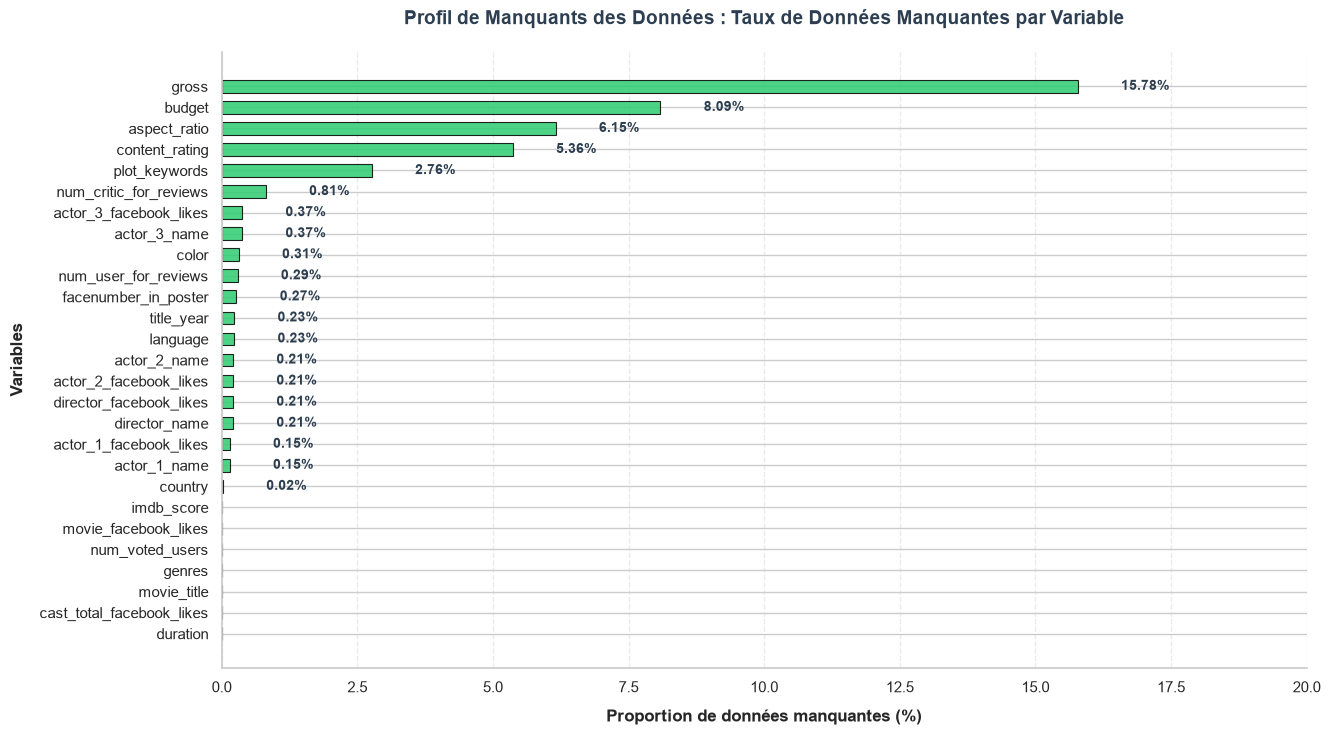

In [195]:
# Statistique descriptive des manquants par colonne

# Calcul du taux de manquant par variable (en pourcentage)
missing_percent = (df.isnull().sum() / len(df)) * 100

# Trie par ordre croissant pour que les variables les plus vides soient en haut du graphique
missing_percent = missing_percent.sort_values(ascending=True)

# Initialisation du canevas graphique
plt.figure(figsize=(14, 8), dpi=100)
style_decor = {'edgecolor': 'black', 'linewidth': 0.8, 'alpha': 0.85}

# Traçage des barres horizontales
bars = plt.barh(missing_percent.index, missing_percent.values, color='#2ECC71', height=0.6, **style_decor)

#  Ajout des étiquettes textuelles au bout de chaque barre 
for bar in bars:
    width = bar.get_width()
    if width > 0:
        plt.text(
            width + 0.8,                
            bar.get_y() + bar.get_height()/2, 
            f'{width:.2f}%',          
            va='center', 
            ha='left', 
            fontsize=10, 
            fontweight='bold', 
            color='#2C3E50'
        )

# Habillage et mise en forme académique
plt.title("Profil de Manquants des Données : Taux de Données Manquantes par Variable", fontsize=14, fontweight='bold', pad=20, color='#2C3E50')
plt.xlabel("Proportion de données manquantes (%)", fontsize=12, labelpad=10, fontweight='semibold')
plt.ylabel("Variables", fontsize=12, labelpad=10, fontweight='semibold')
plt.xlim(0, 20)
plt.grid(axis='x', linestyle='--', alpha=0.4)
for spine in ['top', 'right']:
    plt.gca().spines[spine].set_visible(False)

# Affichage du rendu final
plt.show()

#### Traitement

Pour les valeurs manquantes tels que 'director_name', , 'title_year',  'color', 'country', , 'language', 'duration'; on peut trouver ces informations en ligne. Donc pour ces valeurs manquantes, on va les remplir en faisant des recherches sur Internet. Car ces données ne changent pas au cours du temps.

Pour nous construire une base csv contenant les lignes ayant au moins une valeur manquante pour les colonnes 'title_year', 'duration', 'language', 'country', 'color', 'director_name' pour lesquels nous pouvons completer avec leur informations en ligne atemporrelle

#### Traitement des valeurs manquantes de title_year

In [196]:
df[df["title_year"].isna()]

,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,actor_1_name,movie_title,num_voted_users,cast_total_facebook_likes,actor_3_name,facenumber_in_poster,plot_keywords,num_user_for_reviews,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
950,Color,NaN,14,105.0,<NA>,5,Bruce Alexander,325,NaN,Crime|Drama|Mystery,David Jason,A Touch of Frost,4438,344,John Lyons,1,cult tv|death|detective inspector|four word title|internal affairs,33,English,UK,NaN,NaN,<NA>,7,7.8,1.33,361
1642,Color,NaN,16,511.0,<NA>,51,Ingvar Eggert Sigurðsson,147,NaN,Crime|Drama|Thriller,Ólafur Darri Ólafsson,Trapped,2308,307,Björn Hlynur Haraldsson,0,coastal town|iceland|police|snowstorm|winter storm,19,Icelandic,Iceland,NaN,NaN,<NA>,63,8.2,16.00,0
2386,Color,NaN,108,334.0,<NA>,30,Nora von Waldstätten,897,145118.0,Biography|Crime|Drama|Thriller,Edgar Ramírez,Carlos,10111,1032,Katharina Schüttler,0,opec|pubic hair|revolutionary|terrorism|true crime,36,English,France,Not Rated,NaN,<NA>,30,7.7,2.35,0
2635,Color,NaN,9,286.0,<NA>,527,Tom Hollander,857,NaN,Drama|History|Thriller,Anna Silk,The Company,3828,3809,Alessandro Nivola,3,cia|mole|revolution|spy|ussr,39,English,USA,NaN,NaN,<NA>,555,7.9,1.78,733
2774,Color,Niels Arden Oplev,<NA>,88.0,76,75,David Dencik,690,NaN,Action|Crime|Mystery|Thriller,Michael Nyqvist,Del 1 - Män som hatar kvinnor,335,998,Lena Endre,0,NaN,<NA>,Swedish,Sweden,NaN,NaN,<NA>,94,8.1,NaN,22
3317,Color,NaN,9,142.0,<NA>,427,Jack O'Connell,27000,NaN,Drama|Romance,Tom Hardy,Wuthering Heights,6053,29196,Kevin McNally,2,abuse|love|moor the landscape|revenge|tv mini series,33,English,UK,NaN,NaN,<NA>,698,7.7,NaN,0
3544,Color,NaN,10,240.0,<NA>,334,Blake Ritson,805,NaN,Comedy|Drama|Romance,Romola Garai,Emma,10388,2563,Rupert Evans,1,friendship|love triangle|matchmaker|naivety|opposites attract,50,English,UK,NaN,NaN,<NA>,432,8.2,1.78,0
3763,Color,NaN,2,199.0,<NA>,505,Jonathan Crombie,662,NaN,Drama|Family,Zack Ward,Anne of Green Gables,14251,2667,Megan Follows,0,girl|heroine|kindred spirit|orphan|rural setting,74,English,Canada,TV-G,NaN,<NA>,517,8.4,1.33,0
3977,Color,NaN,<NA>,197.0,<NA>,110,Jessica De Gouw,578,NaN,Drama|War,Rachel Griffiths,Deadline Gallipoli,299,1400,Luke Ford,0,gallipoli|tv mini series|world war one,1,English,Australia,NaN,15000000.0,<NA>,476,7.4,NaN,367
4003,Color,NaN,10,173.0,<NA>,476,Colm Feore,723,NaN,Horror|Sci-Fi|Thriller,Craig T. Nelson,Creature,2011,3149,Megalyn Echikunwoke,3,author cameo|family relationships|island|monster|two part tv movie,33,English,USA,NaN,NaN,<NA>,539,5.0,1.78,518


Tous les "films" qui n'ont pas de valeurs manquantes sont en réalité des séries ou mini-série qu'on a pas pu detecter plus haut. 

In [197]:
# Traitement 
df = df.dropna(subset=["title_year"])

#### Traitement des valeurs manquantes de duration, director_name et director_facebook_likes

In [198]:
df.isnull().sum()['director_name']

np.int64(0)

In [199]:
df.isnull().sum()['director_facebook_likes']

np.int64(0)

Donc, en supprimant les films qui étaient en réalité des séries ou des mini-séries, il n'y a plus de valeurs manquantes de duration, director_name et director_facebook_likes

#### Traitement des valeurs manquantes de Language

In [200]:
df[df["language"].isna()]

,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,actor_1_name,movie_title,num_voted_users,cast_total_facebook_likes,actor_3_name,facenumber_in_poster,plot_keywords,num_user_for_reviews,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
2799,Color,Jean-Jacques Annaud,62,100.0,218,91,Everett McGill,581,NaN,Adventure|Drama|History,Rae Dawn Chong,Quest for Fire,16281,931,Gary Schwartz,0,fire|prehistoric times|primitive|tribe|trio,96,NaN,Canada,R,12500000.0,1981,201,7.4,2.35,0
2988,Color,Christopher Cain,43,111.0,58,258,Taylor Handley,482,1066555.0,Drama|History|Romance|Western,Jon Gries,September Dawn,2618,1526,Trent Ford,0,massacre|mormon|settler|utah|wagon train,111,NaN,USA,R,11000000.0,2007,362,5.8,1.85,411
3434,NaN,Richard Rich,2,45.0,24,29,Kate Higgins,122,NaN,Action|Adventure|Animation|Comedy|Drama|Family|Fantasy|Thriller,Debi Derryberry,Alpha and Omega 4: The Legend of the Saw Toothed Cave,192,236,Cindy Robinson,0,blindness|cave|spirit|wolf|wolf cub,6,NaN,USA,NaN,7000000.0,2014,35,6.0,NaN,41
3761,Color,Mel Brooks,39,87.0,0,753,Dom DeLuise,898,NaN,Comedy|Romance,Sid Caesar,Silent Movie,12666,2951,Bernadette Peters,0,black comedy|friend|modern silent movie|silent movie|two word title,61,NaN,USA,PG,4400000.0,1976,842,6.7,1.85,629
3821,Color,Ron Fricke,115,102.0,330,0,Balinese Tari Legong Dancers,48,2601847.0,Documentary|Music,Collin Alfredo St. Dic,Samsara,22457,48,Puti Sri Candra Dewi,0,hall of mirrors|mont saint michel france|palace of versailles|turkey the country|yellowstone national park,69,NaN,USA,PG-13,4000000.0,2011,0,8.5,2.35,26000
4000,Color,Michael Landon Jr.,5,87.0,84,331,Kevin Gage,702,252726.0,Drama|Family|Western,William Morgan Sheppard,Love's Abiding Joy,1289,2715,Brianna Brown,0,19th century|faith|mayor|ranch|sheriff,18,NaN,USA,PG,3000000.0,2006,366,7.2,NaN,76
4294,NaN,John Stockwell,2,90.0,134,354,T.J. Storm,260000,NaN,Action,Matthew Ziff,Kickboxer: Vengeance,246,261818,Sam Medina,5,NaN,1,NaN,USA,NaN,17000000.0,2016,454,9.1,NaN,0
4513,NaN,Jonathan Meyers,1,111.0,0,426,Luke Perry,657,NaN,Drama,Justin Baldoni,A Fine Step,207,2677,Leonor Varela,0,NaN,1,NaN,USA,PG,1000000.0,2014,608,5.3,NaN,212
4691,Black and White,D.W. Griffith,69,123.0,204,9,Mae Marsh,436,NaN,Drama|History|War,Lillian Gish,Intolerance: Love's Struggle Throughout the Ages,10718,481,Walter Long,1,huguenot|intolerance|medicis|protestant|wedding,88,NaN,USA,Not Rated,385907.0,1916,22,8.0,1.33,691
4765,Black and White,King Vidor,48,151.0,54,6,Renée Adorée,81,NaN,Drama|Romance|War,John Gilbert,The Big Parade,4849,108,Claire Adams,0,chewing gum|climbing a tree|france|translation problems|world war one,45,NaN,USA,Not Rated,245000.0,1925,12,8.3,1.33,226


In [201]:
df[df["language"].isna()].index

Index([2799, 2988, 3434, 3761, 3821, 4000, 4294, 4513, 4691, 4765, 4834],
      dtype='int64')

In [202]:
# Renseignement des langues manquantes à l'issue de la recherche 
df.loc[2799, 'language'] = 'Invented language'
df.loc[2988, 'language'] = 'English'
df.loc[3434, 'language'] = 'English'
df.loc[3761, 'language'] = 'English'
df.loc[3821, 'language'] = 'Aucun'
df.loc[4000, 'language'] = 'English'
df.loc[4294, 'language'] = 'English'
df.loc[4513, 'language'] = 'English'
df.loc[4691, 'language'] = 'English'
df.loc[4765, 'language'] = 'English'
df.loc[4834, 'language'] = 'Silent (English intertitles)'

In [203]:
# Vérification de l'absence de valeurs manquantes de language 
df.isnull().sum()['language']

np.int64(0)

#### Traitement des valeurs manquantes de country

In [204]:
df[df["country"].isna()]

,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,actor_1_name,movie_title,num_voted_users,cast_total_facebook_likes,actor_3_name,facenumber_in_poster,plot_keywords,num_user_for_reviews,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
3911,Color,Daniel Petrie Jr.,9,88.0,19,322,Jeff Fahey,795,NaN,Drama|Thriller,Chris Brochu,Dawn Patrol,455,2497,Rita Wilson,0,desert|held at gunpoint|marine|revenge|sex on table,13,English,NaN,NaN,3500000.0,2014,535,4.8,2.35,570


D'après les recherche sur le site de IMDb, ce film provient des Etats-Unis

In [205]:
# Renseignement des langues manquantes à l'issue de la recherche 
df.loc[3911, 'country'] = 'USA'

# Vérification de l'absence de valeurs manquantes de country 
df.isnull().sum()['country']

np.int64(0)

#### Traitement des valeurs manquantes de color

In [206]:
df[df["color"].isna()]

,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,actor_1_name,movie_title,num_voted_users,cast_total_facebook_likes,actor_3_name,facenumber_in_poster,plot_keywords,num_user_for_reviews,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
1873,NaN,Lasse Hallström,162,108.0,529,690,Henry Thomas,17000,80014842.0,Drama|Romance|War,Channing Tatum,Dear John,104356,19945,Scott Porter,<NA>,army|coin collector|love|surfboard|u.s. army,186,English,USA,PG-13,25000000.0,2010,861,6.3,2.35,14000
1940,NaN,Mario Van Peebles,7,100.0,535,399,Mario Van Peebles,668,NaN,Action|Thriller,Martin Kove,Red Sky,1084,2204,Jacob Vargas,0,exploding airplane|fighter pilot|hands tied|held at gunpoint|military,11,English,USA,PG-13,25000000.0,2014,535,4.1,NaN,437
2661,NaN,Tung-Shing Yee,53,119.0,3,19,Daniel Wu,556,NaN,Action|Crime|Drama|Thriller,Bingbing Fan,Shinjuku Incident,9177,996,Yasuaki Kurata,4,chinese|gang|gratitude|immigrant|japan,53,Mandarin,Hong Kong,R,15000000.0,2009,353,7.1,2.35,821
3172,NaN,David Hackl,48,94.0,43,129,Michaela McManus,826,NaN,Action|Horror|Thriller,Scott Glenn,Into the Grizzly Maze,4486,1586,Luisa D'Oliveira,4,bear|breasts|female nudity|grizzly|wilderness,38,English,USA,R,10000000.0,2015,476,5.3,1.85,0
3434,NaN,Richard Rich,2,45.0,24,29,Kate Higgins,122,NaN,Action|Adventure|Animation|Comedy|Drama|Family|Fantasy|Thriller,Debi Derryberry,Alpha and Omega 4: The Legend of the Saw Toothed Cave,192,236,Cindy Robinson,0,blindness|cave|spirit|wolf|wolf cub,6,English,USA,NaN,7000000.0,2014,35,6.0,NaN,41
3532,NaN,Wayne Wang,56,104.0,61,451,Russell Wong,974,1346503.0,Drama|History,Bingbing Li,Snow Flower and the Secret Fan,3024,2430,Ji-hyun Jun,0,car hitting pedestrian|china|fan|nineteenth century|reversal of fortune,22,English,China,PG-13,6000000.0,2011,595,6.1,2.35,0
3550,NaN,Charles Matthau,13,90.0,139,1000,Michael Jai White,2000,NaN,Comedy|Crime|Thriller,Billy Burke,Freaky Deaky,6741,6569,Bill Duke,0,black panties|bomb squad|car bomb|dynamite|girl in panties,11,English,USA,R,6000000.0,2012,2000,6.5,NaN,0
4028,NaN,Darin Scott,7,95.0,39,375,Shantel VanSanten,1000,NaN,Drama|Horror|Mystery|Thriller,Julian Morris,Something Wicked,976,3024,John Robinson,2,eugene oregon|independent film|obsession,15,English,USA,R,3000000.0,2014,747,4.8,NaN,395
4104,NaN,Zackary Adler,10,110.0,0,109,Kevin Leslie,490,NaN,Crime|Drama,Simon Merrells,The Rise of the Krays,1510,881,Kris Sommerville,0,NaN,26,English,UK,R,2500000.0,2015,159,5.0,NaN,0
4217,NaN,Jonas Åkerlund,33,96.0,68,722,Saffron Burrows,2000,NaN,Comedy|Crime|Drama,Noel Gugliemi,Small Apartments,5732,3683,Matt Lucas,6,fire investigator|landlord|suicide|talking to one's self in a mirror|turpentine,26,English,USA,R,2000000.0,2012,811,6.1,1.85,0


In [207]:
# Renseignement des langues manquantes à l'issue de la recherche 
df.loc[1873, 'color'] = 'Color'
df.loc[1940, 'color'] = 'Color'
df.loc[2661, 'color'] = 'Color'
df.loc[3172, 'color'] = 'Color'
df.loc[3434, 'color'] = 'Color'
df.loc[3532, 'color'] = 'Color'
df.loc[3550, 'color'] = 'Color'
df.loc[4028, 'color'] = 'Color'
df.loc[4104, 'color'] = 'Color'
df.loc[4217, 'color'] = 'Color'
df.loc[4294, 'color'] = 'Color'
df.loc[4326, 'color'] = 'Color'
df.loc[4513, 'color'] = 'Color'
df.loc[4727, 'color'] = 'Color'
df.loc[4896, 'color'] = 'Color'

In [208]:
# Vérification de l'absence de valeurs manquantes de color 
df.isnull().sum()['color']

np.int64(0)

#### Traitement des valeurs manquantes de actor_1_name, actor_2_name, actor_3_name et actor_1_facebook_likes, actor_2_facebook_likes, actor_3_facebook_likes

In [209]:
df.isnull().sum()

color                          0
director_name                  0
num_critic_for_reviews        37
duration                       0
director_facebook_likes        0
actor_3_facebook_likes        17
actor_2_name                  10
actor_1_facebook_likes         7
gross                        749
genres                         0
actor_1_name                   7
movie_title                    0
num_voted_users                0
cast_total_facebook_likes      0
actor_3_name                  17
facenumber_in_poster          13
plot_keywords                132
num_user_for_reviews          13
language                       0
country                        0
content_rating               249
budget                       379
title_year                     0
actor_2_facebook_likes        10
imdb_score                     0
aspect_ratio                 293
movie_facebook_likes           0
dtype: int64

En regardant la configuration des valeurs manquantes, on constate que lorqu'on ne connait pas le nom d'un acteur/actrice, on peut connait pas le nombre de ces likes sur Facebook.

In [210]:
# Vérificaton que les colonnes actor_1_facebook_likes et actor_1_name ont les valeurs manquantes au même endroit
df['actor_1_name'].isna().equals(df['actor_1_facebook_likes'].isna())

True

In [211]:
# Vérificaton que les colonnes actor_2_facebook_likes et actor_2_name ont les valeurs manquantes au même endroit
df['actor_2_name'].isna().equals(df['actor_2_facebook_likes'].isna())

True

In [212]:
# Vérificaton que les colonnes actor_3_facebook_likes et actor_3_name ont les valeurs manquantes au même endroit
df['actor_3_name'].isna().equals(df['actor_3_facebook_likes'].isna())

True

Cela confirme bien ce qu'on disait

In [213]:
# Nombre de lignes ayant au moins une valeur manquante actor_1_name ou actor_2_name ou actor_3_name
len(  df[df["actor_1_name"].isna() | df["actor_2_name"].isna() | df["actor_3_name"].isna() ]  )

17

Donc, il y a 17 lignes en tout ayant des valeurs manquantes pour ces 6 variables. 

* La première intuition était de faire une imputation par le mode des acteurs (pour 1 , 2 et 3) des films s'ayant déroulé la même année que le film qu'on veut imputer la valeur. mais, cela ne repose vraiment sur aucun fondement. De plus, on aurait par la suite pour imputer les colonnes actor_facebook_likes prendre la moyenne des likes de cette acteur pour la même année. Mais, rien ne rassure que la somme des actor_facebook_likes sera inférieure au cast_total_facebook_likes. Cette méthode a été supprimé. 

* Une autre approche serait de créer une catégorie Unknown. Celle-ci a plus de sens et signifierait qu'une absence d'information qui impacte bien évidemment les notes des utilisateurs et  la popularité du film. Mais, avec le mécanisme réliant le nom de l'acteur et les likes, les colonnes likes ne pourront pas être remplies

Ce sont pour ces raisons que les lignes manquantes ont été supprimées

In [214]:
df = df.dropna(subset=["actor_1_name", "actor_2_name", "actor_3_name"])
df.shape

(4783, 27)

#### Traitement des valeurs manquantes de plot_keywords

In [215]:
df.isnull().sum()['plot_keywords']

np.int64(129)

On a 129 valeurs manquantes de plot_keywords. 
* Si on remplace ces valeurs manquantes par la mode/une quelconque valeur, on serait en train de gongler le poids d'une modalité, ce qui va contredit les analyses car les films n'auront pas forcement le même sens. 
* Si on supprime, on perd une information cruciale. L'information perdue est l'absence d'information. Cette absence peut jouer un rôle sur la perception du film par les utilisateurs

C'est pourquoi nous avons décider d'imputater par la modalité 'Unknown'

In [216]:
df['plot_keywords'] = df['plot_keywords'].fillna('Unknown')

#### Traitement des valeurs manquantes de facenumber_in_poster, num_user_for_reviews et num_critic_for_reviews

Ces variables sont traités ensemble car elles préseentent la même évolution( asymétrie à droite) et sont dépendantes du temps

In [217]:
cols_vue = ['facenumber_in_poster', 'num_user_for_reviews', 'num_critic_for_reviews']
print(df[cols_vue].isnull().sum())

facenumber_in_poster      13
num_user_for_reviews      12
num_critic_for_reviews    36
dtype: int64


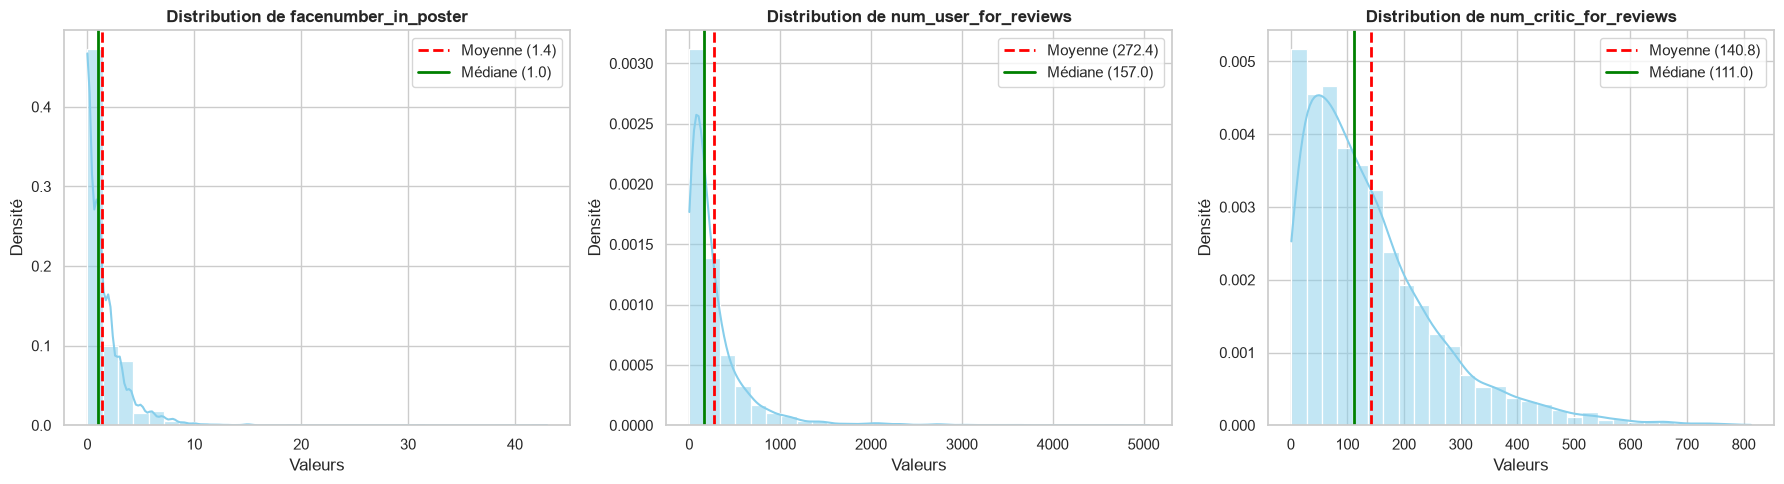

In [218]:
# Vérification de l'asymétrie supposée de ces variables

plt.figure(figsize=(18, 5))

for i, col in enumerate(cols_vue, 1):
    plt.subplot(1, 3, i)
    data_clean = df[col].dropna()
    
    # Tracé de l'histogramme avec courbe de densité
    sns.histplot(data_clean, kde=True, color="skyblue", bins=30, stat="density")
    
    # Ajout des lignes repères pour la Moyenne et la Médiane
    plt.axvline(data_clean.mean(), color='red', linestyle='--', linewidth=2, label=f"Moyenne ({data_clean.mean():.1f})")
    plt.axvline(data_clean.median(), color='green', linestyle='-', linewidth=2, label=f"Médiane ({data_clean.median():.1f})")
    
    plt.title(f"Distribution de {col}", fontsize=12, fontweight='bold')
    plt.xlabel("Valeurs")
    plt.ylabel("Densité")
    plt.legend()

plt.tight_layout()
plt.show()

On constate bien une forte asymétrie à droite. Pour cette raison, une imputation par la moyenne n'est pas possible. On va imputer par la médiane

Par ailleurs, la médiane ne peut pas être seulement simple. Car on serait en train de perdre une information importante : le volume de critiques sur internet ou le style des affiches dépendent mécaniquement de l'époque de production, l'accès au web et les pratiques marketing s'étant intensifiés au fil du temps.

C'est pour cela qu'on va imputer par la médiane de la génération du film, pour garantir le comportement tendanciel de ces variables

In [219]:
# Traitement

# Création de la variable decennie
df['decade'] = (df['title_year'] // 10) * 10

# Application de l'imputation par medianne de la decennie
for col in cols_vue:
    df[col] = df[col].astype('float64')

    # Calcul de la médiane de la colonne pour chaque décennie
    médianes_par_decennie = df.groupby('decade')[col].transform('median')
    
    # Remplacement des valeurs manquantes par la médiane de la décennie correspondante
    df[col] = df[col].fillna(médianes_par_decennie)
    
    # Si une décennie entière n'avait aucune donnée on applique la médiane globale de la colonne, 
    if df[col].isnull().any():
        mediane_globale = df[col].median()
        df[col] = df[col].fillna(mediane_globale)
    
    df[col] = df[col].round().astype('int64')

# Supprésion de la variable decade
df = df.drop(columns=['decade'])

# Vérification de la bonne marche de l'imputation
print(df[cols_vue].isnull().sum())


facenumber_in_poster      0
num_user_for_reviews      0
num_critic_for_reviews    0
dtype: int64


#### Traitement des valeurs manquantes de content_rating 

La classification des films utilisés pour avoir content_rating est une classification américaine. La présence de valeurs manquantes est plus observée chez les productions hors américaines, comme le montre le graphique suivant : 

C:\Users\user\AppData\Local\Temp\ipykernel_7572\2815547083.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10_tri_pct, x='pourcentage_manquants', y='country', palette='Blues_r')


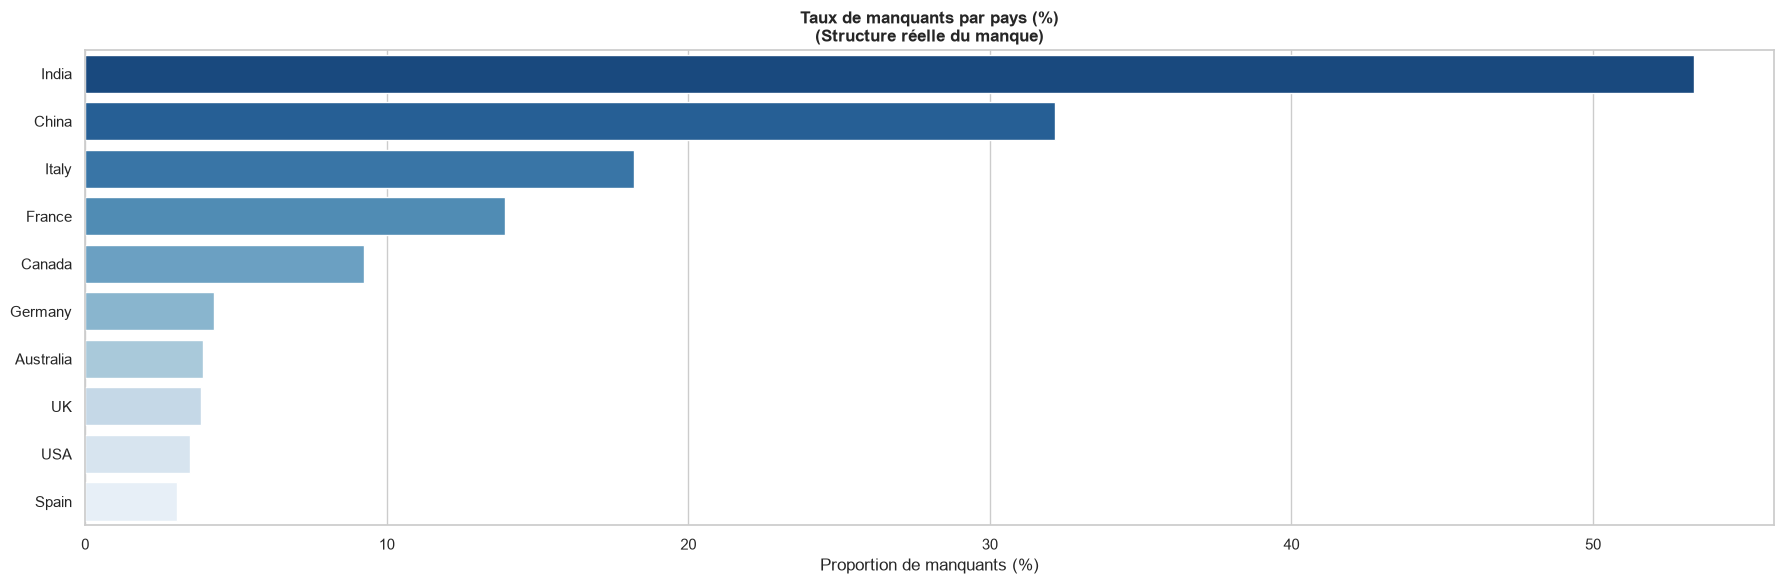

In [220]:
# Graphique du taux de valeurs manquantes de content_rating par pays de production

# Agrégation statistique par pays
stats_pays = df.groupby('country')['content_rating'].agg(
    total_films='size',
    manquants_bruts=lambda x: x.isnull().sum(),
    pourcentage_manquants=lambda x: (x.isnull().sum() / len(x)) * 100
).reset_index()

# Sélection des 10 premiers pays producteurs pour éviter le bruit des petits effectifs
top_10_producteurs = stats_pays.nlargest(10, 'total_films')

# Tri par pourcentage décroissant pour une lecture graphique optimale
top_10_tri_pct = top_10_producteurs.sort_values('pourcentage_manquants', ascending=False)

# Construction des graphiques
plt.figure(figsize=(18, 6))
sns.barplot(data=top_10_tri_pct, x='pourcentage_manquants', y='country', palette='Blues_r')
plt.title("Taux de manquants par pays (%)\n(Structure réelle du manque)", fontsize=12, fontweight='bold')
plt.xlabel("Proportion de manquants (%)")
plt.ylabel("")

plt.tight_layout()
plt.show()

Ainsi, la valeur manquante signifié que le film n'a pas été classifié. On va donc imputer par la modalité unrated(environ 1.2% de la base) qui existe déja dans la base

In [221]:
# Traitement
df['content_rating'] = df['content_rating'].fillna('Unrated')
print(df['content_rating'].isnull().sum())

0


#### Traitement des valeurs manquantes de aspect_ratio

* aspect_ratio est une variable quantitative discrete. On ne peut donc pas imputer par la moyenne car il se peut que la valeur trouvée n'existe pas.  De même la médiane n'est pas possible si elle est calculée. 
* De plus, le format de projection de l'image d'un film dépend de la période de production ( les formats d'aujourd'hui ne sont pas les mêmes formats des années 1900). Par alleurs, le format varie aussi en fonction des pays.
* C'est pour cela qu'on va fait imputer par le mode de la decennie et du pays du film dont la valeur est manquante.

In [222]:
# Traitement  

# Création de la variable decennie
df['decade'] = (df['title_year'] // 10) * 10

# Calcul du mode par groupe 
def calculer_mode(serie):
    mode_res = serie.mode()
    return mode_res.iloc[0] if not mode_res.empty else np.nan

# Imputation
mode_spatio_temporel = df.groupby(['decade', 'country'])['aspect_ratio'].transform(calculer_mode)
df['aspect_ratio'] = df['aspect_ratio'].fillna(mode_spatio_temporel)

#  Si le flmn est le seul du pays dans sa décennie
if df['aspect_ratio'].isnull().any():
    mode_par_pays = df.groupby('country')['aspect_ratio'].transform(calculer_mode)
    df['aspect_ratio'] = df['aspect_ratio'].fillna(mode_par_pays)

# Si un manquant persiste, application du mode global de la base
if df['aspect_ratio'].isnull().any():
    mode_global = df['aspect_ratio'].mode().iloc[0]
    df['aspect_ratio'] = df['aspect_ratio'].fillna(mode_global)

# Nettoyage de la colonne temporaire
df = df.drop(columns=['decade'])

print(df['aspect_ratio'].isnull().sum())

0


#### Traitement des valeurs manquantes de gross et budget

* Une premiere intention était de chercher les valeurs manquantes pour le BUDGET sur le site de IMDb car on ne peut plus trouver les valeurs manquantes de Gross de 2016 car le revenu évolue avec le temps.

* Même si certaines valeurs sont présentes pour le budget, elles sont à un nombre faible sur les 376 valeurs manquantes. Ce qu'il fait qu'on doit imputer

* Mais, les périodes étant différentes, on peut par comparer les montants entre elles, d'ou la déflation des montants financières.

#####  DEFLATION DES COLONNES FINANCIERES (BASE USD 2026)

Comme la base contient des valeurs monétaires en USD de différentes périodes, on peut pas simplement comparer celles-ci comme ca. Il faut les ramener à une même base. 

Pour se faire, nous privilégions de l'année la plus recente comme base monétaire. 

In [223]:
# Chargement de la base des Indices de prices à la consommation (CPI en anglais)
df_cpi = pd.read_csv('CPIAUCNS.csv', parse_dates  = ['observation_date'])
# La base CPIAUCNS provient du site de la FED américain

# Les valeurs de CPI sont mensuelles depuis 1913 jusqu'au aujourd'hui
display(df_cpi.head(10))

,observation_date,CPIAUCNS
0,1913-01-01,9.8
1,1913-02-01,9.8
2,1913-03-01,9.8
3,1913-04-01,9.8
4,1913-05-01,9.7
5,1913-06-01,9.8
6,1913-07-01,9.9
7,1913-08-01,9.9
8,1913-09-01,10.0
9,1913-10-01,10.0


In [224]:
# Calcul du CPI annuel moyen
df_cpi['Année'] = df_cpi['observation_date'].dt.year
cpi_anuuel = df_cpi.groupby('Année')['CPIAUCNS'].mean()

cpi_anuuel

Année
1913      9.883333
1914     10.016667
1915     10.108333
1916     10.883333
1917     12.825000
1918     15.041667
1919     17.333333
1920     20.041667
1921     17.850000
1922     16.750000
1923     17.050000
1924     17.125000
1925     17.541667
1926     17.700000
1927     17.358333
1928     17.158333
1929     17.158333
1930     16.700000
1931     15.208333
1932     13.641667
1933     12.933333
1934     13.383333
1935     13.725000
1936     13.866667
1937     14.383333
1938     14.091667
1939     13.908333
1940     14.008333
1941     14.725000
1942     16.333333
1943     17.308333
1944     17.591667
1945     17.991667
1946     19.516667
1947     22.325000
1948     24.041667
1949     23.808333
1950     24.066667
1951     25.958333
1952     26.550000
1953     26.766667
1954     26.850000
1955     26.775000
1956     27.183333
1957     28.091667
1958     28.858333
1959     29.150000
1960     29.575000
1961     29.891667
1962     30.250000
1963     30.625000
1964     31.016667
1965  

In [225]:
# Deflation des colonnes financieres de la base

# recupération de la valeur de référence (2016)
cpi_2016 = cpi_anuuel.loc[2016]

# Mapping 
df['cpi_movie_year'] = df['title_year'].map(cpi_anuuel)

# Application de la formule du déflateur économique 
for col in ['budget', 'gross']: 
    if col in df.columns : 
        df[f'{col}_real_2016'] = df[col]* (cpi_2016 / df['cpi_movie_year'])

# Suppression des variables qui ne serviront plus 
df.drop(columns = ['cpi_movie_year', 'budget', 'gross'], inplace = True)

display(df.head(10))


C:\Users\user\AppData\Local\Temp\ipykernel_7572\3175131589.py:15: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns = ['cpi_movie_year', 'budget', 'gross'], inplace = True)


,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,genres,actor_1_name,movie_title,num_voted_users,cast_total_facebook_likes,actor_3_name,facenumber_in_poster,plot_keywords,num_user_for_reviews,language,country,content_rating,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes,budget_real_2016,gross_real_2016
0,Color,James Cameron,723,178.0,0,855,Joel David Moore,1000,Action|Adventure|Fantasy|Sci-Fi,CCH Pounder,Avatar,886204,4834,Wes Studi,0,avatar|future|marine|native|paraplegic,3054,English,USA,PG-13,2009,936,7.9,1.78,33000,265137009.000778,850794285.237062
1,Color,Gore Verbinski,302,169.0,563,1000,Orlando Bloom,40000,Action|Adventure|Fantasy,Johnny Depp,Pirates of the Caribbean: At World's End,471220,48350,Jack Davenport,0,goddess|marriage ceremony|marriage proposal|pirate|singapore,1238,English,USA,PG-13,2007,5000,7.1,2.35,0,347262037.153517,358147720.424255
2,Color,Sam Mendes,602,148.0,0,161,Rory Kinnear,11000,Action|Adventure|Thriller,Christoph Waltz,Spectre,275868,11700,Stephanie Sigman,1,bomb|espionage|sequel|spy|terrorist,994,English,UK,PG-13,2015,393,6.8,2.35,85000,248090878.853978,202598277.190754
3,Color,Christopher Nolan,813,164.0,22000,23000,Christian Bale,27000,Action|Thriller,Tom Hardy,The Dark Knight Rises,1144337,106759,Joseph Gordon-Levitt,0,deception|imprisonment|lawlessness|police officer|terrorist plot,2701,English,USA,PG-13,2012,23000,8.5,2.35,164000,261338769.50137,468455642.224555
5,Color,Andrew Stanton,462,132.0,475,530,Samantha Morton,640,Action|Adventure|Sci-Fi,Daryl Sabara,John Carter,212204,1873,Polly Walker,1,alien|american civil war|male nipple|mars|princess,738,English,USA,PG-13,2012,632,6.6,2.35,24000,275660134.070045,76372261.085022
6,Color,Nathan Greno,324,100.0,15,284,Donna Murphy,799,Adventure|Animation|Comedy|Family|Fantasy|Musical|Romance,Brad Garrett,Tangled,294810,2036,M.C. Gainey,1,17th century|based on fairy tale|disney|flower|tower,387,English,USA,PG,2010,553,7.8,1.85,29000,286174223.229101,221022547.006203
7,Color,Joss Whedon,635,141.0,0,19000,Robert Downey Jr.,26000,Action|Adventure|Sci-Fi,Chris Hemsworth,Avengers: Age of Ultron,462669,92000,Scarlett Johansson,4,artificial intelligence|based on comic book|captain america|marvel cinematic universe|superhero,1117,English,USA,PG-13,2015,21000,7.5,2.35,118000,253153958.014263,464782159.928583
8,Color,David Yates,375,153.0,282,10000,Daniel Radcliffe,25000,Adventure|Family|Fantasy|Mystery,Alan Rickman,Harry Potter and the Half-Blood Prince,321795,58753,Rupert Grint,3,blood|book|love|potion|professor,973,English,UK,PG,2009,11000,7.5,2.35,10000,279680389.241327,337805782.802143
9,Color,Zack Snyder,673,183.0,0,2000,Lauren Cohan,15000,Action|Adventure|Sci-Fi,Henry Cavill,Batman v Superman: Dawn of Justice,371639,24450,Alan D. Purwin,0,based on comic book|batman|sequel to a reboot|superhero|superman,3018,English,USA,PG-13,2016,4000,6.9,2.35,197000,250000000.0,330249062.0
10,Color,Bryan Singer,434,169.0,0,903,Marlon Brando,18000,Action|Adventure|Sci-Fi,Kevin Spacey,Superman Returns,240396,29991,Frank Langella,0,crystal|epic|lex luthor|lois lane|return to earth,2367,English,USA,PG-13,2006,10000,6.1,2.35,0,248827239.055847,238194824.93865


##### Traitement  : Imputation par la méthode des KNN: cas des variables budget_real_2016 et gross_real_2016

Principe: pour chaque film présentant une valeur manquante, on identifie les k films les plus similaires suivant un ensemble de variables quantitatives partageant une corrélation et on impute ces valeurs manquantes par la moyenne pondérée de leurs valeurs.                                                    

In [226]:
FIN_COLS = ['budget_real_2016', 'gross_real_2016']

df_avant = df[FIN_COLS].copy()

for col in FIN_COLS:
    df[f'log_{col}'] = np.log1p(df[col])

print('NaN avant imputation :')
for col in FIN_COLS:
    print(f'  {col:25s} : {df[col].isna().sum()} NaN')

NaN avant imputation :
  budget_real_2016          : 376 NaN
  gross_real_2016           : 745 NaN


In [227]:
print(df[FIN_COLS].isnull().sum())

budget_real_2016    376
gross_real_2016     745
dtype: int64


In [228]:

# Selection des prédicteurs 
criteres_predicteurs = [
    'duration', 'imdb_score', 'num_user_for_reviews', 'num_critic_for_reviews','aspect_ratio',
    'cast_total_facebook_likes', 'director_facebook_likes', 'movie_facebook_likes', 'num_voted_users'
]

# L'espace global pour le KNN contient les critères + nos deux cibles réelles
espace_knn = criteres_predicteurs + ['log_budget_real_2016', 'log_gross_real_2016']

df_knn = df[espace_knn].copy()

# STANDARDISATION
scaler = StandardScaler()
mask_complet = df_knn.notna().all(axis=1)
scaler.fit(df_knn[mask_complet])

df_knn_scaled = pd.DataFrame(
    scaler.transform(df_knn),
    columns=espace_knn,
    index=df_knn.index
)

#  IMPUTATION PAR LES K-PLUS PROCHES VOISINS (k=5)
imputer = KNNImputer(n_neighbors=5, weights='distance')
df_knn_imputed = pd.DataFrame(
    imputer.fit_transform(df_knn_scaled),
    columns=espace_knn,
    index=df_knn.index
)

# Transformation inverse pour restaurer l'échelle métrique d'origine
df_imputed = pd.DataFrame(
    scaler.inverse_transform(df_knn_imputed), 
    columns=espace_knn,
    index=df_knn.index
)

# Réinjection exclusive des variables réelles imputées dans le DataFrame principal
for col in FIN_COLS:
    log_col = f'log_{col}'
    mask_nan = df[col].isna()
    df.loc[mask_nan, col] = np.expm1(df_imputed.loc[mask_nan, log_col])
    df[col] = df[col].clip(lower=0)



df = df.drop(columns=['log_budget_real_2016',  'log_gross_real_2016'])


# Pour se rassurer que l'imputation a marché 
print(df[FIN_COLS].isnull().sum())

budget_real_2016    0
gross_real_2016     0
dtype: int64


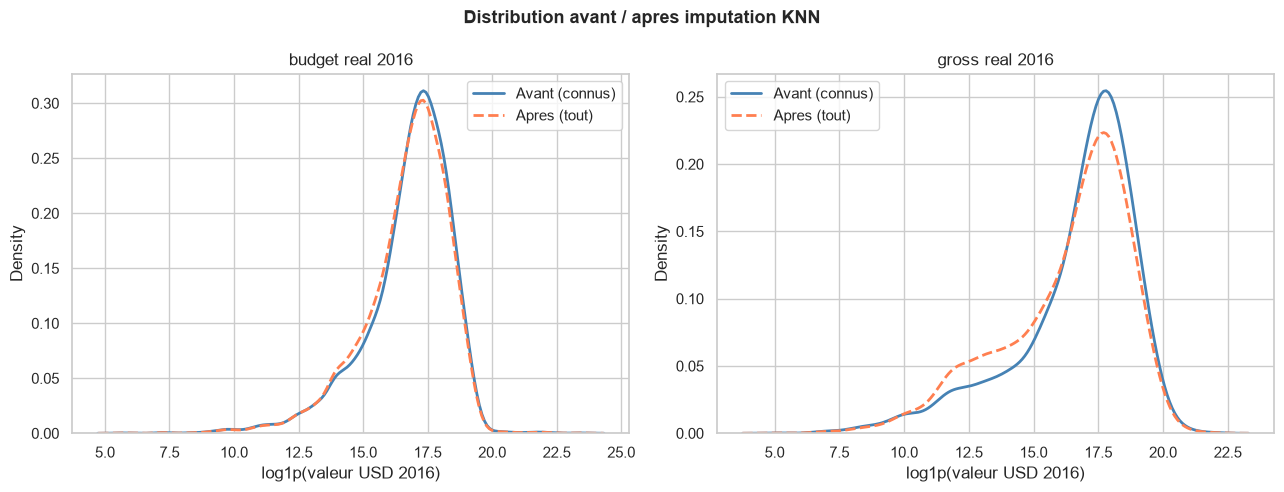


 Statistiques descriptives apres imputation :
         budget_real_2016    gross_real_2016
count              4783.0             4783.0
mean      47922747.546437    59584985.057177
std       244221863.15589   122191833.973938
min            284.420724         164.238365
25%        8106658.710309     2986321.236649
50%       23923463.814765    22921014.998887
75%        55303550.24536    69502781.626446
max    14543297314.290436  3428066416.979676


In [229]:
# Vérification que les distributions avant et apres l'imputation sont "identiques"

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Distribution avant / apres imputation KNN', fontsize=13, fontweight='bold')

for ax, col in zip(axes, FIN_COLS):
    vals_avant = df_avant[col].dropna()
    vals_apres = df[col]

    sns.kdeplot(np.log1p(vals_avant), ax=ax, label='Avant (connus)',
                color='steelblue', linewidth=2)
    sns.kdeplot(np.log1p(vals_apres), ax=ax, label='Apres (tout)',
                color='coral', linewidth=2, linestyle='--')

    ax.set_title(col.replace('_', ' '))
    ax.set_xlabel('log1p(valeur USD 2016)')
    ax.legend()

plt.tight_layout()
plt.show()

print('\n Statistiques descriptives apres imputation :')
print(df[FIN_COLS].describe()) #.applymap(lambda x: f'{x:,.0f}'))

In [230]:
# Vérification de l'absence de valeurs abérantes
df.isnull().sum()

color                        0
director_name                0
num_critic_for_reviews       0
duration                     0
director_facebook_likes      0
actor_3_facebook_likes       0
actor_2_name                 0
actor_1_facebook_likes       0
genres                       0
actor_1_name                 0
movie_title                  0
num_voted_users              0
cast_total_facebook_likes    0
actor_3_name                 0
facenumber_in_poster         0
plot_keywords                0
num_user_for_reviews         0
language                     0
country                      0
content_rating               0
title_year                   0
actor_2_facebook_likes       0
imdb_score                   0
aspect_ratio                 0
movie_facebook_likes         0
budget_real_2016             0
gross_real_2016              0
dtype: int64

## 2.6 - Identification et Traitement des valeurs extrêmes

In [231]:
# Fonction pour détecter les outliers dans une série
def detect_outliers_iqr(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return ((series < lower_bound) | (series > upper_bound)).any()

# Sélectionner les colonnes numériques
numeric_cols = df.select_dtypes(include='number').columns

# Détecter les colonnes avec des valeurs extrêmes
columns_with_outliers = [col for col in numeric_cols if detect_outliers_iqr(df[col])]

print("Colonnes contenant des valeurs extrêmes (outliers) :")
for col in columns_with_outliers:
    print(f" - {col}")


Colonnes contenant des valeurs extrêmes (outliers) :
 - num_critic_for_reviews
 - duration
 - director_facebook_likes
 - actor_3_facebook_likes
 - actor_1_facebook_likes
 - num_voted_users
 - cast_total_facebook_likes
 - facenumber_in_poster
 - num_user_for_reviews
 - title_year
 - actor_2_facebook_likes
 - imdb_score
 - aspect_ratio
 - movie_facebook_likes
 - budget_real_2016
 - gross_real_2016


Les valeurs manquantes de title_year ne seront pas traités

In [232]:
# Statistiques descriptives ces valeurs extrêmes
columns_with_outliers.remove('title_year')

for col in columns_with_outliers:
    if col in df.columns:
        s = skew(df[col].dropna())
        k = kurtosis(df[col].dropna())
        print(f"Variable '{col}' :  Skewness (Asymétrie) : {s:.2f} | Kurtosis (Aplatissement) : {k:.2f}")



Variable 'num_critic_for_reviews' :  Skewness (Asymétrie) : 1.54 | Kurtosis (Aplatissement) : 3.06
Variable 'duration' :  Skewness (Asymétrie) : 2.19 | Kurtosis (Aplatissement) : 11.77
Variable 'director_facebook_likes' :  Skewness (Asymétrie) : 5.19 | Kurtosis (Aplatissement) : 26.74
Variable 'actor_3_facebook_likes' :  Skewness (Asymétrie) : 7.36 | Kurtosis (Aplatissement) : 62.13
Variable 'actor_1_facebook_likes' :  Skewness (Asymétrie) : 19.13 | Kurtosis (Aplatissement) : 672.85
Variable 'num_voted_users' :  Skewness (Asymétrie) : 4.03 | Kurtosis (Aplatissement) : 24.35
Variable 'cast_total_facebook_likes' :  Skewness (Asymétrie) : 13.02 | Kurtosis (Aplatissement) : 363.95
Variable 'facenumber_in_poster' :  Skewness (Asymétrie) : 4.49 | Kurtosis (Aplatissement) : 54.41
Variable 'num_user_for_reviews' :  Skewness (Asymétrie) : 4.20 | Kurtosis (Aplatissement) : 27.58
Variable 'actor_2_facebook_likes' :  Skewness (Asymétrie) : 10.14 | Kurtosis (Aplatissement) : 265.64
Variable 'imdb_s

In [233]:
# Configuration pour les graphiques
plt.style.use('seaborn-v0_8-whitegrid')
rcParams = {'axes.labelsize': 12, 'axes.titlesize': 14, 'xtick.labelsize': 10, 'ytick.labelsize': 10}
plt.rcParams.update(rcParams)

C:\Users\user\AppData\Local\Temp\ipykernel_7572\1574932830.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='facenumber_in_poster', ax=axes[1, 0], palette='Blues_r')


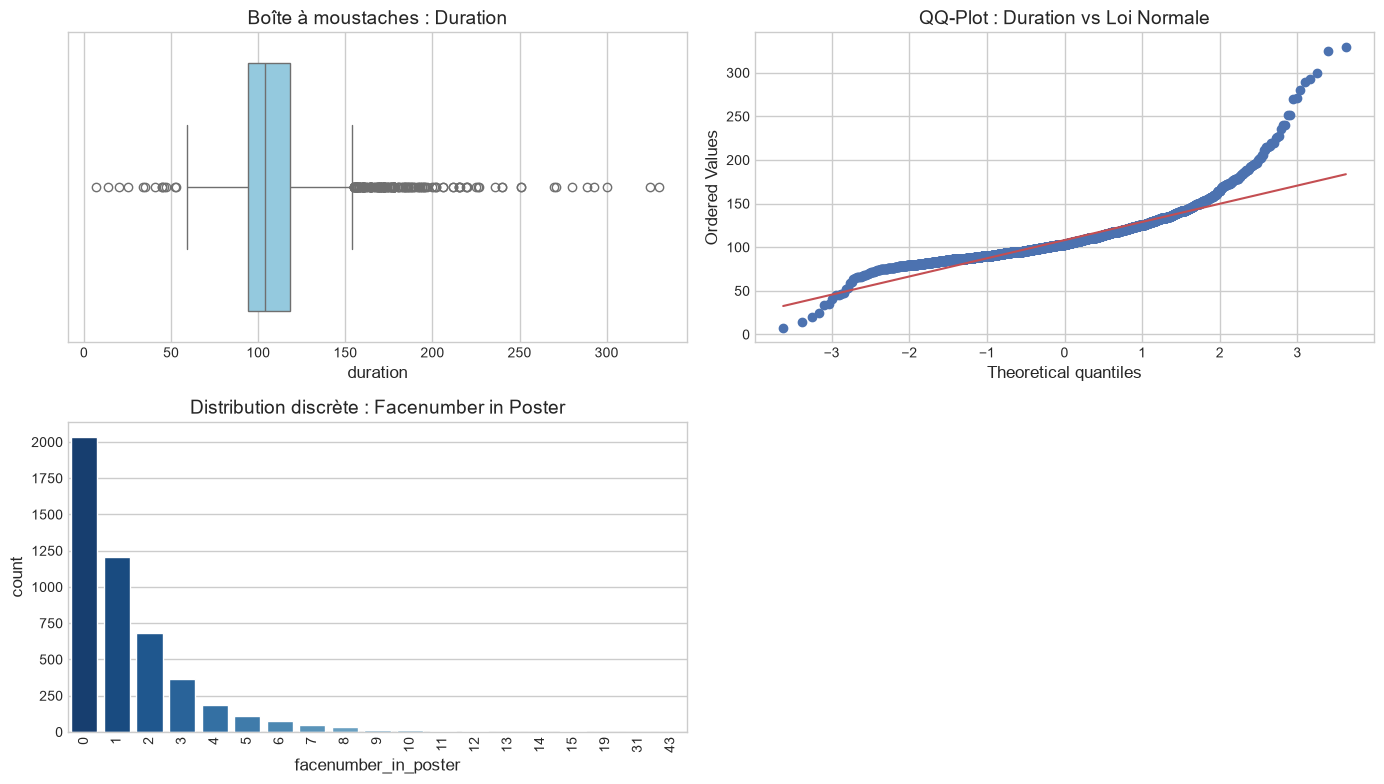

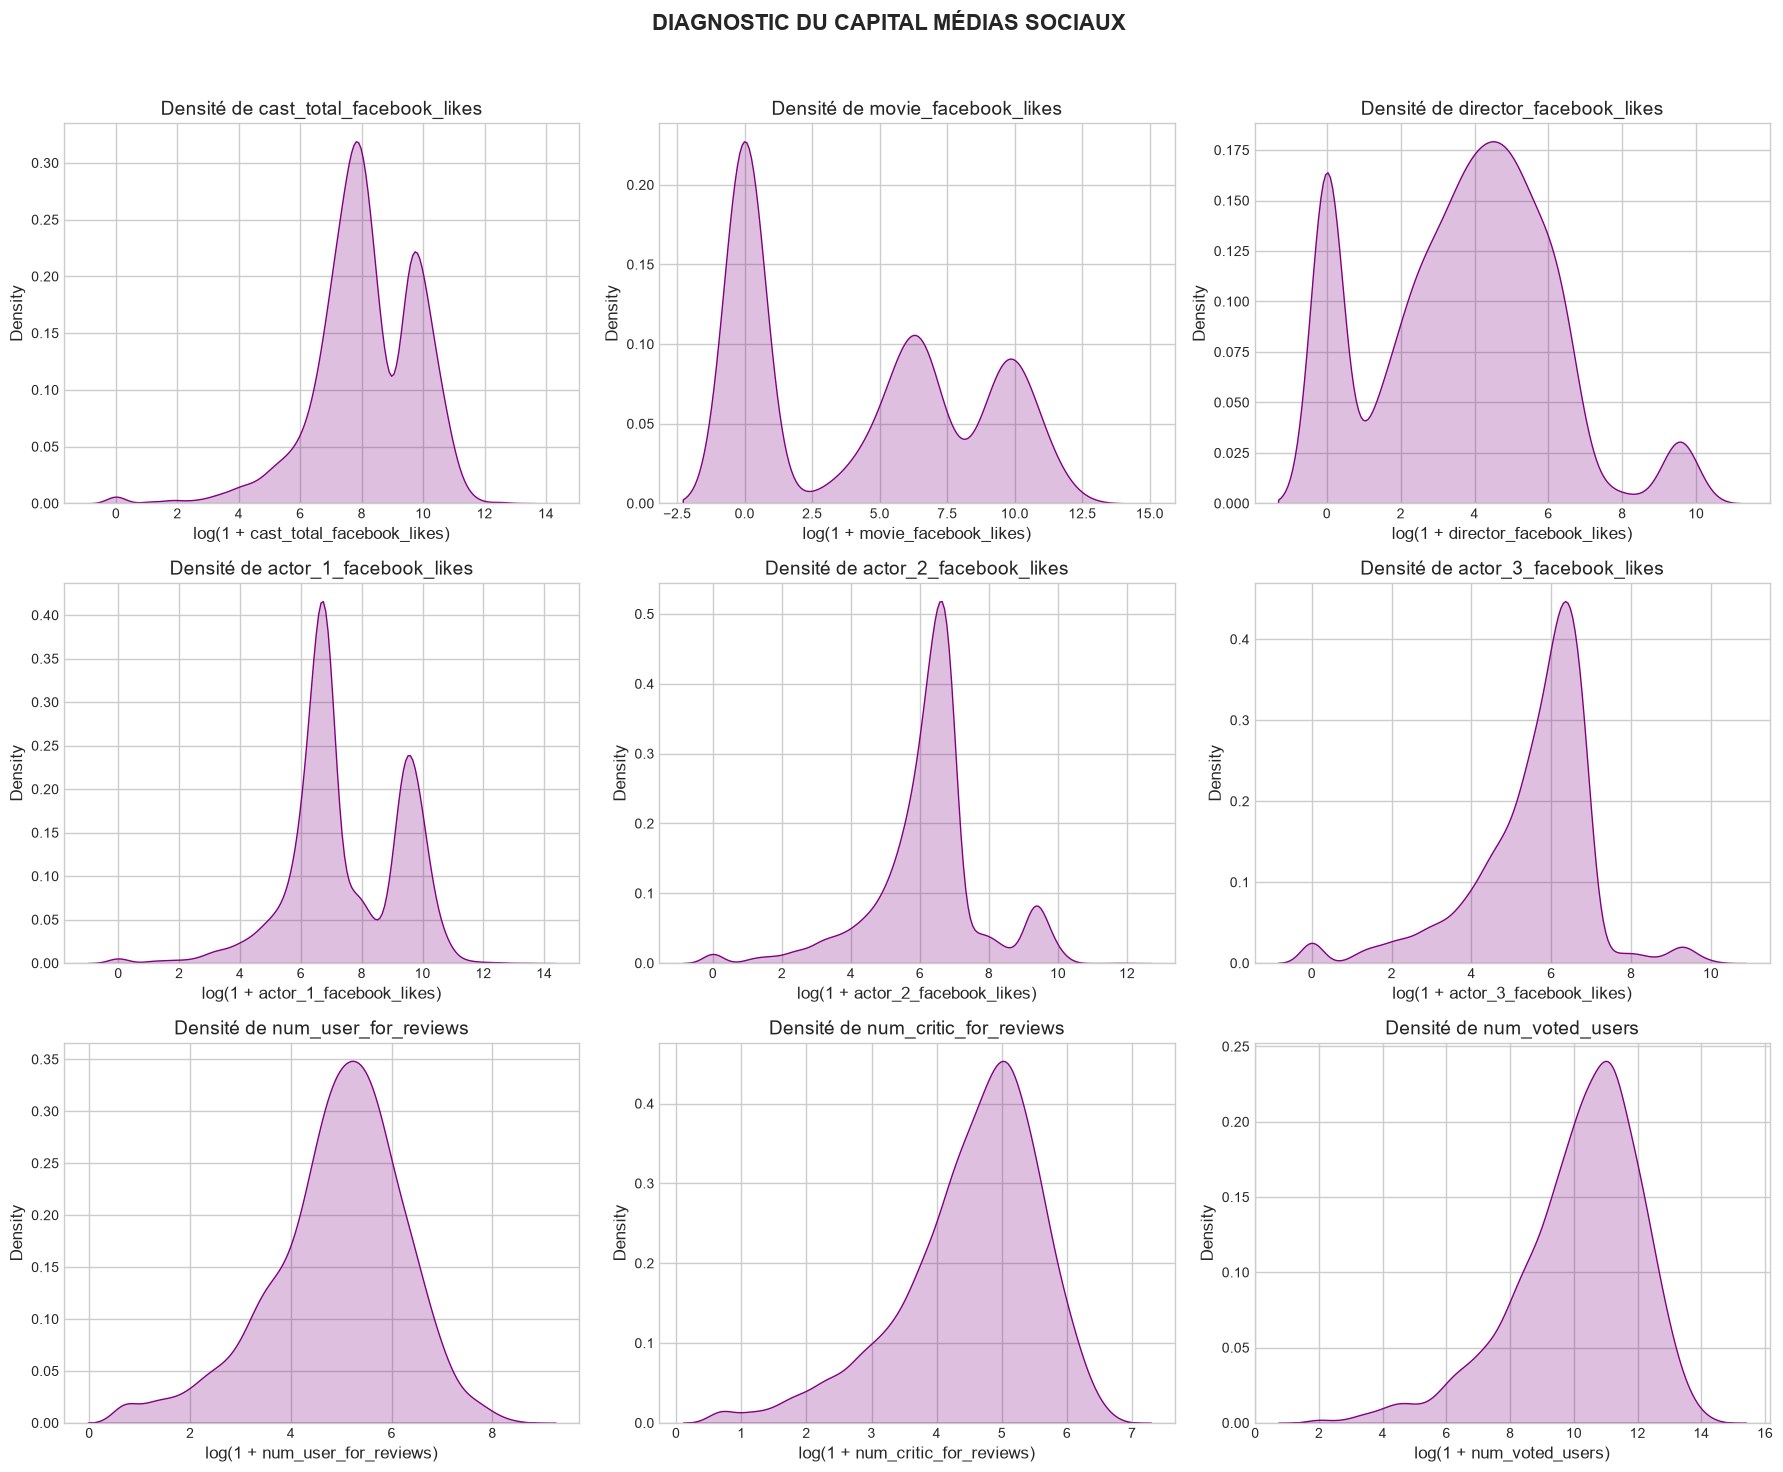

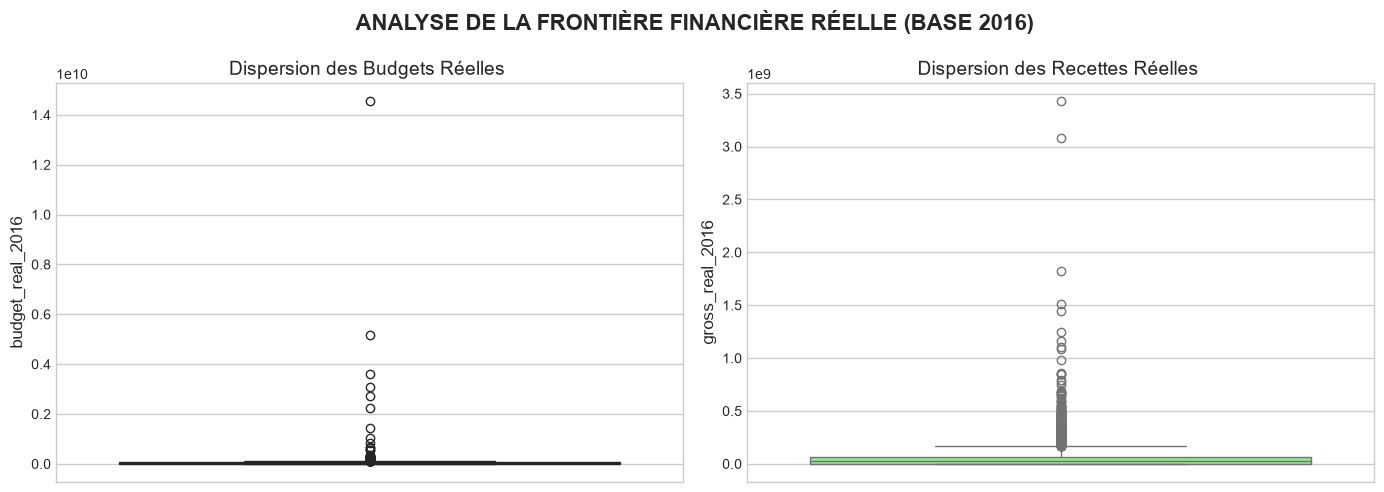

In [234]:
# Fonction pour apercevoir les distributions et l'asymétrie des variables
def diagnostic_descriptif_outliers(df):
    
    # Compasante 1 Duration - facenumber_in_poster
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    
    sns.boxplot(data=df, x='duration', ax=axes[0, 0], color='skyblue')
    axes[0, 0].set_title("Boîte à moustaches : Duration")
    
    stats.probplot(df['duration'].dropna(), dist="norm", plot=axes[0, 1])
    axes[0, 1].set_title("QQ-Plot : Duration vs Loi Normale")
    
    sns.countplot(data=df, x='facenumber_in_poster', ax=axes[1, 0], palette='Blues_r')
    axes[1, 0].set_title("Distribution discrète : Facenumber in Poster")
    axes[1, 0].tick_params(axis='x', rotation=90)
    
    # Masquage du dernier sous-graphique inutile
    axes[1, 1].axis('off')
    plt.tight_layout()
    plt.show()

    
    # COMPOSANT 2 : Variables des Réseaux Sociaux 
    
    likes_cols = ['cast_total_facebook_likes', 'movie_facebook_likes', 'director_facebook_likes',
                    'actor_1_facebook_likes', 'actor_2_facebook_likes', 'actor_3_facebook_likes', 
                    'num_user_for_reviews', 'num_critic_for_reviews', 'num_voted_users']
    fig, axes = plt.subplots(3, 3, figsize=(18, 15))
    fig.suptitle("DIAGNOSTIC DU CAPITAL MÉDIAS SOCIAUX ", fontsize=16, fontweight='bold')
    
    for i, col in enumerate(likes_cols):
        row = i // 3
        col_idx = i % 3
        sns.kdeplot(np.log1p(df[col]),ax=axes[row, col_idx], fill=True, color='purple')
        axes[row, col_idx].set_title(f"Densité de {col}")
        axes[row, col_idx].set_xlabel(f"log(1 + {col})")
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

   
    # COMPOSANT 3 : Performance Économique Réelle (Base 2016)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(" ANALYSE DE LA FRONTIÈRE FINANCIÈRE RÉELLE (BASE 2016)", fontsize=16, fontweight='bold')
    
    sns.boxplot(data=df, y='budget_real_2016', ax=axes[0], color='teal')
    axes[0].set_title("Dispersion des Budgets Réelles ")

    
    sns.boxplot(data=df, y='gross_real_2016', ax=axes[1], color='lightgreen')
    axes[1].set_title("Dispersion des Recettes Réelles ")
    
    plt.tight_layout()
    plt.show()

# Exécution du diagnostic visuel
diagnostic_descriptif_outliers(df)

In [235]:
def execution_pipeline_outliers(dataframe):
    df_out = dataframe.copy()

    # Traitement de duration
    for col in ['duration']:
        q1 = df_out[col].quantile(0.25)
        q3 = df_out[col].quantile(0.75)
        iqr = q3 - q1
        # Bornage strict sur l'intervalle de Tukey
        df_out[col] = df_out[col].clip(lower=max(0, q1 - 1.5 * iqr), upper=q3 + 1.5 * iqr)
    print("Traitement de duration TERMINE")

    # Traitement de facenumber_in_poster 
    # Comme il y'a une forte asymétrie, on va élargir l'intervalle interquatile
    q1_face = df_out['facenumber_in_poster'].quantile(0.25)
    q3_face = df_out['facenumber_in_poster'].quantile(0.75)
    iqr_face = q3_face - q1_face
    df_out['facenumber_in_poster'] = df_out['facenumber_in_poster'].clip(upper=q3_face + 3.0 * iqr_face)
    print("Traitement de facenumber_in_poster TERMINE")

    # TRAITEMENT DES RÉSEAUX SOCIAUX & ENGAGEMENT (Winsorisation haute au centile 90%) 
    # On préserve l'explosion de popularité du  tout en coupant le bruit de la queue de distribution ultime
    cols_social_engagement = [
        'movie_facebook_likes', 'director_facebook_likes', 'actor_1_facebook_likes',
        'actor_2_facebook_likes', 'actor_3_facebook_likes', 'cast_total_facebook_likes',
        'num_user_for_reviews', 'num_critic_for_reviews', 'num_voted_users'
    ]
    for col in cols_social_engagement:
        p_90 = df_out[col].quantile(0.90)  
        #  Conversion si la colonne est entière
        if pd.api.types.is_integer_dtype(df_out[col]):
            p_90 = int(np.round(p_90))
        df_out[col] = df_out[col].clip(lower=0, upper=p_90)
    print("Traitement des variables de medias TERMINE")

    # TRAITEMENT DU BLOC FINANCIERES (Winsorisation Bilatérale 10% - 99%) 
    for col in ['budget_real_2016', 'gross_real_2016']:
        p_10 = df_out[col].quantile(0.01)
        p_90 = df_out[col].quantile(0.99)
        df_out[col] = df_out[col].clip(lower=p_10, upper=p_90)
    print("Traitement des variables de financières ")

    return df_out

# Application 
df_traite = execution_pipeline_outliers(df)

Traitement de duration TERMINE
Traitement de facenumber_in_poster TERMINE
Traitement des variables de medias TERMINE
Traitement des variables de financières 


## 2.7 - Identification et Traitement des valeurs rares

En recommandation, une modalité rare contient un fort pouvoir discriminant pour l'utilisateur, tandis qu'un nom de réalisateur unique (qui n'a fait qu'un film) crée un îlot d'isolation (similarité de 0 avec le reste de la base). 

D'ou l'importance de traiter les valeurs rares

### 2.7.1 - Traitement des variables qui ne sont pas genders et plot_keywords

In [236]:
# Identification des valeurs rares 

# Sélection des variables qualitatives clés à traiter
cols_qualitatives = ['director_name', 'actor_1_name', 'actor_2_name', 'actor_3_name', 'color', 'country', 'language', 'content_rating']

print("--- IDENTIFICATION DES VALEURS RARES ---")
for col in cols_qualitatives:
    # Nombre total de modalités uniques
    nb_uniques = df[col].nunique()
    # Nombre de modalités qui n'apparaissent qu'une seule fois
    nb_solo = (df[col].value_counts() == 1).sum()
    print(f"Variable '{col}' : {nb_uniques} modalités uniques, dont {nb_solo} apparaissent 1 seule fois.")

--- IDENTIFICATION DES VALEURS RARES ---
Variable 'director_name' : 2376 modalités uniques, dont 1506 apparaissent 1 seule fois.
Variable 'actor_1_name' : 2031 modalités uniques, dont 1337 apparaissent 1 seule fois.
Variable 'actor_2_name' : 2948 modalités uniques, dont 2060 apparaissent 1 seule fois.
Variable 'actor_3_name' : 3443 modalités uniques, dont 2650 apparaissent 1 seule fois.
Variable 'color' : 2 modalités uniques, dont 0 apparaissent 1 seule fois.
Variable 'country' : 62 modalités uniques, dont 25 apparaissent 1 seule fois.
Variable 'language' : 47 modalités uniques, dont 21 apparaissent 1 seule fois.
Variable 'content_rating' : 15 modalités uniques, dont 0 apparaissent 1 seule fois.


#### Étape 1 : Les Variables de noms (director_name, actor_1_name, actor_2_name, actor_3_name)

Dans cette partie, nous considérons abritrairement que tout artiste/réalisateur ayant fat moins de 3 films est considéré comme rare. 

Cette considration n'a pas de fondement théorique mais provient de notre compréhension du secteur artiste

In [237]:

for col in [ 'actor_1_name', 'actor_2_name', 'actor_3_name']:
    # Calcul des effectifs
    eff = df[col].value_counts()
    
    # Identification des modalités sous le seuil de 3 films
    rares = eff[eff < 3].index
    
    # Traitement 
    df[col] = df[col].replace(rares, 'Unknown_actor')

#Pour le réalisateur 
col = 'director_name'
eff = df[col].value_counts()
    
# Identification des modalités sous le seuil de 3 films
rares = eff[eff < 3].index
    
# Traitement
df[col] = df[col].replace(rares, 'Unknown_director')

#### Étape 2 : Les Caractéristiques Géopolitiques (country, language)

 Le cinéma comme l'illustre les données est ultra-centralisé dans cette base (USA/English). Conserver des dizaines de pays représentés par un seul film reduirait fortement la similarité entre les films pour l'algorithme de recommandation.

 Ainsi, nous regrouperons sous l'étiquette 'Other' pour tout ce qui représente moins de 0.5% de la base pour la variable country et 0.10% pour la variable language. Il s'agit d'un choix arbitraire

In [238]:
# Avant traitement
print(df['language'].value_counts()/len(df['language']))

language
English                         0.934769
French                          0.015053
Spanish                         0.008363
Hindi                           0.005645
Mandarin                        0.005018
German                          0.003972
Japanese                        0.003345
Russian                         0.002300
Cantonese                       0.002300
Italian                         0.002091
Korean                          0.001673
Portuguese                      0.001673
Danish                          0.001045
Dutch                           0.000836
Hebrew                          0.000836
Swedish                         0.000836
Arabic                          0.000836
Norwegian                       0.000836
Persian                         0.000836
Chinese                         0.000627
Thai                            0.000627
Aboriginal                      0.000418
Dari                            0.000418
Zulu                            0.000418
Indones

In [239]:
# Avant traitement
print(df['country'].value_counts()/len(df['country']))


country
USA                   0.757265
UK                    0.087184
France                0.031570
Canada                0.024880
Germany               0.019653
Australia             0.010663
Spain                 0.006899
India                 0.006272
China                 0.005854
Italy                 0.004600
Japan                 0.004391
Mexico                0.003554
Hong Kong             0.003554
South Korea           0.002927
New Zealand           0.002718
Ireland               0.002509
Russia                0.002300
Denmark               0.002300
South Africa          0.001673
Brazil                0.001673
Norway                0.001464
Netherlands           0.001045
Sweden                0.001045
Thailand              0.001045
Romania               0.000836
Iran                  0.000836
Argentina             0.000836
Belgium               0.000627
Czech Republic        0.000627
Switzerland           0.000627
West Germany          0.000627
Israel                0.000627


In [240]:
for col in ['country', 'language']:
    # Calcul des proportions
    prop = df[col].value_counts(normalize=True)
    
    # Identification des modalités représentant moins de 2% de la base
    if col == 'country': 
        rares = prop[prop < 0.005].index
    else : 
       rares = prop[prop < 0.001].index
    
    # Traitement
    if col == 'country': 
        df[col] = df[col].replace(rares, 'Other_Country')
    else : 
        df[col] = df[col].replace(rares, 'Other_Language')
    

In [241]:
# Après traitement
for col in ['country', 'language']:
    print(df[col].value_counts())
    print("\n") 


country
USA              3622
UK                417
Other_Country     238
France            151
Canada            119
Germany            94
Australia          51
Spain              33
India              30
China              28
Name: count, dtype: int64


language
English           4471
French              72
Other_Language      61
Spanish             40
Hindi               27
Mandarin            24
German              19
Japanese            16
Russian             11
Cantonese           11
Italian             10
Korean               8
Portuguese           8
Danish               5
Name: count, dtype: int64




#### Étape 3 : La variable content_rating

Les classifications d'âge possèdent des équivalences historiques (ex: Passed ou Approved correspondent aux anciens systèmes d'avant la mise en place du système G, PG, R). Un regroupement statistique aveugle détruirait l'information. 

On va donc regrouper selon les similarités entre 

In [242]:
# Avant traitement
print("Fréquences de content_rating")
print(100 *df['content_rating'].value_counts()/len(df['content_rating']))


Fréquences de content_rating
content_rating
R            43.215555
PG-13        29.458499
PG           14.321556
Unrated       6.251307
Not Rated     2.320719
G             2.299812
Approved      1.128999
X             0.229981
Passed        0.188166
NC-17         0.146352
GP            0.125444
M             0.104537
TV-G          0.083630
TV-14         0.062722
TV-PG         0.062722
Name: count, dtype: float64


In [243]:
# Cartographie des équivalences et regroupement des valeurs obsolètes/rares
mapping_rating = {
    'Approved': 'G_PG', 'Passed': 'G_PG', 'G': 'G_PG', 'PG': 'G_PG',
    'PG-13': 'PG-13',
    'R': 'R',
    'X': 'NC-17', 'NC-17': 'NC-17',
    'Not Rated': 'Unrated', 'Unrated': 'Unrated'
}

# Application du dictionnaire. Les valeurs non listées ou NaN deviennent 'Other_Rating'
df['content_rating'] = df['content_rating'].map(mapping_rating).fillna('Other_Rating')

In [244]:
# Après traitement
print("Fréquences de content_rating")
print(100 *df['content_rating'].value_counts()/len(df['content_rating']))


Fréquences de content_rating
content_rating
R               43.215555
PG-13           29.458499
G_PG            17.938532
Unrated          8.572026
Other_Rating     0.439055
NC-17            0.376333
Name: count, dtype: float64


#### Étape 3 : Les Variables Multi-Valeurs (genres, plot_keywords)

Ces variables contiennent plusieurs informations dans une seule cellule séparée par des pipes |. Il ne faut pas les traiter comme des chaînes de caractères brutes, car 'Action|Sci-Fi' et 'Sci-Fi|Action' seraient vus comme deux modalités distinctes.

Pour se faire, On va crée pour chaque genre une colonne ou pour chaque mot clé, qui prendra 1 si le film possède ce genre/mot-clé, et 0 sinon. Mais, on créera des genre_rare ou key_word_rare pour l'analyse. 

Il est à noter que ces colonnes ne seront pas utiliser pour l'algorithme de recommandation

On choisit arbitrairement que : 
* Un genre est rare si il est moins de 10 films 
* un mot-clé est rare il est présent dans moins de 50 films (soit environ  1%  de la base)  

In [245]:
df1 = df.copy()
df2 = df

In [246]:
# Transformation des genres pour l'analyse

# Disjonction complète (0 ou 1 pour chaque genre)
df_genres_raw = df['genres'].str.get_dummies(sep='|')

# Définition du seuil de rareté
seuil_genre = 10
genres_frequents = df_genres_raw.sum()[df_genres_raw.sum() >= seuil_genre].index
genres_rares = df_genres_raw.sum()[df_genres_raw.sum() < seuil_genre].index

# Conservation des genres fréquents
df_genres_analyse = df_genres_raw[genres_frequents].copy()

# CRÉATION DE LA VARIABLE 'genre_rare' 
# Si le film possède AU MOINS UN des genres rares, la colonne prend la valeur 1, sinon 0
df_genres_analyse['genre_rare'] = df_genres_raw[genres_rares].max(axis=1)


In [247]:
df_genres_analyse.head()

,Action,Adventure,Animation,Biography,Comedy,Crime,Documentary,Drama,Family,Fantasy,History,Horror,Music,Musical,Mystery,Romance,Sci-Fi,Sport,Thriller,War,Western,genre_rare
0,1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0
1,1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
2,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
3,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
5,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0


In [248]:
# Transformation des mots-clés pour l'analyse

# Disjonction complète des mots-clés
df_keywords_raw = df['plot_keywords'].str.get_dummies(sep='|')

# Définition du seuil 
seuil_keyword = 50
keywords_frequents = df_keywords_raw.sum()[df_keywords_raw.sum() >= seuil_keyword].index
keywords_rares = df_keywords_raw.sum()[df_keywords_raw.sum() < seuil_keyword].index

# Conservation des mots-clés fréquents
df_keywords_analyse = df_keywords_raw[keywords_frequents].copy()

# 4CRÉATION DE LA VARIABLE 'mot_cle_rare'
df_keywords_analyse['mot_cle_rare'] = df_keywords_raw[keywords_rares].max(axis=1)

In [249]:
df_keywords_analyse.head()

,Unknown,alien,boy,death,dog,drugs,escape,fbi,female protagonist,friend,friendship,high school,island,love,marriage,money,murder,new york city,party,police,prison,revenge,school,sex,wedding,mot_cle_rare
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
5,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


In [250]:
# Fusion des bases avec la base df

# On regroupe tout dans un DataFrame propre pour vos analyses
df = pd.concat([df, df_genres_analyse, df_keywords_analyse], axis=1)

print("Résultat de la création des genres")
print(f"Genres conservés : {len(genres_frequents)} | Genres basculés en 'rare' : {len(genres_rares)}")
print(f"Mots-clés conservés : {len(keywords_frequents)} | Mots-clés basculés en 'rare' : {len(keywords_rares)}")

Résultat de la création des genres
Genres conservés : 21 | Genres basculés en 'rare' : 3
Mots-clés conservés : 25 | Mots-clés basculés en 'rare' : 7940


On va les variables genres et plot_key_worrds initiales car elles serviront à l'algorithme de recommandation

In [251]:
print("Le traitement de la base est terminé.")
display(df.head())

Le traitement de la base est terminé.


,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,genres,actor_1_name,movie_title,num_voted_users,cast_total_facebook_likes,actor_3_name,facenumber_in_poster,plot_keywords,num_user_for_reviews,language,country,content_rating,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes,budget_real_2016,gross_real_2016,Action,Adventure,Animation,Biography,Comedy,Crime,Documentary,Drama,Family,Fantasy,History,Horror,Music,Musical,Mystery,Romance,Sci-Fi,Sport,Thriller,War,Western,genre_rare,Unknown,alien,boy,death,dog,drugs,escape,fbi,female protagonist,friend,friendship,high school,island,love,marriage,money,murder,new york city,party,police,prison,revenge,school,sex,wedding,mot_cle_rare
0,Color,James Cameron,723,178.0,0,855,Joel David Moore,1000,Action|Adventure|Fantasy|Sci-Fi,CCH Pounder,Avatar,886204,4834,Wes Studi,0,avatar|future|marine|native|paraplegic,3054,English,USA,PG-13,2009,936,7.9,1.78,33000,265137009.000778,850794285.237062,1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
1,Color,Gore Verbinski,302,169.0,563,1000,Orlando Bloom,40000,Action|Adventure|Fantasy,Johnny Depp,Pirates of the Caribbean: At World's End,471220,48350,Jack Davenport,0,goddess|marriage ceremony|marriage proposal|pirate|singapore,1238,English,USA,PG-13,2007,5000,7.1,2.35,0,347262037.153517,358147720.424255,1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2,Color,Sam Mendes,602,148.0,0,161,Unknown_actor,11000,Action|Adventure|Thriller,Christoph Waltz,Spectre,275868,11700,Unknown_actor,1,bomb|espionage|sequel|spy|terrorist,994,English,UK,PG-13,2015,393,6.8,2.35,85000,248090878.853978,202598277.190754,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
3,Color,Christopher Nolan,813,164.0,22000,23000,Christian Bale,27000,Action|Thriller,Tom Hardy,The Dark Knight Rises,1144337,106759,Unknown_actor,0,deception|imprisonment|lawlessness|police officer|terrorist plot,2701,English,USA,PG-13,2012,23000,8.5,2.35,164000,261338769.50137,468455642.224555,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
5,Color,Andrew Stanton,462,132.0,475,530,Samantha Morton,640,Action|Adventure|Sci-Fi,Unknown_actor,John Carter,212204,1873,Unknown_actor,1,alien|american civil war|male nipple|mars|princess,738,English,USA,PG-13,2012,632,6.6,2.35,24000,275660134.070045,76372261.085022,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


In [252]:
# df.to_csv("movie_dataset_propre_2.csv", index=False, encoding="utf-8")

# 3 - Construction de variables pertinentes pour notre analyse

## 3.1 -  Variables pour l'Analyse Financière (Rentabilité, Budgets, Profits)

In [253]:
df['profit_real_2016'] = df['gross_real_2016'] - df['budget_real_2016']

df['roi_real_2016'] = df['gross_real_2016'] / df['budget_real_2016']

df['is_profitable'] = (df['profit_real_2016'] > 0).astype(int)

df['profit_margin_2016'] = np.where(df['gross_real_2016'] > 0, 
                                    (df['profit_real_2016'] / df['gross_real_2016']) * 100, 
                                    0)

## 3.2 - Variables pour la Popularité et l'Engagement (Réseaux Sociaux & Avis) 

* social_media_score (Popularité Digitale) : Somme ou combinaison des likes Facebook pour mesurer l'attraction moderne du film.

Formule : movie_facebook_likes + cast_total_facebook_likes


* review_engagement_ratio (Intensité des critiques) : Permet de voir si un film pousse les spectateurs à écrire un avis plutôt qu'à simplement voter.

Formule : num_user_for_reviews / num_voted_users

In [254]:
df['social_media_score'] = df['movie_facebook_likes'] + df['cast_total_facebook_likes'] 

df['review_engagement_ratio'] = df['num_user_for_reviews'] / df['num_voted_users'] 

## 3.3 - Variables pour le Système de Recommandation basé sur le Contenu

Pour éviter que le modèle de recommandation, créer des plusieurs colonnes, on va fusionner certaines. On ca crée la variables Soupe de Mots comme suit :

metadata_soup (La soupe de caractéristiques) : Elle fusionne le réalisateur, les acteurs principaux et les genres dans une seule chaîne de caractères par film.

In [255]:
# Préparation des chaînes pour éviter que les espaces dans les noms bloquent l'algorithme  pour être compté comme UN SEUL mot clé
def clean_data(x):
    if isinstance(x, str):
        return str.lower(x.replace(" ", ""))
    return ""
cols = ['director_name', 'actor_1_name', 'actor_2_name', 'actor_3_name', 'color', 'language', 'country']
cols_clean =[]
for col in cols: 
    df[col + '_clean'] = df[col].apply(clean_data)
    cols_clean.append(col+'_clean')

# Transformation des genres en minuscules
df['genres_clean'] = df['genres'].str.lower().str.replace('|', ' ', regex=False)

# Transformation des plot_keywords en minuscules
df['plot_keywords_clean'] = df['genres'].str.lower().str.replace('|', ' ', regex=False)
 
# Transformation de la durée en Catégorie
df["categorie_duration"] = pd.qcut( df["duration"], q=5,
    labels=[ "classe_duree1", "classe_duree2", "classe_duree3",
        "classe_duree4", "classe_duree5"
    ]) 

#  Creation de la variable categoie_ratio
bins = [0, 1.40, 1.80, 2.00, np.inf]

labels = [ "format_classique", "format_intermediaire", "format_standard", "format_cinemascope" ]

df["categorie_aspect_ratio"] = pd.cut( df["aspect_ratio"],   bins=bins,
    labels=labels, include_lowest=True )

# Création la variable decennie 
df['decennie'] = (df['title_year'] // 10 * 10).astype(str) + "s"



# Création de la Soupe de Mots
df['metadata_soup'] = df['director_name_clean'] + ' ' + \
                      df['actor_1_name_clean'] + ' ' + \
                      df['actor_2_name_clean'] + ' ' + \
                      df['actor_3_name_clean'] + ' ' + \
                      df['genres_clean'] + ' ' + \
                      df['language_clean'] + ' ' + \
                      df['color_clean'] + ' ' + \
                      df['country_clean'] + ' ' + \
                      df['decennie'] + ' ' + \
                      df["categorie_duration"].astype(str) + ' ' + \
                      df["categorie_aspect_ratio"].astype(str) + ' ' + \
                      df["content_rating"] + ' ' + \
                      df['plot_keywords_clean']



In [256]:
pd.qcut(df["duration"], q=5).cat.categories

IntervalIndex([(6.999, 92.0], (92.0, 100.0], (100.0, 108.0], (108.0, 122.0],
               (122.0, 330.0]],
              dtype='interval[float64, right]')

In [257]:
df = df.drop(columns=[ 'categorie_aspect_ratio' , 'categorie_duration'] + cols_clean)

## 3.4 - Autres variables importantes

In [258]:
df['age'] = 2016 - df['title_year']

In [259]:
# Aperci de la base 
display(df.head())

,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,genres,actor_1_name,movie_title,num_voted_users,cast_total_facebook_likes,actor_3_name,facenumber_in_poster,plot_keywords,num_user_for_reviews,language,country,content_rating,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes,budget_real_2016,gross_real_2016,Action,Adventure,Animation,Biography,Comedy,Crime,Documentary,Drama,Family,Fantasy,History,Horror,Music,Musical,Mystery,Romance,Sci-Fi,Sport,Thriller,War,Western,genre_rare,Unknown,alien,boy,death,dog,drugs,escape,fbi,female protagonist,friend,friendship,high school,island,love,marriage,money,murder,new york city,party,police,prison,revenge,school,sex,wedding,mot_cle_rare,profit_real_2016,roi_real_2016,is_profitable,profit_margin_2016,social_media_score,review_engagement_ratio,genres_clean,plot_keywords_clean,decennie,metadata_soup,age
0,Color,James Cameron,723,178.0,0,855,Joel David Moore,1000,Action|Adventure|Fantasy|Sci-Fi,CCH Pounder,Avatar,886204,4834,Wes Studi,0,avatar|future|marine|native|paraplegic,3054,English,USA,PG-13,2009,936,7.9,1.78,33000,265137009.000778,850794285.237062,1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,585657276.236283,3.208885,1,68.836532,37834,0.003446,action adventure fantasy sci-fi,action adventure fantasy sci-fi,2000s,jamescameron cchpounder joeldavidmoore wesstudi action adventure fantasy sci-fi english color usa 2000s classe_duree5 format_intermediaire PG-13 action adventure fantasy sci-fi,7
1,Color,Gore Verbinski,302,169.0,563,1000,Orlando Bloom,40000,Action|Adventure|Fantasy,Johnny Depp,Pirates of the Caribbean: At World's End,471220,48350,Jack Davenport,0,goddess|marriage ceremony|marriage proposal|pirate|singapore,1238,English,USA,PG-13,2007,5000,7.1,2.35,0,347262037.153517,358147720.424255,1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,10885683.270738,1.031347,1,3.039439,48350,0.002627,action adventure fantasy,action adventure fantasy,2000s,goreverbinski johnnydepp orlandobloom jackdavenport action adventure fantasy english color usa 2000s classe_duree5 format_cinemascope PG-13 action adventure fantasy,9
2,Color,Sam Mendes,602,148.0,0,161,Unknown_actor,11000,Action|Adventure|Thriller,Christoph Waltz,Spectre,275868,11700,Unknown_actor,1,bomb|espionage|sequel|spy|terrorist,994,English,UK,PG-13,2015,393,6.8,2.35,85000,248090878.853978,202598277.190754,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,-45492601.663225,0.816629,0,-22.454585,96700,0.003603,action adventure thriller,action adventure thriller,2010s,sammendes christophwaltz unknown_actor unknown_actor action adventure thriller english color uk 2010s classe_duree5 format_cinemascope PG-13 action adventure thriller,1
3,Color,Christopher Nolan,813,164.0,22000,23000,Christian Bale,27000,Action|Thriller,Tom Hardy,The Dark Knight Rises,1144337,106759,Unknown_actor,0,deception|imprisonment|lawlessness|police officer|terrorist plot,2701,English,USA,PG-13,2012,23000,8.5,2.35,164000,261338769.50137,468455642.224555,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,207116872.723185,1.792523,1,44.212697,270759,0.00236,action thriller,action thriller,2010s,christophernolan tomhardy christianbale unknown_actor action thriller english color usa 2010s classe_duree5 format_cinemascope PG-13 action thriller,4
5,Color,Andrew Stanton,462,132.0,475,530,Samantha Morton,640,Action|Adventure|Sci-Fi,Unknown_actor,John Carter,212204,1873,Unknown_actor,1,alien|american civil war|male nipple|mars|princess,738,English,USA,PG-13,2012,632,6.6,2.35,24000,275660134.070045,76372261.085022,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,-199287872.985022,0.277052,0,-260.942743,25873,0.003478,action adventure sci-f

# 4 - ANALYSE EXPLORATOIRE STATISTIQUE ET FINANCIERE

De manière générale, voici la situation de financière des films de notre base : 

In [260]:
#  Le Tableau de Synthèse Financière :

print("TABLEAU DE SYNTHÈSE DES INDICATEURS FINANCIERS GLOBAUX")


# Calcul des indicateurs statistiques clés
indicateurs = ['budget_real_2016', 'gross_real_2016', 'profit_real_2016']
tableau_finance = df[indicateurs].describe().loc[['mean', '50%', 'std', 'min', 'max']]
tableau_finance.index = ['Moyenne', 'Médiane (50%)', 'Écart-Type', 'Minimum', 'Maximum']

# Affichage du tableau
pd.set_option('display.float_format', lambda x: f"${x:,.2f}")
print(tableau_finance)


TABLEAU DE SYNTHÈSE DES INDICATEURS FINANCIERS GLOBAUX
                budget_real_2016   gross_real_2016    profit_real_2016
Moyenne           $47,922,747.55    $59,584,985.06      $11,662,237.51
Médiane (50%)     $23,923,463.81    $22,921,015.00        $-560,300.10
Écart-Type       $244,221,863.16   $122,191,833.97     $265,708,914.50
Minimum                  $284.42           $164.24 $-14,540,676,399.12
Maximum       $14,543,297,314.29 $3,428,066,416.98   $3,359,437,884.79


## 4.1 - Analyse descriptive bivariée liant la langue des films à leurs performances financières 

Tout d'abord, commencons par présenter graphiquement la variables langue 

In [261]:
df['language'].value_counts()

language
English           4471
French              72
Other_Language      61
Spanish             40
Hindi               27
Mandarin            24
German              19
Japanese            16
Russian             11
Cantonese           11
Italian             10
Korean               8
Portuguese           8
Danish               5
Name: count, dtype: int64

In [262]:
# ANALYSE ECONOMIQUE SELON LES LANGUE 

print(" ANALYSE ECONOMIQUE SELON LES LANGUES")

# Agrégation des données financières par groupe de langues
# On calcule la moyenne du budget, des recettes (gross), du profit et du ROI,
# ainsi que le taux de films rentables (is_profitable)
analyse_langue = df.groupby('language').agg(
    Nombre_de_Films=('movie_title', 'count'),
    Budget_Moyen=('budget_real_2016', 'mean'),
    Recettes_Moyennes=('gross_real_2016', 'mean'),
    Profit_Moyen=('profit_real_2016', 'mean'),
    ROI_Moyen=('roi_real_2016', 'mean'),
    Taux_Succes_Commercial=('is_profitable', 'mean')
).reset_index()

# 2. Conversion du taux de succès en pourcentage pour la lisibilité
analyse_langue['Taux_Succes_Commercial'] = analyse_langue['Taux_Succes_Commercial'] * 100

# 3. Tri par profit moyen pour identifier les blocs linguistiques les plus performants
analyse_langue = analyse_langue.sort_values(by='Profit_Moyen', ascending=False)

# Affichage du tableau croisé
print(analyse_langue.to_string(index=False, formatters={
    'Budget_Moyen': '{:,.2f}$'.format,
    'Recettes_Moyennes': '{:,.2f}$'.format,
    'Profit_Moyen': '{:,.2f}$'.format,
    'ROI_Moyen': '{:.2f}x'.format,
    'Taux_Succes_Commercial': '{:.1f}%'.format
}))


 ANALYSE ECONOMIQUE SELON LES LANGUES
      language  Nombre_de_Films      Budget_Moyen Recettes_Moyennes       Profit_Moyen ROI_Moyen Taux_Succes_Commercial
       English             4471    41,851,325.92$    63,325,286.25$     21,473,960.33$     5.90x                  49.3%
       Italian               10    10,909,223.00$    10,972,972.31$         63,749.31$     2.58x                  30.0%
    Portuguese                8     7,364,623.05$     2,408,906.79$     -4,955,716.27$     0.55x                  25.0%
       Russian               11    15,591,880.81$     8,119,405.71$     -7,472,475.10$     0.52x                  27.3%
     Cantonese               11    16,568,513.01$     8,638,387.20$     -7,930,125.81$     1.03x                  18.2%
        German               19    15,475,334.17$     4,329,049.09$    -11,146,285.08$     0.60x                  10.5%
        Danish                5    15,397,355.00$       855,105.46$    -14,542,249.53$     0.31x                  20.0%
  

* On remarquere que les films en anglais ont des budgets et des profits absolus colossaux. En revanche, le groupe 'Other_Language' (films étrangers, cinéma indépendant asiatique ou européen) affiche parfois un ROI moyen supérieur. Cela s'explique par le fait que ces films coûtent très peu cher à produire (petit budget) et rentabilisent très vite leur investissement initial.

* En observant le pourcentage de films rentables par langue, on peut déterminer si le marché anglophone est plus risqué (gros investissements mais beaucoup d'échecs au box-office) que les marchés extérieurs aux USA. La réponse est non. Le taux de succès en amérique est le plus élevé

## 4.2 - Analyse descriptive bivariée liant les genres des films à leurs performances financières 

Présentons prémièrement la distribution du genre

findfont: Failed to find font weight semibold for Arial, now using 700.


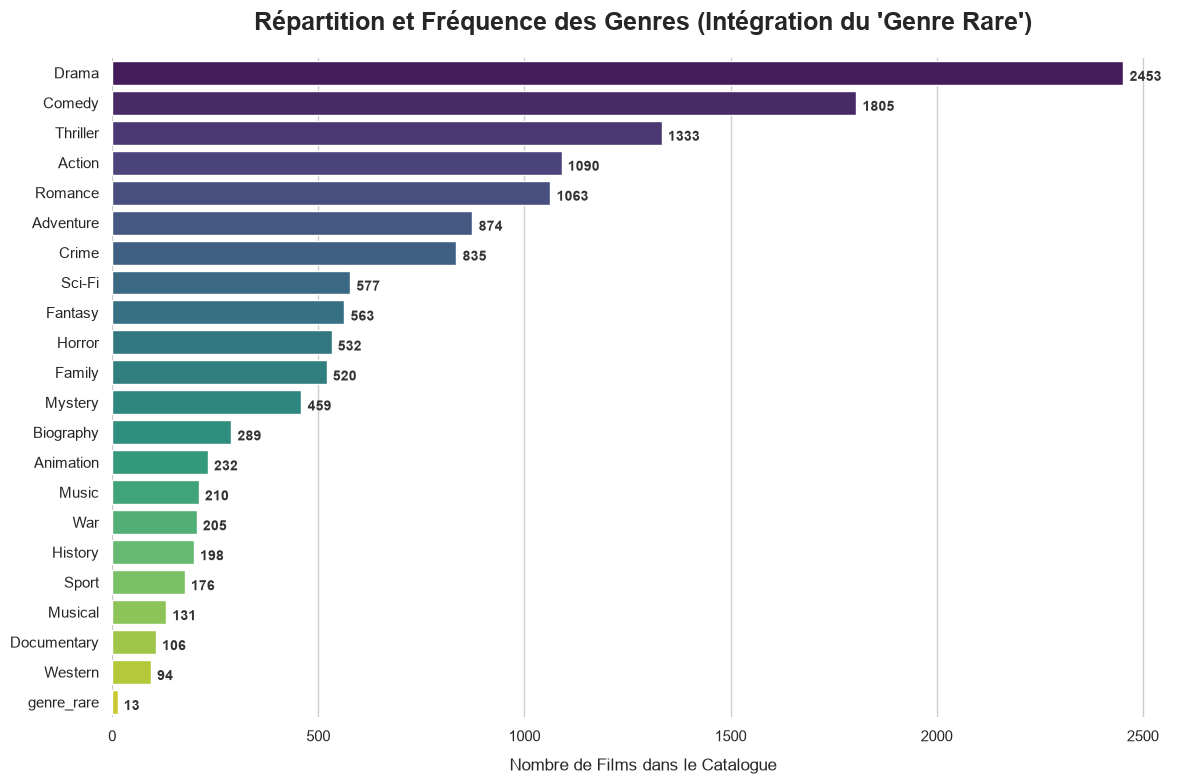

In [263]:
# Récupération des fréquences de nos genres (incluant 'genre_rare')
# df_genres_analyse est le DataFrame créé à l'étape précédente contenant les 0 et 1
total_genres = df_genres_analyse.sum().sort_values(ascending=False).reset_index()
total_genres.columns = ['Genre', 'Nombre_de_Films']

# Configuration du style graphique
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 8))

# Création du barplot avec une couleur dégradée esthétique
palette_custom = sns.color_continuous_scale = sns.color_palette("viridis", len(total_genres))
ax = sns.barplot(
    x="Nombre_de_Films", 
    y="Genre", 
    data=total_genres, 
    palette=palette_custom,
    hue="Genre",
    legend=False
)

# Personnalisation haut de gamme (Élimination des bordures inutiles)
sns.despine(left=True, bottom=True)
plt.title("Répartition et Fréquence des Genres (Intégration du 'Genre Rare')", fontsize=18, fontweight='bold', pad=20)
plt.xlabel("Nombre de Films dans le Catalogue", fontsize=12, labelpad=10)
plt.ylabel("", fontsize=12)

# Ajout des valeurs numériques au bout de chaque barre pour une lecture instantanée
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.text(width + 15, p.get_y() + p.get_height()/2 + 0.15, 
                f'{int(width)}', 
                ha="left", va="center", fontsize=10, fontweight='semibold', color='#333333')

plt.tight_layout()
plt.show()


Poursuivons maintenant avec l'analyse croisée

In [264]:
print(" ANALYSE CROISÉE : PERFORMANCE FINANCIÈRE PAR GENRE DE FILM")

stats_genres = []

# df_genres_analyse contient vos colonnes de genres (Action, Comedy, genre_rare, etc.)
for genre in df_genres_analyse.columns:
    df_genre_specifique = df[df[genre] == 1]
    
    if not df_genre_specifique.empty:
        stats_genres.append({
            'Genre': genre,
            'Volume_Films': len(df_genre_specifique),
            'Budget_Moyen': df_genre_specifique['budget_real_2016'].mean(),
            'Gross_Moyen': df_genre_specifique['gross_real_2016'].mean(),
            'Profit_Moyen': df_genre_specifique['profit_real_2016'].mean(),
            'ROI_Moyen': df_genre_specifique['roi_real_2016'].mean(),
            'Marge_Nette_Moyenne_%': df_genre_specifique['profit_margin_2016'].mean(),
            'Taux_Succes_%': df_genre_specifique['is_profitable'].mean() * 100
        })

# Conversion et tri par Marge Bénéficiaire Nette Moyenne
df_croisement_genres = pd.DataFrame(stats_genres).sort_values(by='Marge_Nette_Moyenne_%', ascending=False)

# Affichage du tableau formaté à spectre large
pd.set_option('display.float_format', lambda x: f"{x:,.2f}")
print(df_croisement_genres.to_string(index=False, formatters={
    'Budget_Moyen': '${:,.0f}'.format,
    'Gross_Moyen': '${:,.0f}'.format,
    'Profit_Moyen': '${:,.0f}'.format,
    'ROI_Moyen': '{:.2f}x'.format,
    'Marge_Nette_Moyenne_%': '{:.1f}%'.format,
    'Taux_Succes_%': '{:.1f}%'.format
}))


 ANALYSE CROISÉE : PERFORMANCE FINANCIÈRE PAR GENRE DE FILM
      Genre  Volume_Films Budget_Moyen  Gross_Moyen Profit_Moyen ROI_Moyen Marge_Nette_Moyenne_% Taux_Succes_%
      Sport           176  $35,327,083  $50,936,502  $15,609,420     3.12x               -628.8%         47.7%
  Biography           289  $35,509,128  $49,873,307  $14,364,179    11.37x               -870.4%         44.6%
    Western            94  $43,582,818  $55,312,812  $11,729,994     1.88x              -1363.6%         31.9%
Documentary           106   $4,858,458  $12,844,729   $7,986,271    31.95x              -1542.8%         52.8%
    Musical           131  $52,754,747 $124,481,113  $71,726,366     3.46x              -2067.4%         47.3%
      Music           210  $26,382,074  $45,102,121  $18,720,046     3.34x              -2179.0%         51.0%
 genre_rare            13   $8,281,273  $11,583,192   $3,301,920    15.66x              -2453.6%         53.8%
    Mystery           459  $39,782,585  $51,736,296 

c:\Users\user\movie-profitability-and-recommendation\env\Lib\site-packages\matplotlib\collections.py:1121: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor
findfont: Failed to find font weight semibold for Arial, now using 700.
c:\Users\user\movie-profitability-and-recommendation\env\Lib\site-packages\matplotlib\collections.py:1121: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor


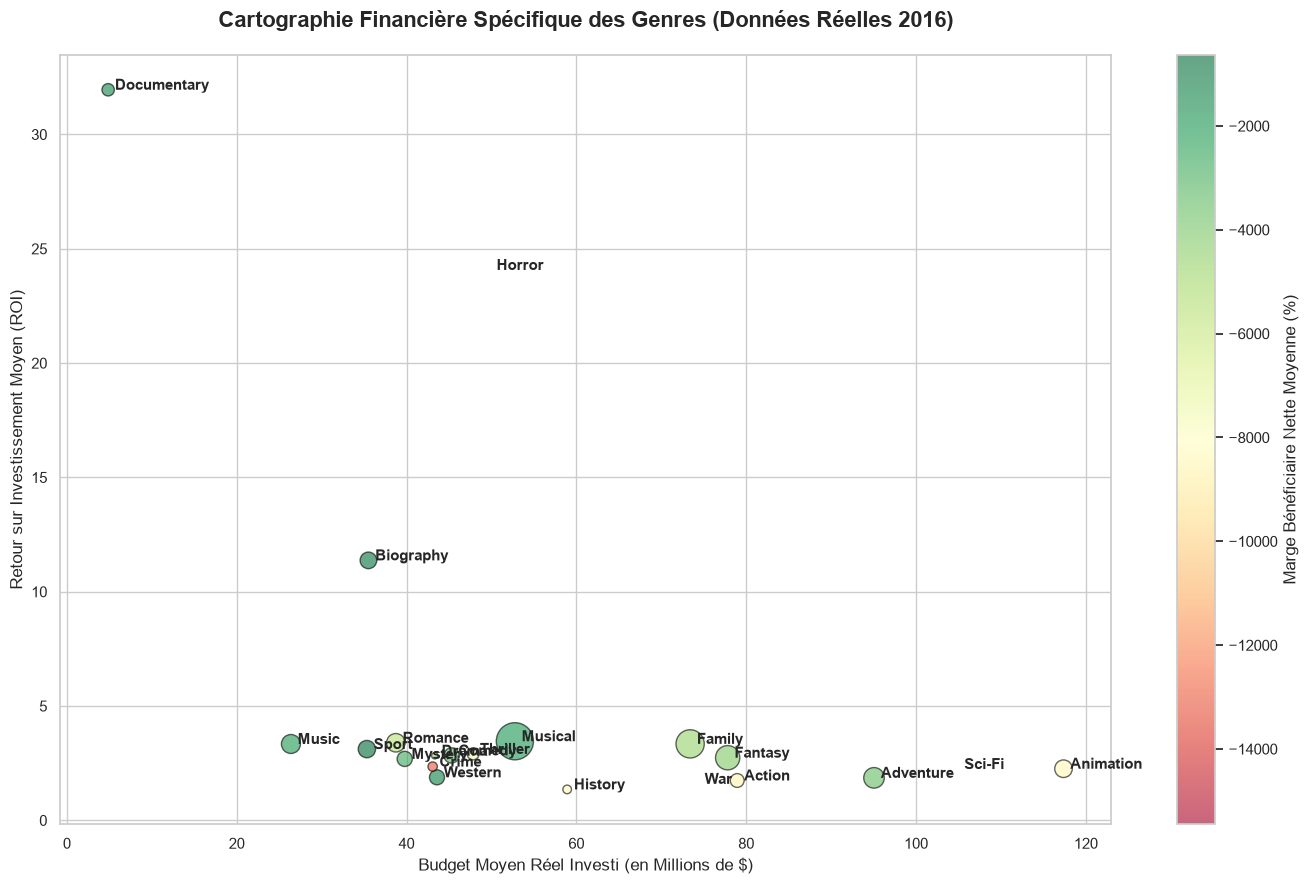

In [265]:
# Graphique à Bulles des Performances 
plt.figure(figsize=(14, 9))
sns.set_theme(style="whitegrid")

df_graph_genres = df_croisement_genres[df_croisement_genres['Genre'] != 'genre_rare']

scatter = plt.scatter(
    x=df_graph_genres['Budget_Moyen'] / 1e6, 
    y=df_graph_genres['ROI_Moyen'],
    s=df_graph_genres['Profit_Moyen'] / 1e5, # Taille de la bulle = Volume du profit
    alpha=0.6,
    c=df_graph_genres['Marge_Nette_Moyenne_%'], # Couleur = Pourcentage de marge nette
    cmap='RdYlGn', # Dégradé du rouge (perte) au vert (fort bénéfice)
    edgecolors="black"
)

for i, row in df_graph_genres.iterrows():
    plt.text(row['Budget_Moyen']/1e6 + 0.8, row['ROI_Moyen'], row['Genre'], fontsize=11, fontweight='semibold')

plt.colorbar(scatter, label="Marge Bénéficiaire Nette Moyenne (%)")
plt.title("Cartographie Financière Spécifique des Genres (Données Réelles 2016)", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Budget Moyen Réel Investi (en Millions de $)", fontsize=12)
plt.ylabel("Retour sur Investissement Moyen (ROI)", fontsize=12)
plt.tight_layout()
plt.show()


## 4.3 - Compréhension des relations entre caractéristiques des films, popularité et performances financières

### 4.3.1 - L'Analyse Univariée Préliminaire

In [266]:
# La Carte du Monde Interactive de la Production Cinématographique

# Préparation des données pour la carte
# On compte le nombre de films par pays à partir de la colonne brute pour garder la précision géographique
frequence_pays = df['country'].value_counts().reset_index()
frequence_pays.columns = ['Pays', 'Nombre_de_Films']

# Dictionnaire de correspondance pour associer les noms IMDb aux codes ISO-3 de Plotly
iso_mapping = {
    'USA': 'USA', 'UK': 'GBR', 'France': 'FRA', 'Germany': 'DEU', 
    'Canada': 'CAN', 'Australia': 'AUS', 'India': 'IND', 'Spain': 'ESP', 
    'China': 'CHN', 'Japan': 'JPN', 'Italy': 'ITA', 'New Zealand': 'NZL'
}
frequence_pays['ISO_Code'] = frequence_pays['Pays'].map(iso_mapping)

# On filtre les pays non cartographiés pour éviter les lignes vides
df_carte = frequence_pays.dropna(subset=['ISO_Code'])

# Création de la carte Choroplethe
fig_carte = px.choropleth(
    df_carte, 
    locations="ISO_Code",
    color="Nombre_de_Films", 
    hover_name="Pays",
    color_continuous_scale=px.colors.sequential.Plasma,
    title="<b>Concentration Mondiale de la Production de Films</b>",
    labels={'Nombre_de_Films': 'Nombre de films'}
)

fig_carte.update_layout(
    title_font_size=22,
    title_x=0.5,
    geo=dict(showframe=False, showcoastlines=True, projection_type='equirectangular'),
    margin=dict(l=0, r=0, b=0, t=50)
)

# Affichage de la carte
fig_carte.show()


### 4.3.1 - Analyse bivariée et multivariée

#### Croisement Classifications (content_rating) × Rentabilité

In [267]:
print("  ANALYSE CROISÉE GLOBALE : IMPACT DE LA CLASSIFICATION D'ÂGE SUR TOUTE LA RENTABILITÉ")


df_croisement_rating = df.groupby('content_rating').agg(
    Nombre_de_Films=('movie_title', 'count'),
    Budget_Moyen=('budget_real_2016', 'mean'),
    Gross_Moyen=('gross_real_2016', 'mean'),
    Profit_Moyen=('profit_real_2016', 'mean'),
    ROI_Moyen=('roi_real_2016', 'mean'),
    Marge_Nette_Moyenne=('profit_margin_2016', 'mean'),
    Taux_Succes=('is_profitable', lambda x: x.mean() * 100)
).reset_index().sort_values(by='Marge_Nette_Moyenne', ascending=False)

print(df_croisement_rating.to_string(index=False, formatters={
    'Budget_Moyen': '${:,.0f}'.format,
    'Gross_Moyen': '${:,.0f}'.format,
    'Profit_Moyen': '${:,.0f}'.format,
    'ROI_Moyen': '{:.2f}x'.format,
    'Marge_Nette_Moyenne': '{:.1f}%'.format,
    'Taux_Succes': '{:.1f}%'.format
}))


  ANALYSE CROISÉE GLOBALE : IMPACT DE LA CLASSIFICATION D'ÂGE SUR TOUTE LA RENTABILITÉ
content_rating  Nombre_de_Films Budget_Moyen  Gross_Moyen Profit_Moyen ROI_Moyen Marge_Nette_Moyenne Taux_Succes
         NC-17               18  $10,553,487  $26,046,764  $15,493,277     4.82x                1.9%       66.7%
  Other_Rating               21  $16,321,543  $72,618,125  $56,296,582     2.86x             -311.3%       47.6%
          G_PG              858  $57,692,055 $107,537,278  $49,845,223     4.04x            -1532.6%       54.8%
         PG-13             1409  $62,485,556  $76,827,907  $14,342,350     1.82x            -1873.3%       51.2%
             R             2067  $41,644,190  $38,269,444  $-3,374,746     7.59x            -8176.1%       45.2%
       Unrated              410  $12,344,668   $8,245,647  $-4,099,020    12.77x            -8964.1%       28.3%


#### Distribution Comparée des Marges Réelles

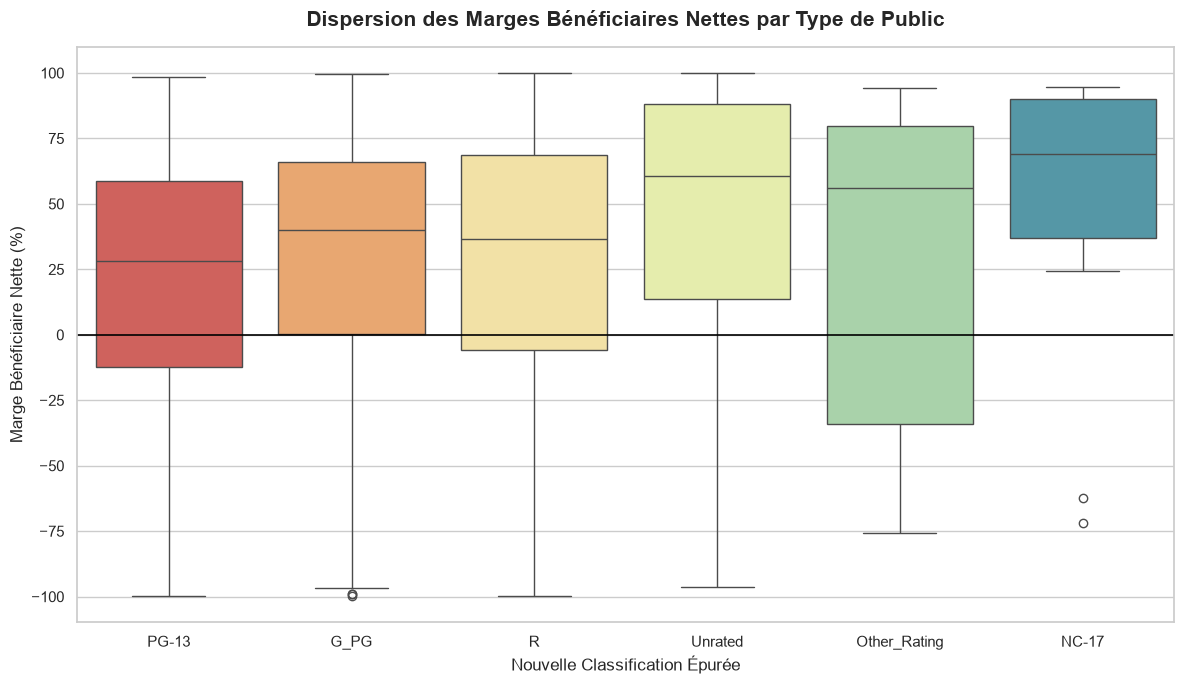

In [268]:
plt.figure(figsize=(12, 7))

# On sépare les marges situées entre -100% et +100% pour éviter d'écraser le graphique à cause de quelques aberrations mathématiques
df_boxplot_marge = df[df['profit_margin_2016'].between(-100, 100)]

sns.boxplot(
    x='content_rating', 
    y='profit_margin_2016', 
    data=df_boxplot_marge, 
    palette='Spectral',
    hue='content_rating',
    legend=False
)

plt.title("Dispersion des Marges Bénéficiaires Nettes par Type de Public", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("Nouvelle Classification Épurée", fontsize=12)
plt.ylabel("Marge Bénéficiaire Nette (%)", fontsize=12)
plt.axhline(0, color='black', linestyle='-', linewidth=1.2) # La ligne fatidique du seuil de rentabilité
plt.tight_layout()
plt.show()


#### La Matrice de Corrélation Globale

our répondre précisément aux questions clés sur l'influence des réseaux sociaux (social_media_score) et des professionnels de l'industrie (num_critic_for_reviews)

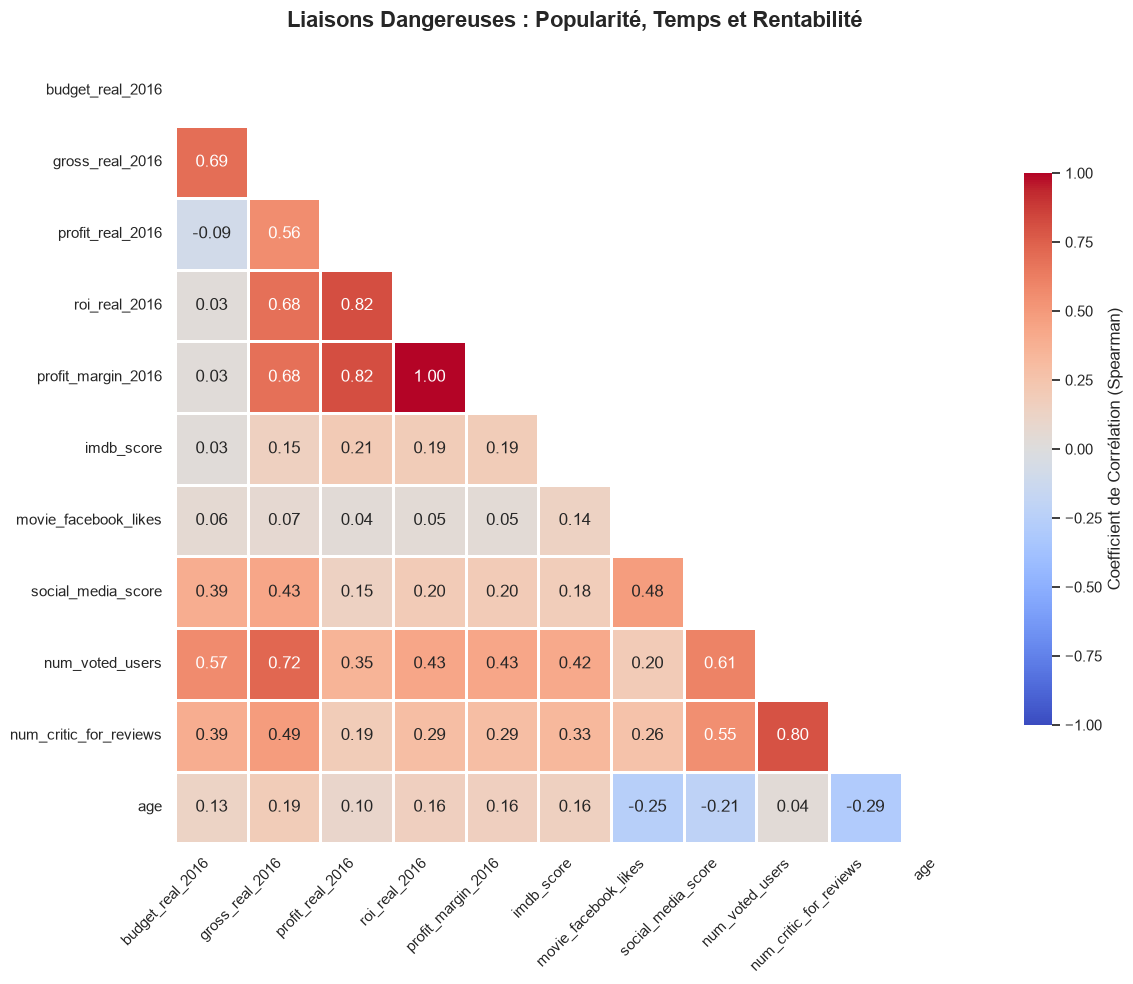

In [269]:
# Sélection des variables quantitatives
variables_multivariees = [
    'budget_real_2016', 'gross_real_2016', 'profit_real_2016', 'roi_real_2016', 'profit_margin_2016',
    'imdb_score', 'movie_facebook_likes', 'social_media_score', 
    'num_voted_users', 'num_critic_for_reviews', 'age'
]

# Calcul de la matrice
matrice_corr_globale = df[variables_multivariees].corr(method='spearman')

# Affichage graphique haut de gamme en triangle (Heatmap épurée)
plt.figure(figsize=(12, 10))
sns.set_theme(style="white")
mask = np.triu(np.ones_like(matrice_corr_globale, dtype=bool))

sns.heatmap(
    matrice_corr_globale, 
    mask=mask, 
    cmap="coolwarm", # Dégradé bleu (négatif) à rouge (positif)
    vmax=1, vmin=-1, 
    annot=True, 
    fmt=".2f", 
    linewidths=0.8,
    cbar_kws={"shrink": 0.7, "label": "Coefficient de Corrélation (Spearman)"}
)

plt.title("Liaisons Dangereuses : Popularité, Temps et Rentabilité", fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


* En observant la ligne social_media_score croisée avec profit_real_2016, on observe une corrélation positive mais modérée (0.15).Alors, avoir un casting ou un film très populaire sur Facebook aide le box-office, mais ce n'est pas un gage absolu de rentabilité. Le "buzz" virtuel ne se transforme pas automatiquement en billets vendus.

* En regardant la case reliant num_critic_for_reviews et gross_real_2016, la corrélation y est très positive et moyenne. Ainsi, l'attention des critiques professionnels est un bon indicateur des recettes massives. Plus un film génère des revues de presse (qu'elles soient bonnes ou mauvaises), plus sa visibilité médiatique augmente, ce qui remplit les salles de cinéma.

#### L'Analyse de l'Évolution Temporelle par Décennie

In [270]:
print("ÉVOLUTION TEMPORELLE DES INDICATEURS CINÉMATOGRAPHIQUES PAR DÉCENNIE")

# Agrégation par décennie
analyse_temps = df.groupby('decennie').agg(
    Nombre_de_Films=('movie_title', 'count'),
    Budget_Moyen=('budget_real_2016', 'mean'),
    Recettes_Moyennes=('gross_real_2016', 'mean'),
    Profit_Moyen=('profit_real_2016', 'mean'),
    ROI_Moyen=('roi_real_2016', 'mean'),
    Marge_Nette_Moyenne=('profit_margin_2016', 'mean'),
    Score_IMDb_Moyen=('imdb_score', 'mean')
).reset_index().sort_values(by='decennie')

print(analyse_temps.to_string(index=False, formatters={
    'Budget_Moyen': '${:,.0f}'.format,
    'Recettes_Moyennes': '${:,.0f}'.format,
    'Profit_Moyen': '${:,.0f}'.format,
    'ROI_Moyen': '{:.2f}x'.format,
    'Marge_Nette_Moyenne_': '{:.1f}%'.format,
    'Score_IMDb_Moyen': '{:.2f}/10'.format
}))


ÉVOLUTION TEMPORELLE DES INDICATEURS CINÉMATOGRAPHIQUES PAR DÉCENNIE
decennie  Nombre_de_Films Budget_Moyen Recettes_Moyennes Profit_Moyen ROI_Moyen  Marge_Nette_Moyenne Score_IMDb_Moyen
   1910s                1   $8,510,301        $3,578,606  $-4,931,695     0.42x              -137.81          8.00/10
   1920s                5  $21,542,116       $19,189,880  $-2,352,236     8.69x            -6,587.22          7.14/10
   1930s               15  $26,012,605      $476,535,555 $450,522,950    11.64x              -378.31          7.69/10
   1940s               24  $26,736,496      $177,201,432 $150,464,935     7.09x            -1,333.76          7.43/10
   1950s               27  $24,402,344       $67,954,366  $43,552,021     4.62x              -545.52          7.47/10
   1960s               71  $39,199,549      $125,774,630  $86,575,081     4.07x              -860.87          7.40/10
   1970s              108  $34,633,263      $153,834,368 $119,201,105    16.02x              -511.17     

* On constate dans le tableau que le Score_IMDb_Moyen a tendance à diminuer au fur et à mesure que l'on se rapproche des années 2010. Cela s'explique par l'effet de le variable age_du_film_2016 (corrélation positive entre l'âge et la note). Les films qui ont survécu dans la mémoire collective ( comme le TITANIC) des décennies passées sont de grands classiques très bien notés, tandis que la production moderne est plus volumineuse et comprend beaucoup de films moyens ou médiocres.

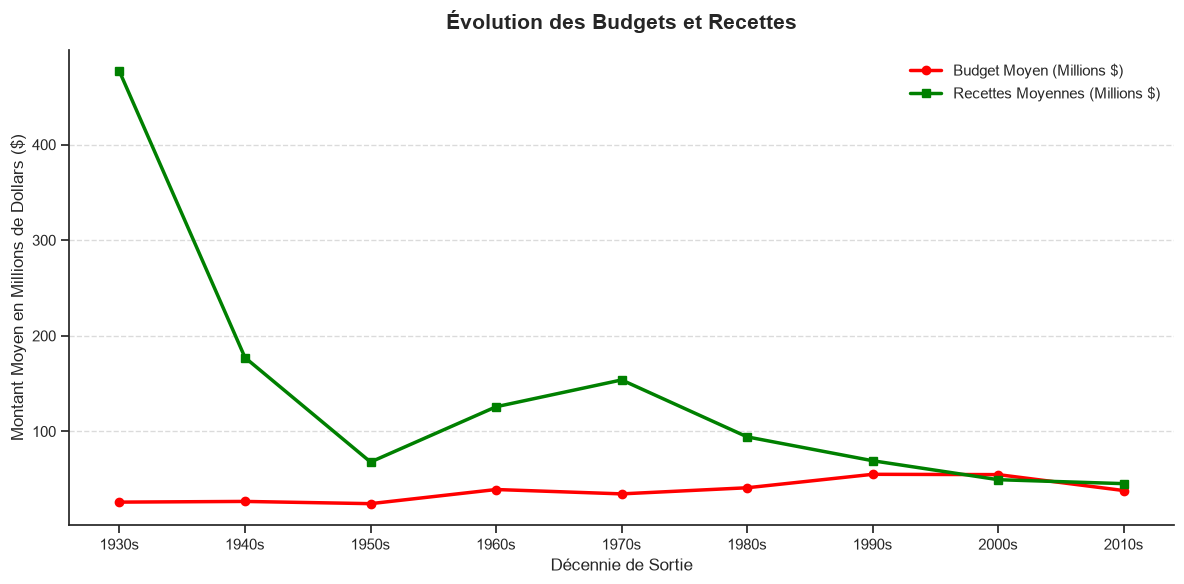

In [271]:
plt.figure(figsize=(12, 6))
sns.set_theme(style="ticks")

# Filtrage des vieilles décennies si elles contiennent trop peu de films 
df_graph_temps = analyse_temps[analyse_temps['Nombre_de_Films'] >= 10]

# Tracé des courbes Courbe Budget vs Courbe Recettes
plt.plot(df_graph_temps['decennie'], df_graph_temps['Budget_Moyen'] / 1e6, marker='o', color='red', linewidth=2.5, label='Budget Moyen (Millions $)')
plt.plot(df_graph_temps['decennie'], df_graph_temps['Recettes_Moyennes'] / 1e6, marker='s', color='green', linewidth=2.5, label='Recettes Moyennes (Millions $)')

plt.title("Évolution des Budgets et Recettes", fontsize=15, fontweight='bold', pad=15)
plt.ylabel("Montant Moyen en Millions de Dollars ($)", fontsize=12)
plt.xlabel("Décennie de Sortie", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(fontsize=11)
sns.despine()
plt.tight_layout()
plt.show()


 Les montants réels du budget et des recettes moyennes diminuent considérablement dans le temps et en 2010, les films étaient en moyen non rentable

#### Le Top 10 des films les plus rentables et des moins rentables

In [272]:
print("  TOP 10 es films les plus rentables (PROFIT ABSOLU)")


# Tri par profit_real_2016 décroissant
top_profits = df.sort_values(by='profit_real_2016', ascending=False).head(10)
print(top_profits[['movie_title', 'budget_real_2016', 'gross_real_2016', 'profit_real_2016']].to_string(index=False))


print("  TOP 10 DES FILMS LES MOINS RENTABLES : LES RENDEMENTS RECORDS (ROI)")
print("="*90)
# Filtrage de sécurité : on exclut les micro-budgets inférieurs à 50 000$ pour éviter les anomalies de calcul du ROI
top_roi = df[df['budget_real_2016'] >= 50000].sort_values(by='roi_real_2016', ascending=False).head(10)
print(top_roi[['movie_title', 'budget_real_2016', 'gross_real_2016', 'roi_real_2016']].to_string(index=False, formatters={'roi_real_2016': '{:.1f}x'.format}))

print("\n" + "="*90)
print("  TOP 10 DES FILMS LES MOINS RENTABLES : LES PIRES GOUFFRES FINANCIERS")
print("="*90)
# Tri par profit_real_2016 croissant (les plus grosses pertes)
top_flops = df.sort_values(by='profit_real_2016', ascending=True).head(10)
print(top_flops[['movie_title', 'budget_real_2016', 'gross_real_2016', 'profit_real_2016']].to_string(index=False))


  TOP 10 es films les plus rentables (PROFIT ABSOLU)
                       movie_title  budget_real_2016  gross_real_2016  profit_real_2016
                Gone with the Wind     68,628,532.19 3,428,066,416.98  3,359,437,884.79
   Snow White and the Seven Dwarfs     33,372,954.81 3,085,754,926.95  3,052,381,972.14
Star Wars: Episode IV - A New Hope     43,559,667.26 1,825,291,290.62  1,781,731,623.36
                             Bambi     17,520,146.37 1,510,533,839.57  1,493,013,693.19
                         Pinocchio     44,546,243.90 1,444,326,292.68  1,399,780,048.78
                The Sound of Music     62,461,531.87 1,243,245,649.59  1,180,784,117.72
                              Jaws     35,677,745.43 1,159,526,726.54  1,123,848,981.11
                      The Exorcist     43,244,534.53 1,105,789,775.88  1,062,545,241.35
        E.T. the Extra-Terrestrial     26,114,769.43 1,081,771,889.10  1,055,657,119.67
                         The Sting     29,730,617.49   862,728,463.

#### Liste des 10 acteurs et réalisateurs les plus rentables 

In [273]:
print("  LES 10 ACTEURS LES PLUS RENTABLES (PROFIT CUMULÉ)")

# Agrégation par acteur principal
stars_acteurs = df.groupby('actor_1_name').agg(
    Nb_Films=('movie_title', 'count'),
    Profit_Total=('profit_real_2016', 'sum'),
    ROI_Moyen=('roi_real_2016', 'mean')
).reset_index()

# Filtre sur la régularité (au moins 3 films) et tri par profit total
top_stars_acteurs = stars_acteurs[stars_acteurs['Nb_Films'] >= 3].sort_values(by='Profit_Total', ascending=False).head(10)
print(top_stars_acteurs.to_string(index=False, formatters={'Profit_Total': '${:,.0f}'.format, 'ROI_Moyen': '{:.2f}x'.format}))


print("\n" + "="*90)
print("  LES 10 RÉALISATEURS LES PLUS RENTABLES ")
print("="*90)
# Agrégation par réalisateur
stars_realisateurs = df.groupby('director_name').agg(
    Nb_Films=('movie_title', 'count'),
    Profit_Total=('profit_real_2016', 'sum'),
    ROI_Moyen=('roi_real_2016', 'mean')
).reset_index()

top_stars_realisateurs = stars_realisateurs[stars_realisateurs['Nb_Films'] >= 3].sort_values(by='Profit_Total', ascending=False).head(10)
print(top_stars_realisateurs.to_string(index=False, formatters={'Profit_Total': '${:,.0f}'.format, 'ROI_Moyen': '{:.2f}x'.format}))


  LES 10 ACTEURS LES PLUS RENTABLES (PROFIT CUMULÉ)
     actor_1_name  Nb_Films   Profit_Total ROI_Moyen
    Harrison Ford        27 $5,929,109,112    10.20x
        Tom Hanks        24 $2,381,058,292     2.59x
       Tom Cruise        24 $1,954,811,662     2.54x
   Robin Williams        27 $1,557,132,306     2.62x
     Roy Scheider         5 $1,375,903,230     7.78x
Jennifer Lawrence        15 $1,208,567,042     3.24x
  Natalie Portman        15 $1,188,770,184     1.99x
    Madeline Kahn         5 $1,185,882,880    24.14x
Leonardo DiCaprio        20 $1,153,175,780     1.41x
      Bill Murray        26 $1,112,978,268     3.40x

  LES 10 RÉALISATEURS LES PLUS RENTABLES 
       director_name  Nb_Films   Profit_Total ROI_Moyen
    Steven Spielberg        26 $5,571,202,910     5.69x
      Victor Fleming         3 $3,681,390,250    19.51x
        George Lucas         5 $3,506,763,352    40.02x
       James Cameron         7 $1,693,535,424     3.01x
      Chris Columbus        11 $1,524,717,

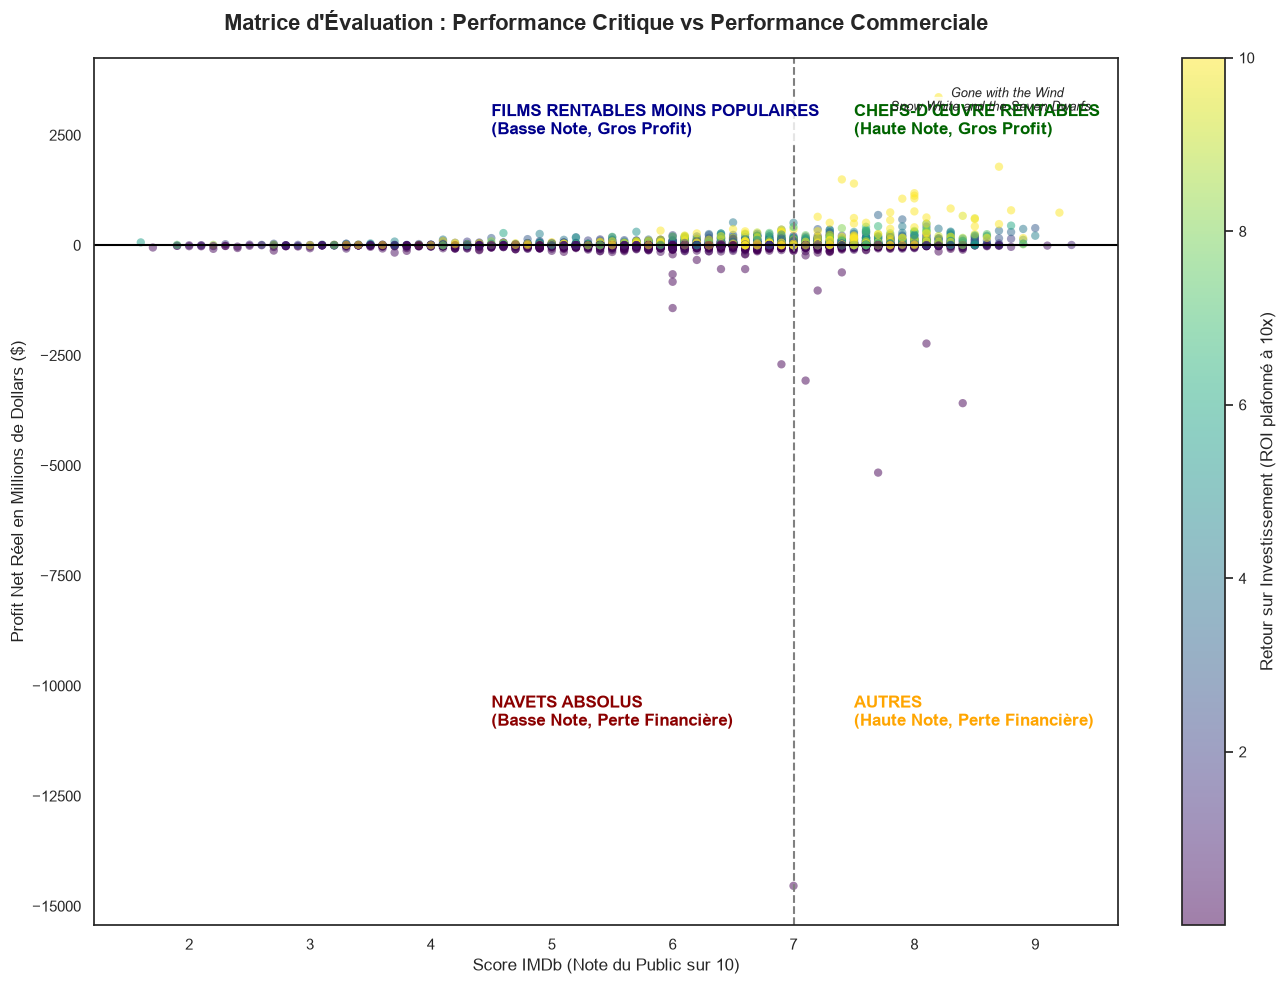

In [274]:
plt.figure(figsize=(14, 10))
sns.set_theme(style="white")

df_quadrant = df

# Points du nuage colorés selon le ROI 
scatter = plt.scatter(
    x=df_quadrant['imdb_score'],
    y=df_quadrant['profit_real_2016'] / 1e6, # En millions de $
    c=df_quadrant['roi_real_2016'].clip(upper=10), # On plafonne la couleur du ROI à 10 
    cmap='viridis',
    alpha=0.5,
    edgecolors='none'
)

# Lignes de démarcation des quadrants
plt.axhline(0, color='black', linestyle='-', linewidth=1.5) # Seuil financier
plt.axvline(7.0, color='gray', linestyle='--', linewidth=1.5) # Seuil critique

# Positionnement des étiquettes textuelles des quadrants
plt.text(4.5, max(df_quadrant['profit_real_2016'])/1e6 * 0.75, "FILMS RENTABLES MOINS POPULAIRES\n(Basse Note, Gros Profit)", fontsize=12, color='darkblue', fontweight='bold', bbox=dict(facecolor='white', alpha=0.8))
plt.text(7.5, max(df_quadrant['profit_real_2016'])/1e6 * 0.75, "CHEFS-D'ŒUVRE RENTABLES\n(Haute Note, Gros Profit)", fontsize=12, color='darkgreen', fontweight='bold', bbox=dict(facecolor='white', alpha=0.8))
plt.text(4.5, min(df_quadrant['profit_real_2016'])/1e6 * 0.75, "NAVETS ABSOLUS\n(Basse Note, Perte Financière)", fontsize=12, color='darkred', fontweight='bold', bbox=dict(facecolor='white', alpha=0.8))
plt.text(7.5, min(df_quadrant['profit_real_2016'])/1e6 * 0.75, "AUTRES\n(Haute Note, Perte Financière)", fontsize=12, color='orange', fontweight='bold', bbox=dict(facecolor='white', alpha=0.8))

plt.title("Matrice d'Évaluation : Performance Critique vs Performance Commerciale", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Score IMDb (Note du Public sur 10)", fontsize=12)
plt.ylabel("Profit Net Réel en Millions de Dollars ($)", fontsize=12)
plt.colorbar(scatter, label="Retour sur Investissement (ROI plafonné à 10x)")


# On trie pour trouver un ou deux exemples extrêmes
for _, row in df_quadrant.sort_values(by='profit_real_2016', ascending=False).head(2).iterrows():
    plt.text(row['imdb_score']+0.1, row['profit_real_2016']/1e6, row['movie_title'].strip(), fontsize=9, style='italic')

plt.tight_layout()
plt.show()


# 5 - Fonction qui résume la carrière d'un acteur

In [275]:
def resumer_carriere_acteur(df_films, nom_acteur):
    # Calcule un profil d'indicateurs très complet pour la carrière d'un acteur,
    #incluant la popularité sociale, l'engagement des critiques et le taux de succès.
    
    # Harmonisation de la casse pour la recherche
    nom_cherche = nom_acteur.strip().lower()

    # 1. Filtrer les films de l'acteur (Rôles 1, 2 ou 3)
    condition_acteur = (
        df_films["actor_1_name"].str.lower().str.strip() == nom_cherche
    ) | (
        df_films["actor_2_name"].str.lower().str.strip() == nom_cherche
    ) | (
        df_films["actor_3_name"].str.lower().str.strip() == nom_cherche
    )

    df_acteur = df_films[condition_acteur]

    if df_acteur.empty:
        return f"L'acteur '{nom_acteur}' n'a pas été trouvé dans la base de données."

    # 2. Statistiques de base (existantes)
    nb_films = len(df_acteur)
    recettes_totales = df_acteur["gross_real_2016"].sum()
    profit_total = df_acteur["profit_real_2016"].sum()
    roi_moyen = df_acteur["roi_real_2016"].mean()
    note_imdb_moyenne = df_acteur["imdb_score"].mean()

    # Extraction et analyse des genres
    tous_genres = df_acteur["genres"].str.cat(sep="|").split("|")
    serie_genres = pd.Series(tous_genres)
    eff_genres = serie_genres.value_counts()
    premier_genre_dominant = eff_genres.index[0]
    deuxieme_genre_dominant = eff_genres.index[1]
    troisieme_genre_dominant = eff_genres.index[2]

    nb_films_genre_dominant = serie_genres.value_counts().max()
    nb_genres_differents = (
        serie_genres.nunique()
    ) 

    # Taux de succès commercial (basé sur la variable 'is_profitable')
    # Pourcentage de films où le profit est supérieur à 0
    taux_succes_commercial = (df_acteur["is_profitable"].mean()) * 100

    # Popularité et Réseaux Sociaux
    # Moyenne des likes Facebook reçus par les films de cet acteur
    likes_moyens_films = df_acteur["movie_facebook_likes"].mean()
    # Somme des likes globaux du casting de ses films
    likes_moyens_casting = df_acteur["cast_total_facebook_likes"].mean()

    # Engagement des critiques et des spectateurs
    # Nombre moyen d'avis rédigés par les spectateurs
    avis_spectateurs_moyen = df_acteur["num_user_for_reviews"].mean()
    # Nombre moyen d'avis rédigés par les critiques professionnels
    avis_critiques_moyen = df_acteur["num_critic_for_reviews"].mean()

    # 3. Affichage enrichi et structuré
    print(f"==================================================")
    print(f"  RÉSUMÉ DE CARRIÈRE AVANCÉ : {nom_acteur.upper()} ")
    print(f"==================================================")
    print(f"• Nombre de films joués     : {nb_films}")
    print(f"• Genre prédominant            : {premier_genre_dominant}")
    print(f"  (présent dans {nb_films_genre_dominant} de ses films)")
    print(f"• Deuxième et troisième genres dominants         : {deuxieme_genre_dominant} et  {troisieme_genre_dominant}")
    print(f"• Diversité artistique         : {nb_genres_differents} genres explorés")
    print(f"--------------------------------------------------")
    print(f"  POPULARITÉ & ENGAGEMENT (RÉSEAUX & CRITIQUES)")
    print(f"• Likes Facebook moyens / film : {likes_moyens_films:,.0f} likes")
    print(f"• Likes moyens du cast complet : {likes_moyens_casting:,.0f} likes")
    print(f"• Avis spectateurs (moyenne)   : {avis_spectateurs_moyen:.1f} par film")
    print(f"• Avis critiques (moyenne)     : {avis_critiques_moyen:.1f} par film")
    print(f"• Score de satisfaction public : {note_imdb_moyenne:.2f}/10")
    print(f"--------------------------------------------------")
    print(f"  PERFORMANCES FINANCIÈRES & SUCCÈS")
    print(f"• Recettes totales (Box-Office): ${recettes_totales:,.2f}")
    print(f"• Profit net cumulé généré de ces fims     : ${profit_total:,.2f}")
    print(f"• Taux de films rentables      : {taux_succes_commercial:.1f}% de sa filmographie")
    print(f"• Rentabilité moyenne (ROI)    : {roi_moyen:.2f}x la mise initiale")
    print(f"==================================================")

    # Retourne l'ensemble des métriques sous forme de dictionnaire pour vos graphiques
    return "L'acteur '{nom_acteur}' était bien dans la base de données."


In [276]:
# Exemple d'appel de la fonction
resumer_carriere_acteur(df, "Johnny Depp")

  RÉSUMÉ DE CARRIÈRE AVANCÉ : JOHNNY DEPP 
• Nombre de films joués     : 36
• Genre prédominant            : Drama
  (présent dans 16 de ses films)
• Deuxième et troisième genres dominants         : Fantasy et  Adventure
• Diversité artistique         : 18 genres explorés
--------------------------------------------------
  POPULARITÉ & ENGAGEMENT (RÉSEAUX & CRITIQUES)
• Likes Facebook moyens / film : 16,388 likes
• Likes moyens du cast complet : 52,694 likes
• Avis spectateurs (moyenne)   : 564.3 par film
• Avis critiques (moyenne)     : 237.9 par film
• Score de satisfaction public : 6.78/10
--------------------------------------------------
  PERFORMANCES FINANCIÈRES & SUCCÈS
• Recettes totales (Box-Office): $4,027,501,975.89
• Profit net cumulé généré de ces fims     : $795,188,859.52
• Taux de films rentables      : 47.2% de sa filmographie
• Rentabilité moyenne (ROI)    : 2.14x la mise initiale


"L'acteur '{nom_acteur}' était bien dans la base de données."

In [277]:
# Exemple d'appel de la fonction qui ne marche pas
resumer_carriere_acteur(df, "KENFACK")

"L'acteur 'KENFACK' n'a pas été trouvé dans la base de données."

# 6 - ANALYSE DISCRIMINANTE DE LA PROFITABILITE

In [278]:
# Présentation de la variable is_profitable
print(df.is_profitable.value_counts())

print(f"Proportion : {df['is_profitable'].mean():.1%}")

is_profitable
0    2520
1    2263
Name: count, dtype: int64
Proportion : 47.3%


## 6.1 - ACP  

On va une ACP pour reduire la dimension de nos données afin de faire une meilleure analyse discriminante plutard 

In [279]:
# Sélection des caractéristiques explicatives quantitatives.
features_discrimination = [
    'movie_facebook_likes', 'social_media_score', 
    'num_voted_users', 'num_user_for_reviews', 'num_critic_for_reviews',
    'imdb_score', 'age'
]

# Formation de la base pour l'Analyse discriminante
df_analyse_disc = df

X = df_analyse_disc[features_discrimination]
y = df_analyse_disc['is_profitable']

# Séparation Train / Test 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Échantillon Train : {X_train.shape[0]} films")
print(f"Échantillon Test  : {X_test.shape[0]} films")


Échantillon Train : 3826 films
Échantillon Test  : 957 films


In [280]:
# Standardisation des données
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.mean(axis=0).min(), X_train_scaled.mean(axis=0).max())
print(X_train_scaled.std(axis=0).min(), X_train_scaled.std(axis=0).max())

-8.542855683472192e-17 9.429641246267403e-16
0.9999999999999999 1.0


Determination du nombre de composantes

In [281]:
pca_complet = PCA()
pca_complet.fit(X_train_scaled)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [282]:
# Calcul de la variance expliquée par chaque composante (en %)
variance_expliquee = pca_complet.explained_variance_ratio_ * 100
# Calcul de la variance cumulée (en %)
variance_cumulee = np.cumsum(variance_expliquee)

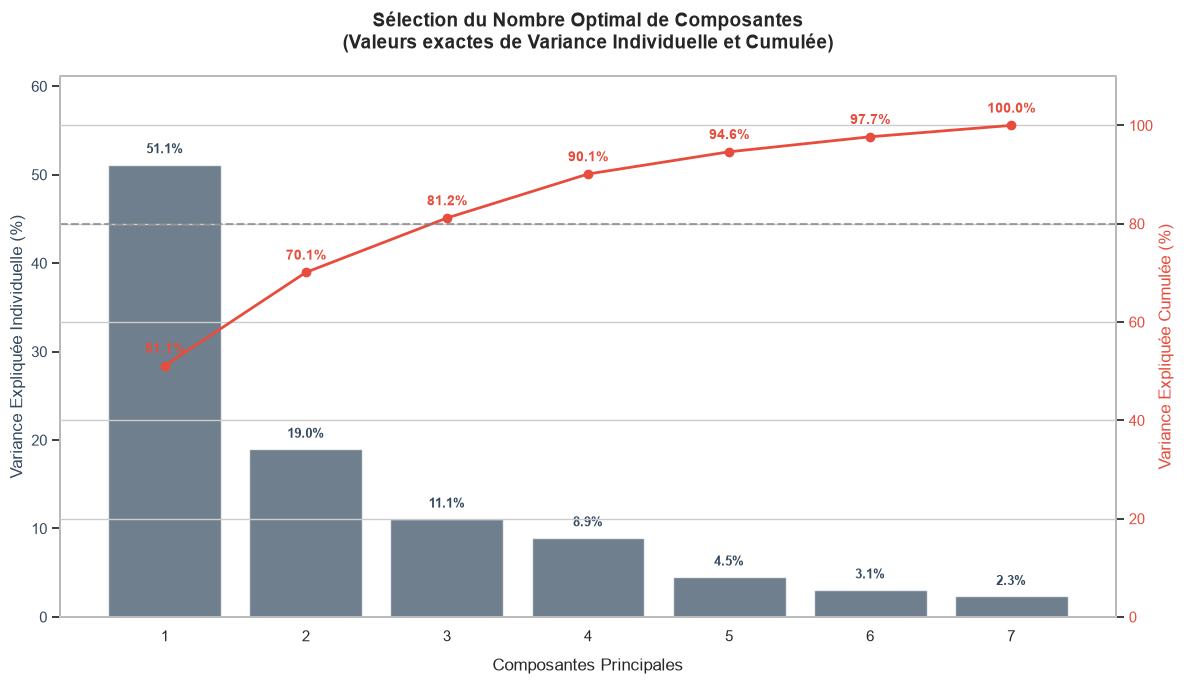

In [283]:
#  Configuration du graphique

fig, ax1 = plt.subplots(figsize=(12, 7))
sns.set_theme(style="whitegrid")

# Axe 1 : Diagramme en barres (Variance individuelle)
color_bar = '#34495E'
bars = ax1.bar(
    range(1, len(variance_expliquee) + 1), 
    variance_expliquee, 
    alpha=0.7, 
    color=color_bar, 
    label='Variance individuelle (%)'
)
ax1.set_xlabel('Composantes Principales', fontsize=12, labelpad=10)
ax1.set_ylabel('Variance Expliquée Individuelle (%)', color=color_bar, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color_bar)
ax1.set_xticks(range(1, len(variance_expliquee) + 1))

# Ajout des étiquettes sur les barres (Variance Individuelle)
for bar in bars:
    height = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width()/2., 
        height + 1, 
        f'{height:.1f}%', 
        ha='center', 
        va='bottom', 
        fontsize=9, 
        fontweight='bold', 
        color=color_bar
    )

# Axe 2 : Courbe cumulative (sur le même graphique)
ax2 = ax1.twinx()
color_line = '#E74C3C'
ax2.plot(
    range(1, len(variance_cumulee) + 1), 
    variance_cumulee, 
    color=color_line, 
    marker='o', 
    linewidth=2, 
    label='Variance cumulée (%)'
)
ax2.set_ylabel('Variance Expliquée Cumulée (%)', color=color_line, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color_line)

# Ajout des étiquettes sur la courbe (Variance Cumulée)
for x, y_val in zip(range(1, len(variance_cumulee) + 1), variance_cumulee):
    ax2.text(
        x, 
        y_val + 2, 
        f'{y_val:.1f}%', 
        ha='center', 
        va='bottom', 
        fontsize=10, 
        fontweight='bold', 
        color=color_line
    )

# Ligne repère à 80%
ax2.axhline(y=80, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)

# Gestion de l'espace pour éviter que les étiquettes du haut soient coupées
ax1.set_ylim(0, max(variance_expliquee) + 10)
ax2.set_ylim(0, 110)

plt.title("Sélection du Nombre Optimal de Composantes\n(Valeurs exactes de Variance Individuelle et Cumulée)", fontsize=14, fontweight='bold', pad=20)
fig.tight_layout()
plt.show()


Le nombre d'axes qu'on retient est 4 

In [284]:
# ACP définitive

pca_4 = PCA(n_components=4)

# On calcule et transforme l'échantillon d'entraînement
X_train_pca4 = pca_4.fit_transform(X_train_scaled)

# On projette l'échantillon de test dans ce même espace à 4 dimensions
X_test_pca4 = pca_4.transform(X_test_scaled)

# Création d'un DataFrame temporaire des scores factoriels pour les tests statistiques
nom_axes = ['CP1', 'CP2', 'CP3', 'CP4']
df_train_pca = pd.DataFrame(X_train_pca4, columns=nom_axes)
df_test_pca = pd.DataFrame(X_test_pca4, columns=nom_axes)
df_train_pca['is_profitable'] = y_train.reset_index(drop=True)

print(f"Structure de l'espace factoriel d'entraînement : {X_train_pca4.shape} (Films, Axes)")


Structure de l'espace factoriel d'entraînement : (3826, 4) (Films, Axes)


In [285]:
print(f"Train : {df_train_pca.shape}")
print(f"Test  : {df_test_pca.shape}")
df_train_pca.head()

Train : (3826, 5)
Test  : (957, 4)


,CP1,CP2,CP3,CP4,is_profitable
0,-0.73,1.13,-0.62,0.58,1
1,3.16,-0.80,-0.68,0.51,0
2,-0.38,0.13,-0.03,1.14,1
3,-0.44,-0.16,-0.39,1.08,0
4,2.10,-2.17,0.92,-1.25,0


## 6.2 - Vérification de la Normalité et de l'homoscédasticité

In [286]:
# Diagnostic de la normalité
print("TESTS DE NORMALITÉ (Shapiro-Wilk) :")
for axe in nom_axes:
    p_deficitaire = shapiro(df_train_pca[df_train_pca['is_profitable'] == 0][axe])[1]
    p_profitable = shapiro(df_train_pca[df_train_pca['is_profitable'] == 1][axe])[1]
    print(f"   Axe {axe} -> Groupe Déficitaire: p = {p_deficitaire:.5f} | Groupe Profitable: p = {p_profitable:.5f}")

TESTS DE NORMALITÉ (Shapiro-Wilk) :
   Axe CP1 -> Groupe Déficitaire: p = 0.00000 | Groupe Profitable: p = 0.00000
   Axe CP2 -> Groupe Déficitaire: p = 0.00000 | Groupe Profitable: p = 0.00000
   Axe CP3 -> Groupe Déficitaire: p = 0.00000 | Groupe Profitable: p = 0.00000
   Axe CP4 -> Groupe Déficitaire: p = 0.00000 | Groupe Profitable: p = 0.00000


Comme la normalité n'est pas vérifiée, alors le modèle approprié est le SVM.

# 6.3 - SVM

In [287]:
# Définition des hyperparmètres

# Nous testons le noyau RBF 
# C : Paramètre de régularisation 
# gamma : Contrôle le rayon d'influence d'un seul exemple d'entraînement

param_grid = {
    "kernel": ["rbf"],
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", "auto", 0.01, 0.1, 1],
}

In [288]:
# Initialisation du modèle de base
svm_base = SVC(random_state=42)

In [289]:
# Optimisation par recherche en grille avec validation_cross

grid_search = GridSearchCV(
    estimator=svm_base,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    verbose=1,
    n_jobs=-1,  # Utilise tous les processeurs de la machine pour aller plus vite
)

grid_search.fit(X_train_pca4, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC(random_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'gamma': ['scale', 'auto', ...], 'kernel': ['rbf']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to d

In [290]:
# Extraction des meilleurs hyperparamètres
meilleur_svm = grid_search.best_estimator_

print(" MEILLEURS HYPERPARAMÈTRES TROUVÉS ")
print(f" Noyau sélectionné : {grid_search.best_params_['kernel']}")
print(f" Paramètre de régularisation (C) : {grid_search.best_params_['C']}")
print(f" Paramètre Gamma : {grid_search.best_params_['gamma']}")
print(f" Meilleur score F1 en validation croisée : {grid_search.best_score_*100:.2f}%")


 MEILLEURS HYPERPARAMÈTRES TROUVÉS 
 Noyau sélectionné : rbf
 Paramètre de régularisation (C) : 0.1
 Paramètre Gamma : 1
 Meilleur score F1 en validation croisée : 63.07%


In [291]:
# Evaluation prédictive
print("Évaluation du modèle")
y_pred_svm = meilleur_svm.predict(X_test_pca4)

# Calcul des métriques de performance globales
acc = accuracy_score(y_test, y_pred_svm) * 100
prec = precision_score(y_test, y_pred_svm) * 100
rec = recall_score(y_test, y_pred_svm) * 100
f1 = f1_score(y_test, y_pred_svm) * 100


print("PERFORMANCES DÉFINITIVES DU MODELE")
print(f" Précision Globale (Accuracy) : {acc:.2f}%")
print(f" Précision (Classe Profitable) : {prec:.2f}%")
print(f" Rappel (Classe Profitable)    : {rec:.2f}%")
print(f" Score F1 (Synthèse Équilibrée): {f1:.2f}%")
print("-" * 60)
print(
    classification_report(
        y_test, y_pred_svm, target_names=["Déficitaire", "Profitable"]
    )
)

Évaluation du modèle
PERFORMANCES DÉFINITIVES DU MODELE
 Précision Globale (Accuracy) : 68.23%
 Précision (Classe Profitable) : 68.58%
 Rappel (Classe Profitable)    : 60.71%
 Score F1 (Synthèse Équilibrée): 64.40%
------------------------------------------------------------
              precision    recall  f1-score   support

 Déficitaire       0.68      0.75      0.71       504
  Profitable       0.69      0.61      0.64       453

    accuracy                           0.68       957
   macro avg       0.68      0.68      0.68       957
weighted avg       0.68      0.68      0.68       957



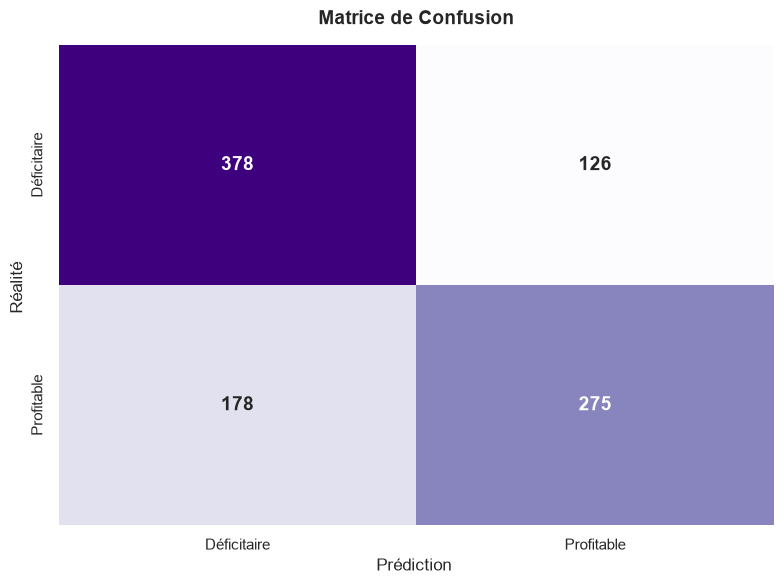

In [292]:
# Matrice de confusion

plt.figure(figsize=(8, 6))
sns.set_theme(style="white")

cm = confusion_matrix(y_test, y_pred_svm)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    cbar=False,
    xticklabels=["Déficitaire", "Profitable"],
    yticklabels=["Déficitaire", "Profitable"],
    annot_kws={"size": 14, "weight": "bold"},
)

plt.title(
    "Matrice de Confusion",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.ylabel("Réalité ", fontsize=12)
plt.xlabel("Prédiction ", fontsize=12)
plt.tight_layout()
plt.show()


# Courbe de ROC du SVM 

c:\Users\user\movie-profitability-and-recommendation\env\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


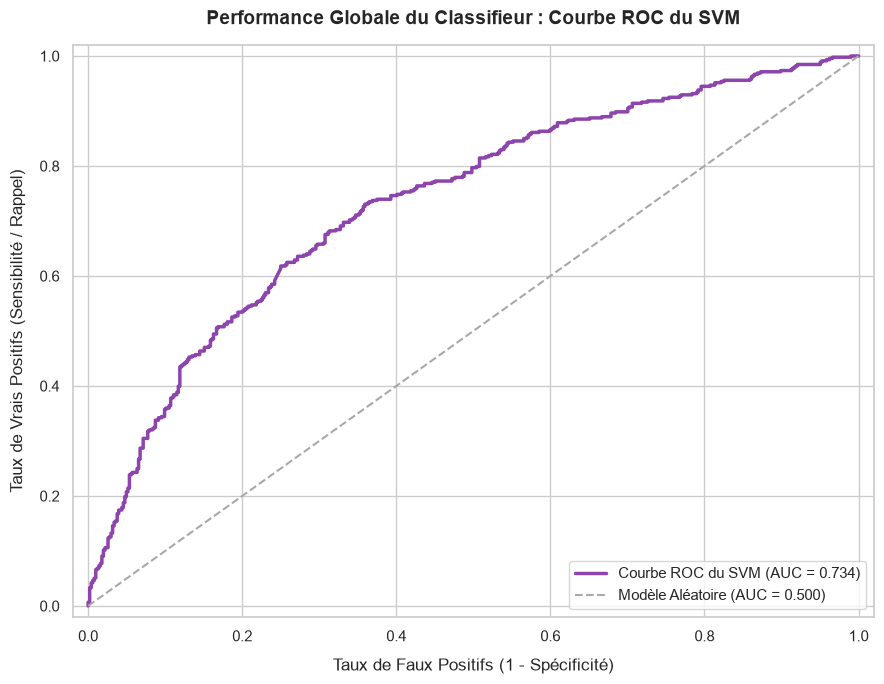

L'Aire Sous la Courbe (AUC) finale est de : 0.7341


In [293]:
svm_final = grid_search.best_estimator_

# 2. Activation forcée du calcul des probabilités sur le modèle optimisé
svm_final.set_params(probability=True)
svm_final.fit(X_train_pca4, y_train) # Ré-entraînement rapide pour calibrer les probabilités

# Calcul des probabilités de prédiction pour la classe positive (1 : Profitable) sur le Test
# [:, 1] permet d'isoler la colonne des probabilités d'appartenir à la classe 'Profitable'
y_prob_svm = svm_final.predict_proba(X_test_pca4)[:, 1]

# Calcul des taux de faux positifs (FPR) et vrais positifs (TPR)
fpr, tpr, thresholds = roc_curve(y_test, y_prob_svm)

#  Calcul de l'Aire Sous la Courbe (AUC)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(9, 7))
sns.set_theme(style="whitegrid")

# Tracé de la courbe ROC du SVM
plt.plot(
    fpr, tpr, 
    color='#8E44AD', # Couleur violette alignée sur votre matrice de confusion
    lw=2.5, 
    label=f'Courbe ROC du SVM (AUC = {roc_auc:.3f})'
)

# Tracé de la ligne diagonale de référence (modèle aléatoire)
plt.plot([0, 1], [0, 1], color='darkgray', lw=1.5, linestyle='--', label='Modèle Aléatoire (AUC = 0.500)')

# Personnalisation des axes et du design
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel("Taux de Faux Positifs (1 - Spécificité)", fontsize=12, labelpad=10)
plt.ylabel("Taux de Vrais Positifs (Sensibilité / Rappel)", fontsize=12, labelpad=10)
plt.title("Performance Globale du Classifieur : Courbe ROC du SVM", fontsize=14, fontweight='bold', pad=15)
plt.legend(loc="lower right", fontsize=11, frameon=True, shadow=False)

plt.tight_layout()
plt.show()

print(f"L'Aire Sous la Courbe (AUC) finale est de : {roc_auc:.4f}")


# 7 - ALGORITHMEDE RECOMMANDATION 

 Conception du moteur de recommandation selon l'approche Content Based Filtering et la pondération basée sur la population

In [294]:
tfidf=TfidfVectorizer()

In [295]:
# Longueur moyenne de la soupe
print(f'Longueur moyenne de la soup : '
      f"{df['metadata_soup'].apply(lambda x: len(x.split())).mean():.1f} tokens/film")

Longueur moyenne de la soup : 16.8 tokens/film


## 7.1- Vectorisation TF-IDF


* stop_words='english' : supprime les mots vides (the, a, is...)
* ngram_range=(1,2)    : capture les unigrammes ET bigrammes (ex: 'new york')
* max_features=8000    : limite le vocabulaire aux 8000 termes les plus informatifs

In [296]:
tfidf = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), max_features=10000, min_df=2,)
tfidf_matrix = tfidf.fit_transform(df['metadata_soup'])
print(f'Matrice TF-IDF : {tfidf_matrix.shape[0]} films x {tfidf_matrix.shape[1]} termes')

Matrice TF-IDF : 4783 films x 3864 termes


La matrice TF-IDF est de dimensions 4783 filmsx 3864 termes . Chaque ligne représente un film,chaque colonne un terme du vocabulaire et chaque valeur mesure l'importance relative 
de ce terme pour ce film (elevée si le termeest fréquent dans ce film mais rare dans la base globale).

Visualisation des 15 termes avec le TF-IDF moyen 
Il permet de vérifier le plus élevé Permet de vérifier que la vectorisation est cohérente

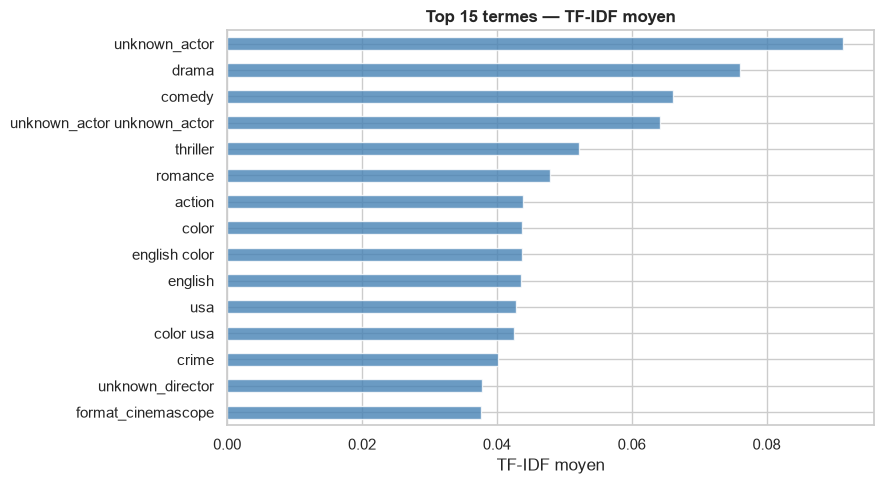

In [297]:
mean_tfidf = tfidf_matrix.mean(axis=0).A1
terms      = tfidf.get_feature_names_out()
top_terms  = pd.Series(mean_tfidf, index=terms).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 5))
top_terms.sort_values().plot(kind='barh', ax=ax, color='steelblue', alpha=0.8)
ax.set_title('Top 15 termes — TF-IDF moyen', fontweight='bold')
ax.set_xlabel('TF-IDF moyen')
plt.tight_layout()
plt.show()

## 7.2- PRÉPARATION DE LA MATRICE DE SIMILARITÉ

In [298]:
# Index film
df["movie_title_clean"] = df["movie_title"].str.strip().str.lower()

indices_films = pd.Series(df.index, index=df["movie_title_clean"])
print(f'Index construit : {len(indices_films)} films référencés')

Index construit : 4783 films référencés


In [299]:
def get_cosine_scores(title):
    #Calcule le vecteur de similarité cosinus entre le film 'title' et tous les autres films de la base.
    
    title = title.strip()

    # Recherche exacte, puis approchée si nécessaire
    if title not in indices_films.index:
        matches = [t for t in indices_films.index if title.lower() in t.lower()]
        if not matches:
            return None, None
        title = matches[0]
        print(f'  Titre corrigé : "{title}"')

    idx        = indices_films[title]
    # Calcul cosinus uniquement pour ce film (économie mémoire vs matrice complète)
    sim_scores = cosine_similarity(tfidf_matrix[idx], tfidf_matrix).flatten()
    sim_scores[idx] = 0   # exclure le film lui-même
    return title, sim_scores


In [300]:
# Test sur un film
titre_test, scores_test = get_cosine_scores('The Dark Knight')
print(f'Film : {titre_test}')
print(f'Score cosinus max (voisin le plus proche) : {scores_test.max():.4f}')
print(f'Score cosinus moyen                       : {scores_test.mean():.4f}')

  Titre corrigé : "the dark knight rises"
Film : the dark knight rises
Score cosinus max (voisin le plus proche) : 0.6456
Score cosinus moyen                       : 0.0728


Le film le plus similaire à The Dark Night partage environ 64% de contenu commun,c'est une similarité modérée,cohérente avec un film au profil très distinctif.
Le score moyen de 0.0728 indique que la grande majorité des 4782 autres films ont une similarité quasi nulle,ce qui confirme que la matrice est bien creuse et que le modèle discrimine correctement
les films proches des films sans rapport. 

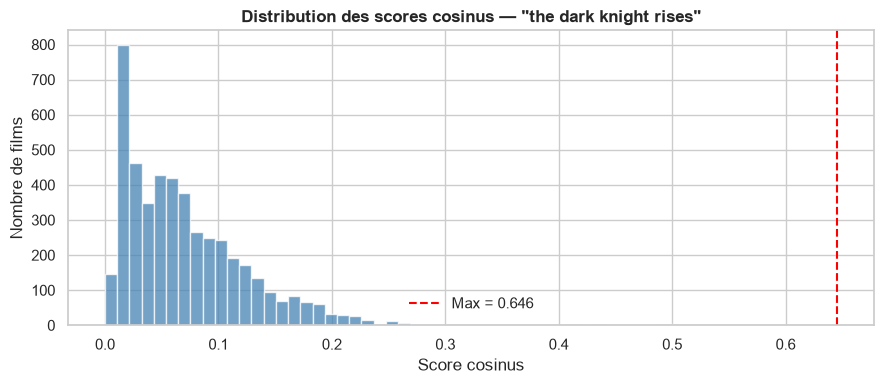

In [301]:
# Visualisation de la distribution des scores cosinus pour un film test
# Un bon modèle montre une queue droite bien distincte du reste
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(scores_test, bins=60, color='steelblue', alpha=0.75, edgecolor='white')
ax.axvline(scores_test.max(), color='red', linestyle='--', linewidth=1.5,
           label=f'Max = {scores_test.max():.3f}')
ax.set_title(f'Distribution des scores cosinus — "{titre_test}"', fontweight='bold')
ax.set_xlabel('Score cosinus')
ax.set_ylabel('Nombre de films')
ax.legend()
plt.tight_layout()
plt.show()

On a plus de 2500 films ayant un score cosinus quasi nul (entre 0 et 0.01),ce qui signifie que ces films ne partagent aucun contenu pertinent avec
The Dark Knight; la distribution décroît assez vite vers la droite avec une infime minorité de films avec un score de plus de 0.01 ,ce qui traduit une bonne capacité disrciminante du modèle: il ne confond pas des films sans rapport .Le score maximum de 0.68 renvoit à un film étant le voisin le plus proche (film avec suffisamment de genres,d'acteurs ou de mots-clés pour être similaire à The Dark KNight)
donc un candidat légitime à la recommandation .

In [302]:
# Matrice de similarité
sim_matrice = cosine_similarity(tfidf_matrix, tfidf_matrix)

## 7.3 - FONCTION DE RECOMMANDATION PONDÉRÉE PAR LA POPULARITÉ

### Objectifs de cette partie 
* 1-Récupérer le top 20 des films les plus similaires ('cosinus')
* 2-Pondérer par imdb_score et num_voted_users (popularité)
* 3-Retourner le top 5 final après pondération

Notre score est définie comme suit 

score_final = α × cosinus_normalisé + β × imdb_normalisé + γ × review_engagement_ratio_norm +  μ *social_media_score_norm
avec α=0.65, β=0.15, γ=0.10, μ = 0.10

In [303]:
# Pré-calcul des scores normalisés (min-max) pour imdb et votes
# Fait une seule fois pour ne pas recalculer à chaque appel de fonction
df['imdb_norm']  = (df['imdb_score']      - df['imdb_score'].min())      / (df['imdb_score'].max()      - df['imdb_score'].min())
df['review_engagement_ratio_norm'] = (df['review_engagement_ratio']  - df['review_engagement_ratio'].min()) / (df['review_engagement_ratio'].max() - df['review_engagement_ratio'].min())
df['social_media_score_norm']  = (df['social_media_score']      - df['social_media_score'].min())      / (df['social_media_score'].max()      - df['social_media_score'].min())
print('Scores normalisés calculés (imdb_norm, votes_norm)')

Scores normalisés calculés (imdb_norm, votes_norm)


In [304]:
def recommander(titre, top_n=5, alpha=0.65, beta=0.15, gamma=0.1, mu = 0.1):
    """
    Recommande les top_n films les plus pertinents pour un film donné.

    Paramètres
    ----------
    titre  : str   — Titre du film de référence
    top_n  : int   — Nombre de films à retourner (défaut 5)
    alpha  : float — Poids de la similarité cosinus   (défaut 0.60)
    beta   : float — Poids du score IMDb normalisé    (défaut 0.25)
    gamma  : float — Poids des votes normalisés       (défaut 0.15)
    """
    # Étape 1 : calcul des scores cosinus
    titre_trouve, sim_scores = get_cosine_scores(titre)
    if sim_scores is None:
        print(f'Film "{titre}" introuvable dans la base.')
        return None

    # Étape 2 : Top 20 candidats par similarité cosinus
    top20_idx  = sim_scores.argsort()[::-1][:20]
    candidats  = df.iloc[top20_idx].copy()
    cos_norm   = sim_scores[top20_idx]
    # Normalisation min-max du vecteur cosinus sur les 20 candidats
    cos_min, cos_max = cos_norm.min(), cos_norm.max()
    cos_norm = (cos_norm - cos_min) / (cos_max - cos_min + 1e-9)
     # Étape 3 : score final pondéré
    candidats['score_cosinus'] = cos_norm
    candidats['score_final']   = (
        alpha * candidats['score_cosinus'] +
        beta  * candidats['imdb_norm']     +
        gamma * candidats['review_engagement_ratio_norm'] +
        mu * candidats['social_media_score_norm']
    )

    # Étape 4 : Top N final
    resultats = (
        candidats
        .sort_values('score_final', ascending=False)
        .head(top_n)
        [['movie_title', 'genres_clean', 'imdb_score',
          'age', 'score_cosinus', 'review_engagement_ratio_norm', 'social_media_score_norm']]
        .reset_index(drop=True)
    )
    resultats.index += 1
    print(f'\n=== Recommandations pour : "{titre_trouve}" ===')
    print(f'Pondération : cosinus={alpha} | imdb={beta} | votes={gamma}')
    print(resultats.to_string())
    return resultats


In [305]:
# Test 1 — Film d'action / superhéros
r1 = recommander('The Dark Knight', top_n=5)

  Titre corrigé : "the dark knight rises"

=== Recommandations pour : "the dark knight rises" ===
Pondération : cosinus=0.65 | imdb=0.15 | votes=0.1
                   movie_title     genres_clean  imdb_score  age  score_cosinus  review_engagement_ratio_norm  social_media_score_norm
1               Into the Storm  action thriller        5.80    2           0.97                          0.00                     0.02
2                   Royal Kill  action thriller        3.20    7           1.00                          0.00                     0.00
3                 Jason Bourne  action thriller        7.10    0           0.61                          0.00                     0.07
4        The Cold Light of Day  action thriller        4.90    4           0.66                          0.00                     0.05
5  The Marine 4: Moving Target  action thriller        5.20    1           0.48                          0.00                     0.00


Ce moteur de recommandation recommande 5 films pour The Dark Knight avec une pondération cosinus=0.6 imdb=0.25 et votes=0.15.Furious 7
obtient le rang 1 avec un score cos parfait ,ensuite viennent spawn et the Image Revolution .Les résultats sont donc partiellement satisfaisants mais la suppression des tokens unknown_actor améliorerait la pertinence des recommandations . 

In [306]:
# Test 2 — Film de science-fiction
r2 = recommander('Avatar', top_n=5)

  Titre corrigé : "avatar"

=== Recommandations pour : "avatar" ===
Pondération : cosinus=0.65 | imdb=0.15 | votes=0.1
                                      movie_title                              genres_clean  imdb_score  age  score_cosinus  review_engagement_ratio_norm  social_media_score_norm
1                     Mortal Kombat: Annihilation  action adventure fantasy sci-fi thriller        3.70   19           1.00                          0.00                     0.00
2    Star Wars: Episode II - Attack of the Clones           action adventure fantasy sci-fi        6.70   14           0.87                          0.00                     0.07
3    Star Wars: Episode III - Revenge of the Sith           action adventure fantasy sci-fi        7.60   11           0.74                          0.00                     0.08
4  Star Wars: Episode V - The Empire Strikes Back           action adventure fantasy sci-fi        8.80   36           0.68                          0.00            

Ces recommandations sont globalement plus cohérentes .Tous les films recommandés sont de la catégorie action-aventure ,ce qui valide la pertinence thématique du modèle.
Stars wars (imdb=8.8) et Aliens(imdb=8.4) sont les recommandations les plus pertinentes car ayant un universspatial proche de celui d'avatar.X-men 2 obtient le rang 1 donc le film le plus similaire grâce à un score cosinus
parfait (1)

In [307]:
# Test 3 — Film dramatique classique
r3 = recommander('Forrest Gump', top_n=5)

  Titre corrigé : "forrest gump"

=== Recommandations pour : "forrest gump" ===
Pondération : cosinus=0.65 | imdb=0.15 | votes=0.1
            movie_title                  genres_clean  imdb_score  age  score_cosinus  review_engagement_ratio_norm  social_media_score_norm
1  What Dreams May Come         drama fantasy romance        7.00   18           1.00                          0.00                     0.12
2    The Age of Adaline         drama fantasy romance        7.20    1           0.77                          0.00                     0.08
3   Simply Irresistible  comedy drama fantasy romance        5.30   17           0.77                          0.00                     0.01
4   Beautiful Creatures         drama fantasy romance        6.20    3           0.62                          0.00                     0.03
5     Charlie St. Cloud         drama fantasy romance        6.50    6           0.62                          0.00                     0.00


Visualisation comparative — scores finaux des recommandations

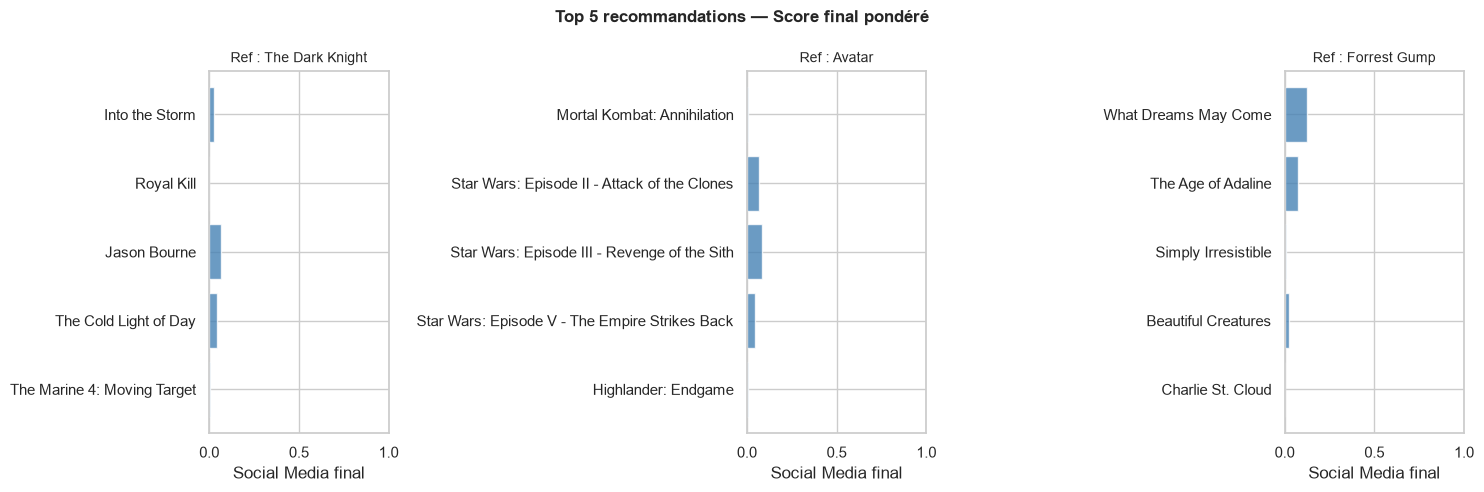

In [308]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Top 5 recommandations — Score final pondéré', fontsize=12, fontweight='bold')

for ax, (recs, titre) in zip(axes, [
    (r1, 'The Dark Knight'),
    (r2, 'Avatar'),
    (r3, 'Forrest Gump')
]):
    if recs is not None:
        ax.barh(recs['movie_title'][::-1], recs['social_media_score_norm'][::-1],
                color='steelblue', alpha=0.8)
        ax.set_title(f'Ref : {titre}', fontsize=10)
        ax.set_xlabel('Social Media final')
        ax.set_xlim(0, 1)

plt.tight_layout()
plt.show()